# BDB27 — Combine **warm-up phenotype** → in-game **ramping** (Kaggle notebook)

Self-contained: no CLI, no `git clone`. All modules are embedded below (single source of truth) and run in order `02 → 03b → 03d → 00 → 04 → 05`.

**Reframe (D25).** The pre-registered fatigue-slope→game-decay link is GATED OFF (D20: combine fatigue-slope reliability 0.0). The viable link is **reliable combine warm-up phenotypes → in-game ramping**. The warm-up de-confounding was NOT robust (D24) ⇒ the link is **EXPLORATORY**, clearly labelled. Sample outputs carry `UNVALIDATED SAMPLE OUTPUT`.


## 1. PARAMS — set inputs here

`MODE` = `SAMPLE` (a small, non-representative prefix; **never interpret/tune on it**) or `FULL` (the real run). On Kaggle, point `INPUT_DIR` at your attached dataset and list the raw filenames.

In [1]:
import os, sys, json, subprocess
from pathlib import Path

# ---- user parameters -------------------------------------------------------
MODE = 'SAMPLE'          # 'SAMPLE' | 'FULL'
INPUT_DIR = None         # None -> <repo>/data/raw ; on Kaggle set '/kaggle/input/<dataset>'
FILES = {
    'combine_tracking': 'combine_tracking.csv',
    'combine_results':  'combine_results.csv',
    'players':          'players.csv',
    'games':            'games.csv',
    'player_play':      'player_play.csv',
    'game_tracking_sample': 'game_tracking_2023_sample.csv',
    'game_tracking_full': ['game_tracking_2023.csv', 'game_tracking_2024.csv', 'game_tracking_2025.csv'],
}
# ---------------------------------------------------------------------------

mode = MODE.lower()
CWD = Path.cwd()
if Path('/kaggle/working').exists():
    WORK = Path('/kaggle/working')
elif (CWD / '..' / 'src').exists():
    WORK = CWD.parent                       # local run from notebooks/
else:
    WORK = CWD
os.chdir(WORK)
SRC = WORK / 'src'
SRC.mkdir(parents=True, exist_ok=True)
(WORK / 'outputs').mkdir(parents=True, exist_ok=True)

# data/raw -> INPUT_DIR (symlink on Kaggle; local repo already has it)
if INPUT_DIR is not None:
    raw = WORK / 'data' / 'raw'
    raw.parent.mkdir(parents=True, exist_ok=True)
    if not raw.exists():
        os.symlink(INPUT_DIR, raw)
(WORK / 'data' / 'interim' / 'parquet').mkdir(parents=True, exist_ok=True)

print('WORK =', WORK)
print('mode =', mode, '| FILES.game_tracking_sample =', FILES['game_tracking_sample'])


WORK = /home/conormalone/.openclaw/workspace/BDB27
mode = sample | FILES.game_tracking_sample = game_tracking_2023_sample.csv


## 2. Install only what is missing

`pandas`/`numpy`/`scikit-learn`/`statsmodels`/`scipy`/`matplotlib` exist in the Kaggle base image; only `duckdb`/`pyarrow` may need installing.

In [2]:
import importlib.util
for _m in ['duckdb', 'pyarrow']:
    if importlib.util.find_spec(_m) is None:
        print('installing', _m)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _m], check=False)
print('imports ok')


imports ok


## 3. Embed the pipeline (single source of truth)

Each module below is written verbatim into `src/`.

In [3]:
%%writefile src/common.py
"""Shared utilities for the BDB27 pipeline.

Provides: config loading, path resolution, structured logging, a peak-RAM /
wall-time run-logger, deterministic seeding, provenance strings, and a
memory-safe CSV->Parquet converter (DuckDB streaming).

Design rules (TASK.md):
- Never load full CSVs into pandas; convert to Parquet then query with DuckDB.
- Explicit column selection; params come from config.yaml (no magic numbers).
- Every stage appends wall time + peak RAM to outputs/run_log.csv.
"""

from __future__ import annotations

import csv
import logging
import os
import resource
import time
from contextlib import contextmanager
from pathlib import Path
from typing import Any, Iterable, Sequence

import duckdb
import numpy as np
import yaml

REPO_ROOT: Path = Path(__file__).resolve().parent.parent
DEFAULT_CONFIG: Path = REPO_ROOT / "config.yaml"

_LOGGER_NAME = "bdb27"


# --------------------------------------------------------------------------- #
# Config
# --------------------------------------------------------------------------- #
def load_config(path: str | os.PathLike | None = None) -> dict[str, Any]:
    """Load config.yaml (defaults to the repo-root config)."""
    cfg_path = Path(path) if path else DEFAULT_CONFIG
    with open(cfg_path, "r", encoding="utf-8") as fh:
        cfg = yaml.safe_load(fh)
    cfg["_config_path"] = str(cfg_path)
    return cfg


def resolve(cfg: dict[str, Any], key: str, extra: str | None = None) -> Path:
    """Resolve a path from cfg['paths'][key] (optionally joined with `extra`)."""
    base = REPO_ROOT / cfg["paths"][key]
    return base if extra is None else base / extra


def get_logger(level: int = logging.INFO) -> logging.Logger:
    """Return a process-wide console logger."""
    logger = logging.getLogger(_LOGGER_NAME)
    if not logger.handlers:
        h = logging.StreamHandler()
        h.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        logger.addHandler(h)
    logger.setLevel(level)
    return logger


def provenance(cfg: dict[str, Any], mode: str) -> str:
    """Return the provenance label for a run mode ('UNVALIDATED SAMPLE OUTPUT'|'FULL')."""
    return str(cfg["mode"][mode]["provenance"])


def seed_everything(seed: int) -> None:
    """Seed numpy (and stdlib) RNGs for determinism."""
    np.random.seed(seed)
    import random

    random.seed(seed)


# --------------------------------------------------------------------------- #
# Peak RAM + wall time
# --------------------------------------------------------------------------- #
def peak_ram_mb() -> float:
    """Process peak resident set size in MiB (Linux ru_maxrss is in KiB)."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0


@contextmanager
def timed_stage(cfg: dict[str, Any], stage: str, mode: str, **notes: Any):
    """Context manager: time a stage and append a row to outputs/run_log.csv."""
    t0 = time.perf_counter()
    err: str = ""
    try:
        yield
    except Exception as exc:  # log then re-raise so failures are visible
        err = f"{type(exc).__name__}: {exc}"
        raise
    finally:
        wall_s = time.perf_counter() - t0
        append_run_log(cfg, stage, mode, wall_s, peak_ram_mb(), err, notes)


def append_run_log(
    cfg: dict[str, Any],
    stage: str,
    mode: str,
    wall_s: float,
    peak_mb: float,
    err: str = "",
    notes: dict[str, Any] | None = None,
) -> None:
    """Append one row to the run log (header written on first use)."""
    log_path = REPO_ROOT / cfg["logging"]["run_log"]
    log_path.parent.mkdir(parents=True, exist_ok=True)
    fields = ["timestamp", "stage", "mode", "wall_s", "peak_ram_mb", "error", "notes"]
    notes = notes or {}
    note_str = "; ".join(f"{k}={v}" for k, v in notes.items())
    write_header = not log_path.exists()
    with open(log_path, "a", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=fields)
        if write_header:
            w.writeheader()
        w.writerow(
            {
                "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"),
                "stage": stage,
                "mode": mode,
                "wall_s": round(wall_s, 3),
                "peak_ram_mb": round(peak_mb, 1),
                "error": err,
                "notes": note_str,
            }
        )


# --------------------------------------------------------------------------- #
# I/O: CSV -> Parquet (memory-safe, streamed by DuckDB)
# --------------------------------------------------------------------------- #
def connect(threads: int | None = None) -> duckdb.DuckDBPyConnection:
    """Open a DuckDB connection with a bounded thread count."""
    con = duckdb.connect()
    if threads is not None:
        con.execute(f"PRAGMA threads={int(threads)}")
    return con


def csv_path(cfg: dict[str, Any], key_or_name: str) -> Path:
    """Resolve a CSV path: if `key_or_name` is under cfg['files'], use that value."""
    name = cfg["files"].get(key_or_name, key_or_name)
    return resolve(cfg, "raw", name)


def to_parquet(
    con: duckdb.DuckDBPyConnection,
    src_csv: Path,
    dst_parquet: Path,
    columns: Sequence[str] | None = None,
    force: bool = False,
    logger: logging.Logger | None = None,
    nullstr: Sequence[str] | None = ("NA", ""),
) -> Path:
    """Convert a CSV to Parquet via DuckDB COPY (streamed, low memory).

    Skips when `dst_parquet` exists unless `force=True` (checkpointing).
    `nullstr` maps placeholder tokens to SQL NULL; the BDB CSVs use "NA" for
    opted-out / unavailable values, which must NOT be kept as literal strings.
    """
    dst_parquet.parent.mkdir(parents=True, exist_ok=True)
    if dst_parquet.exists() and not force:
        if logger:
            logger.info("parquet cache hit: %s", dst_parquet.name)
        return dst_parquet
    if not src_csv.exists():
        raise FileNotFoundError(f"missing source CSV: {src_csv}")
    cols = "*" if not columns else ", ".join(f'"{c}"' for c in columns)
    opts = "header=true"
    if nullstr:
        opts += ", nullstr=[" + ", ".join(f"'{s}'" for s in nullstr) + "]"
    sql = (
        f"COPY (SELECT {cols} FROM read_csv_auto('{src_csv}', {opts})) "
        f"TO '{dst_parquet}' (FORMAT PARQUET, COMPRESSION ZSTD)"
    )
    if logger:
        logger.info("converting %s -> %s", src_csv.name, dst_parquet.name)
    con.execute(sql)
    return dst_parquet


def pq(path: Path) -> str:
    """Return a DuckDB read_parquet() call string for `path`."""
    return f"read_parquet('{path}')"


# --------------------------------------------------------------------------- #
# Small helpers
# --------------------------------------------------------------------------- #
def write_csv(path: Path, rows: Iterable[dict[str, Any]], fieldnames: Sequence[str] | None = None) -> None:
    """Write an iterable of row dicts to CSV."""
    path.parent.mkdir(parents=True, exist_ok=True)
    rows = list(rows)
    if not rows and fieldnames is None:
        raise ValueError(f"cannot infer header for empty table: {path}")
    fields = list(fieldnames) if fieldnames else list(rows[0].keys())
    with open(path, "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=fields)
        w.writeheader()
        for r in rows:
            w.writerow(r)


Overwriting src/common.py


In [4]:
%%writefile src/02_features.py
"""Phase 2 — Combine features for the BDB27 combine-fatigue study.

Per attempt (one observed ``event_id`` = one attempt), computed from ``x``/``y``/
``time`` only (the provided ``s``/``a``/``dis`` are kept as *advisory*
cross-checks, never trusted):

- peak speed, peak signed acceleration, time above ``t90_frac`` of the player's
  best (within the configured baseline level), and effort cost (path distance);
- session splitting, within-session ordering, cumulative prior load (distance +
  count of maximal efforts; observed + imputed);
- rest time from the clock (accounting for imputed attempts);
- lost-attempt (numbering-gap) imputation — load only, flagged, no performance;
- within-(level, position) standardisation of the primary metric and companions;
- ``first_attempt`` and its collinearity with load (VIF).

Design is locked by decisions **D16-D18** (``notes/decisions.md``); every
threshold/path/param comes from ``config.yaml`` (no magic numbers). Combine data
is complete and fits in RAM, so features are computed for real in BOTH modes; the
mode only changes the provenance label. Features are computed for ALL positions
(cheap) and the DB study subset is emitted separately for the Phase-3 handoff.

Run:
    python src/02_features.py --mode sample
    python src/02_features.py --mode sample --force

Outputs (``outputs/features/``):
    combine_features.parquet          per attempt (observed + imputed), ALL positions
    combine_features_study.parquet    in-study-population subset (Phase-3 handoff)
    combine_features_player.parquet   per-player summary
    feature_diagnostics.csv           long key/value diagnostics
    standardization_params.csv        (n, mean, sd) per (level, position, metric)
    vif_report.csv                    VIF of {prior_load_yd, first_attempt}
    PROVENANCE.txt, SUMMARY.md
"""

from __future__ import annotations

import argparse
import sys
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    csv_path,
    get_logger,
    load_config,
    peak_ram_mb,
    pq,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
    to_parquet,
)

COMBINE_TRACKING_COLS = [
    "draft_year", "event_id", "nfl_id", "entity_type", "time",
    "drill_type", "drill_name", "attempt", "x", "y", "s", "a", "dis", "dir",
]
COMBINE_RESULTS_COLS = [
    "draft_year", "nfl_id", "combine_position", "combine_height", "combine_weight",
    "hand_size", "arm_length", "wing_span", "ten_yd_split", "forty", "vertical",
    "broad_jump", "three_cone", "short_shuttle", "bench_reps",
    "ngs_athleticism_score", "ngs_college_production_score", "ngs_final_score",
]

# Output column order — MUST match the Phase-2 spec exactly (and provenance first
# for the CSVs; the parquet also carries the ``provenance`` column).
COLUMNS: list[tuple[str, str]] = [
    ("provenance", "VARCHAR"),
    ("nfl_id", "INTEGER"),
    ("draft_year", "INTEGER"),
    ("combine_position", "VARCHAR"),
    ("in_study_population", "BOOLEAN"),
    ("drill_type", "VARCHAR"),
    ("drill_name", "VARCHAR"),
    ("attempt", "INTEGER"),
    ("attempt_unit", "VARCHAR"),
    ("event_id", "VARCHAR"),
    ("is_imputed", "INTEGER"),
    ("session_id", "VARCHAR"),
    ("attempt_start_time", "TIMESTAMP"),
    ("attempt_end_time", "TIMESTAMP"),
    ("elapsed_session_s", "FLOAT"),
    ("n_frames", "INTEGER"),
    ("n_gaps", "INTEGER"),
    ("max_gap_s", "FLOAT"),
    ("peak_speed_yds", "FLOAT"),
    ("peak_accel_yds2", "FLOAT"),
    ("t90_s", "FLOAT"),
    ("effort_cost_yd", "FLOAT"),
    ("best_speed_yds", "FLOAT"),
    ("prior_load_yd", "FLOAT"),
    ("prior_load_efforts", "INTEGER"),
    ("prior_load_observed_yd", "FLOAT"),
    ("prior_load_observed_efforts", "INTEGER"),
    ("perf_z", "FLOAT"),
    ("peak_accel_z", "FLOAT"),
    ("t90_z", "FLOAT"),
    ("effort_cost_z", "FLOAT"),
    ("first_attempt", "INTEGER"),
    ("rest_s", "FLOAT"),
    ("rest_spans_imputed", "INTEGER"),
    ("impute_source", "VARCHAR"),
    ("flag_gap_in_peak_speed_window", "INTEGER"),
    ("flag_gap_in_peak_accel_window", "INTEGER"),
    ("flag_speed_outlier", "INTEGER"),
    ("flag_duplicate_attempt", "INTEGER"),
    ("flag_out_of_order", "INTEGER"),
    ("flag_large_gap", "INTEGER"),
    ("flag_std_group_too_small", "INTEGER"),
    ("advisory_provided_dis_sum", "FLOAT"),
    ("advisory_provided_peak_s", "FLOAT"),
    ("advisory_provided_peak_a", "FLOAT"),
]

PLAYER_COLUMNS: list[tuple[str, str]] = [
    ("provenance", "VARCHAR"),
    ("nfl_id", "INTEGER"),
    ("draft_year", "INTEGER"),
    ("combine_position", "VARCHAR"),
    ("in_study_population", "BOOLEAN"),
    ("n_attempts_total", "INTEGER"),
    ("n_attempts_observed", "INTEGER"),
    ("n_attempts_imputed", "INTEGER"),
    ("n_sessions", "INTEGER"),
    ("n_drill_types", "INTEGER"),
    ("n_drill_names", "INTEGER"),
    ("max_peak_speed_yds", "FLOAT"),
    ("total_effort_yd_observed", "FLOAT"),
    ("first_session_start", "TIMESTAMP"),
    ("last_attempt_end", "TIMESTAMP"),
]

METRICS = ["peak_speed_yds", "peak_accel_yds2", "t90_s", "effort_cost_yd"]
Z_COLUMN = {
    "peak_speed_yds": "perf_z",
    "peak_accel_yds2": "peak_accel_z",
    "t90_s": "t90_z",
    "effort_cost_yd": "effort_cost_z",
}


# --------------------------------------------------------------------------- #
# Pure helpers (importable by tests — no pipeline state)
# --------------------------------------------------------------------------- #
def zscore_group(values, min_n: int):
    """Z-score (ddof=0) within a group. Returns (z, ok).

    ``ok`` is False (and ``z`` all-NaN) when the group is too small
    (``n < min_n``) or degenerate (sd == 0 — standardisation is undefined).
    """
    v = np.asarray(values, dtype=np.float64)
    mask = np.isfinite(v)
    n = int(mask.sum())
    if n < int(min_n):
        return np.full(v.shape, np.nan, dtype=np.float64), False
    mu = float(v[mask].mean())
    sd = float(v[mask].std(ddof=0))
    if not np.isfinite(sd) or sd == 0.0:
        return np.full(v.shape, np.nan, dtype=np.float64), False
    z = np.full(v.shape, np.nan, dtype=np.float64)
    z[mask] = (v[mask] - mu) / sd
    return z, True


def missing_attempt_numbers(observed, max_attempt: int) -> list[int]:
    """Attempt numbers in {1..max_attempt} that were NOT observed (lost data)."""
    have = {int(a) for a in observed}
    return [a for a in range(1, int(max_attempt) + 1) if a not in have]


def detect_attempt_unit(attempts: pd.DataFrame, min_restart_drill_names: int) -> pd.DataFrame:
    """Empirically detect the `attempt` numbering unit per `(nfl_id, drill_type)` block (D19).

    A block is a **per-`drill_name` restart** unit (`attempt_unit='drill_name'`) iff it has
    **>= 2 distinct `drill_name`s AND >= ``min_restart_drill_names`` of them have
    ``min(attempt) == 1``**; otherwise it is a **per-`drill_type` block counter**
    (`attempt_unit='drill_type'`). Single-`drill_name` blocks are unit-invariant
    (grouping by `drill_name` == grouping by `drill_type`) and are reported as
    ``'drill_type'``.

    ``attempts`` is the observed attempt-level frame with
    ``nfl_id, drill_type, drill_name, attempt``. Returns one row per
    ``(nfl_id, drill_type)`` with columns
    ``nfl_id, drill_type, attempt_unit, n_drill_names, n_drill_names_starting_at_1``.
    """
    thr = int(min_restart_drill_names)
    rows: list[dict[str, Any]] = []
    for (nfl, dtyp), grp in attempts.groupby(["nfl_id", "drill_type"], sort=True):
        starts = grp.groupby("drill_name")["attempt"].min()
        n_dn = int(starts.size)
        n_start1 = int((starts.astype(int) == 1).sum())
        unit = "drill_name" if (n_dn >= 2 and n_start1 >= thr) else "drill_type"
        rows.append({
            "nfl_id": int(nfl),
            "drill_type": str(dtyp),
            "attempt_unit": unit,
            "n_drill_names": n_dn,
            "n_drill_names_starting_at_1": n_start1,
        })
    return pd.DataFrame(rows, columns=[
        "nfl_id", "drill_type", "attempt_unit", "n_drill_names", "n_drill_names_starting_at_1"])


def _imputed_drill_name(grp: pd.DataFrame, m: int) -> str:
    """The `drill_name` for an imputed attempt `m`: of the observed rep with the
    largest ``attempt < m`` (fallback: smallest ``attempt > m``; final fallback: the
    group's `drill_name`)."""
    below = grp[grp["attempt"].astype(int) < int(m)]
    if len(below):
        return str(below.loc[below["attempt"].idxmax(), "drill_name"])
    above = grp[grp["attempt"].astype(int) > int(m)]
    if len(above):
        return str(above.loc[above["attempt"].idxmin(), "drill_name"])
    return str(grp["drill_name"].iloc[0])


def resolve_attempt_units(attempts: pd.DataFrame, cfg: dict[str, Any]) -> dict[tuple[int, str], str]:
    """Map every ``(nfl_id, drill_type)`` block to its numbering unit.

    ``features.attempt_level``: ``empirical`` (default) runs the D19 detection;
    ``drill_name`` / ``drill_type`` force a fixed unit for every block (tests /
    sensitivity). The detection is always run once so diagnostics can report the
    *detected* block counts; only the returned assignment depends on the mode.
    """
    level = str(cfg["features"]["attempt_level"])
    det = detect_attempt_unit(attempts, int(cfg["features"]["attempt_restart_min_drill_names"]))
    unit_map = {(int(n), str(t)): str(u)
                for n, t, u in zip(det["nfl_id"], det["drill_type"], det["attempt_unit"])}
    if level != "empirical":
        assert level in ("drill_name", "drill_type"), f"unknown features.attempt_level: {level}"
        unit_map = {k: level for k in unit_map}
    return unit_map


def kinematics_for_attempt(t, x, y, params: dict) -> dict:
    """Per-attempt kinematics from x/y/time (observed frames only).

    Frames must be ordered by time. Returns per-attempt metrics, the sanity /
    gap flags, and the refined segment arrays (``seg_dt``, ``seg_dist``,
    ``seg_v``, ``seg_a``, ``seg_counted``) used for the t90 pass.

    Frame gaps: a segment is a *gap* when ``dt > gap_detect_factor*expected_dt``.
    Gaps inside the peak-speed segment or the peak-accel window are flagged and
    left RAW (never interpolated). ELSEWHERE, gaps shorter than
    ``interp_max_gap_s`` are linearly interpolated onto the expected grid; gaps
    >= ``interp_max_gap_s`` are NOT interpolated — their segment is excluded from
    distance/speed/accel and sets ``flag_large_gap``.
    """
    t = np.asarray(t, dtype=np.float64)
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    n = t.size
    res = {
        "n_frames": int(n),
        "n_gaps": np.nan,
        "max_gap_s": np.nan,
        "peak_speed_yds": np.nan,
        "peak_accel_yds2": np.nan,
        "effort_cost_yd": np.nan,
        "flag_gap_in_peak_speed_window": 0,
        "flag_gap_in_peak_accel_window": 0,
        "flag_large_gap": 0,
        "seg_dt": np.array([], dtype=np.float64),
        "seg_dist": np.array([], dtype=np.float64),
        "seg_v": np.array([], dtype=np.float64),
        "seg_a": np.array([], dtype=np.float64),
        "seg_counted": np.array([], dtype=bool),
    }
    if n < 2:
        return res

    exp = float(params["expected_dt_s"])
    gap_thr = exp * float(params["gap_detect_factor"])
    interp_max = float(params["interp_max_gap_s"])

    dt = np.diff(t)
    dist = np.hypot(np.diff(x), np.diff(y))
    with np.errstate(divide="ignore", invalid="ignore"):
        v = np.where(dt > 0, dist / dt, np.nan)
    a = np.full(dt.shape, np.nan, dtype=np.float64)
    if dt.size >= 2:
        denom = (dt[1:] + dt[:-1]) / 2.0
        with np.errstate(divide="ignore", invalid="ignore"):
            a[1:] = np.where(denom > 0, (v[1:] - v[:-1]) / denom, np.nan)

    gap = dt > gap_thr
    res["n_gaps"] = int(gap.sum())
    res["max_gap_s"] = float(dt.max())

    fv = np.isfinite(v)
    ips = int(np.argmax(np.where(fv, v, -np.inf))) if fv.any() else -1
    fa = np.isfinite(a)
    ipa = int(np.argmax(np.where(fa, a, -np.inf))) if fa.any() else -1

    peak_segs: set[int] = set()
    accel_window: set[int] = set()
    if ips >= 0:
        peak_segs.add(ips)
    if ipa >= 0:
        accel_window.add(ipa)
        if ipa - 1 >= 0:
            accel_window.add(ipa - 1)
    res["flag_gap_in_peak_speed_window"] = int(ips >= 0 and bool(gap[ips]))
    res["flag_gap_in_peak_accel_window"] = int(
        len(accel_window) > 0 and any(bool(gap[k]) for k in accel_window)
    )

    # ---- rebuild the trajectory: interpolate acceptable gaps elsewhere ----
    peakwin = peak_segs | accel_window
    rt: list[float] = [float(t[0])]
    rx: list[float] = [float(x[0])]
    ry: list[float] = [float(y[0])]
    counted: list[bool] = [True]  # placeholder for point 0 (no segment)
    for k in range(dt.size):
        dk = float(dt[k])
        if dk >= interp_max:
            rt.append(float(t[k + 1])); rx.append(float(x[k + 1])); ry.append(float(y[k + 1]))
            counted.append(False)
            res["flag_large_gap"] = 1
        elif gap[k]:
            if k in peakwin:
                # never interpolate inside the peak window: keep the raw segment
                rt.append(float(t[k + 1])); rx.append(float(x[k + 1])); ry.append(float(y[k + 1]))
                counted.append(True)
            else:
                m = int(round(dk / exp)) if exp > 0 else 1
                if m <= 1:
                    rt.append(float(t[k + 1])); rx.append(float(x[k + 1])); ry.append(float(y[k + 1]))
                    counted.append(True)
                else:
                    for j in range(1, m):
                        frac = j / m
                        rt.append(float(t[k]) + frac * dk)
                        rx.append(float(x[k]) + frac * (float(x[k + 1]) - float(x[k])))
                        ry.append(float(y[k]) + frac * (float(y[k + 1]) - float(y[k])))
                        counted.append(True)
                    rt.append(float(t[k + 1])); rx.append(float(x[k + 1])); ry.append(float(y[k + 1]))
                    counted.append(True)
        else:
            rt.append(float(t[k + 1])); rx.append(float(x[k + 1])); ry.append(float(y[k + 1]))
            counted.append(True)

    rt_a = np.asarray(rt, dtype=np.float64)
    rx_a = np.asarray(rx, dtype=np.float64)
    ry_a = np.asarray(ry, dtype=np.float64)
    seg_counted = np.asarray(counted, dtype=bool)[1:]

    rdt = np.diff(rt_a)
    rdist = np.hypot(np.diff(rx_a), np.diff(ry_a))
    with np.errstate(divide="ignore", invalid="ignore"):
        rv = np.where(rdt > 0, rdist / rdt, np.nan)
    ra = np.full(rdt.shape, np.nan, dtype=np.float64)
    if rdt.size >= 2:
        rden = (rdt[1:] + rdt[:-1]) / 2.0
        with np.errstate(divide="ignore", invalid="ignore"):
            ra[1:] = np.where(rden > 0, (rv[1:] - rv[:-1]) / rden, np.nan)

    # exclude uncounted segments from speed/accel/distance
    rv = np.where(seg_counted, rv, np.nan)
    valid = seg_counted & np.isfinite(rv)
    if ra.size:
        ok = valid.copy()
        ok[0] = False
        ok[1:] = ok[1:] & valid[:-1]
        ra = np.where(ok, ra, np.nan)

    fv2 = np.isfinite(rv)
    res["peak_speed_yds"] = float(np.max(rv[fv2])) if fv2.any() else np.nan
    fa2 = np.isfinite(ra)
    res["peak_accel_yds2"] = float(np.max(ra[fa2])) if fa2.any() else np.nan
    # effort counts only segments with dt <= distance_gap_max_s (post-interpolation)
    distmax = float(params["distance_gap_max_s"])
    res["effort_cost_yd"] = float(np.sum(rdist[seg_counted & (rdt <= distmax)]))
    res["seg_dt"] = rdt
    res["seg_dist"] = rdist
    res["seg_v"] = rv
    res["seg_a"] = ra
    res["seg_counted"] = seg_counted
    return res


# --------------------------------------------------------------------------- #
# Data loading (DuckDB over Parquet; explicit columns)
# --------------------------------------------------------------------------- #
def _frame_params(cfg: dict[str, Any]) -> dict[str, Any]:
    f = cfg["features"]
    return {
        "expected_dt_s": float(f["expected_dt_s"]),
        "gap_detect_factor": float(f["gap_detect_factor"]),
        "interp_max_gap_s": float(f["interp_max_gap_s"]),
        "distance_gap_max_s": float(f["distance_gap_max_s"]),
        "peak_speed_sanity_yds": float(f["peak_speed_sanity_yds"]),
    }


def load_frames(con, T: str) -> dict[str, np.ndarray]:
    """Fetch PLAYER frames (x/y/time + ids) ordered by (event_id, time)."""
    sql = f"""
        SELECT event_id, nfl_id, draft_year, drill_type, drill_name, attempt,
               epoch_ms(time) / 1000.0 AS t_s, x, y, s, a, dis
        FROM {T}
        WHERE entity_type = 'PLAYER'
        ORDER BY event_id, t_s
    """
    return con.execute(sql).fetchnumpy()


def compute_attempt_kinematics(frames: dict[str, np.ndarray], params: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Loop over observed attempts; return (attempt-level, segment-level) frames."""
    ev = frames["event_id"]
    nfl = frames["nfl_id"]
    dy = frames["draft_year"]
    dtyp = frames["drill_type"]
    dnam = frames["drill_name"]
    att = frames["attempt"]
    ts = frames["t_s"]
    xs = frames["x"]
    ys = frames["y"]

    uniq, starts, counts = np.unique(ev, return_index=True, return_counts=True)
    # np.unique returns first-occurrence indices; ev is sorted so groups are contiguous
    order = np.argsort(starts)
    uniq = uniq[order]
    starts = starts[order]
    counts = counts[order]
    ends = starts + counts

    att_rows: list[dict[str, Any]] = []
    seg_ev: list[np.ndarray] = []
    seg_ix: list[np.ndarray] = []
    seg_nfl: list[np.ndarray] = []
    seg_dt: list[np.ndarray] = []
    seg_di: list[np.ndarray] = []
    seg_v: list[np.ndarray] = []
    seg_a: list[np.ndarray] = []
    seg_co: list[np.ndarray] = []

    for g in range(uniq.size):
        a = int(starts[g]); b = int(ends[g])
        k = kinematics_for_attempt(ts[a:b], xs[a:b], ys[a:b], params)
        att_rows.append({
            "event_id": str(uniq[g]),
            "nfl_id": int(nfl[a]),
            "draft_year": int(dy[a]),
            "drill_type": str(dtyp[a]),
            "drill_name": str(dnam[a]),
            "attempt": int(att[a]),
            "n_frames": k["n_frames"],
            "n_gaps": k["n_gaps"],
            "max_gap_s": k["max_gap_s"],
            "peak_speed_yds": k["peak_speed_yds"],
            "peak_accel_yds2": k["peak_accel_yds2"],
            "effort_cost_yd": k["effort_cost_yd"],
            "flag_gap_in_peak_speed_window": k["flag_gap_in_peak_speed_window"],
            "flag_gap_in_peak_accel_window": k["flag_gap_in_peak_accel_window"],
            "flag_large_gap": k["flag_large_gap"],
            "flag_speed_outlier": int(
                np.isfinite(k["peak_speed_yds"])
                and k["peak_speed_yds"] > float(params["peak_speed_sanity_yds"])
            ),
        })
        ns = k["seg_dt"].size
        if ns:
            seg_ev.append(np.repeat(str(uniq[g]), ns))
            seg_ix.append(np.arange(ns, dtype=np.int32))
            seg_nfl.append(np.repeat(int(nfl[a]), ns))
            seg_dt.append(k["seg_dt"])
            seg_di.append(k["seg_dist"])
            seg_v.append(k["seg_v"])
            seg_a.append(k["seg_a"])
            seg_co.append(k["seg_counted"])

    attempt = pd.DataFrame(att_rows)
    if seg_ev:
        seg = pd.DataFrame({
            "event_id": np.concatenate(seg_ev),
            "seg_index": np.concatenate(seg_ix),
            "nfl_id": np.concatenate(seg_nfl),
            "dt_s": np.concatenate(seg_dt),
            "dist_yd": np.concatenate(seg_di),
            "v_yds": np.concatenate(seg_v),
            "a_yds2": np.concatenate(seg_a),
            "counted": np.concatenate(seg_co),
        })
    else:
        seg = pd.DataFrame(columns=["event_id", "seg_index", "nfl_id", "dt_s", "dist_yd", "v_yds", "a_yds2", "counted"])
    return attempt, seg


# --------------------------------------------------------------------------- #
# Stage: sessions / ordering / prior load / rest / imputation
# --------------------------------------------------------------------------- #
def _assign_sessions(obs: pd.DataFrame, gap_s: float) -> pd.Series:
    """session_id = f'{nfl_id}:{k}', k by start time, split on > gap_s inactivity."""
    out = pd.Series(index=obs.index, dtype="object")
    for nfl, grp in obs.sort_values(["nfl_id", "attempt_start_time"]).groupby("nfl_id", sort=True):
        t0 = grp["attempt_start_time"]
        gap = t0.diff().dt.total_seconds()
        k = (gap > gap_s).cumsum() + 1
        out.loc[grp.index] = [f"{int(nfl)}:{int(x)}" for x in k]
    return out


def _order_and_load(combined: pd.DataFrame, cfg: dict[str, Any]) -> pd.DataFrame:
    """Within-(player, session) ordering + cumulative prior load + rest time.

    Numbering unit (D19) is column ``attempt_unit``: `drill_name` for per-`drill_name`
    restart blocks, else `drill_type`. Order key = (``unit_first_start_rank``, ``attempt``),
    where ``unit_first_start_rank`` = within-(player, session) rank of the unit's min
    observed start time (ties by unit key).
    """
    session_gap_s = float(cfg["features"]["session_gap_s"])
    combined = combined.copy()
    observed = combined["is_imputed"] == 0
    combined["attempt_start_time"] = pd.to_datetime(combined["attempt_start_time"])
    combined["attempt_end_time"] = pd.to_datetime(combined["attempt_end_time"])

    # ---- numbering-unit key (D19): drill_name for restart units, else drill_type ----
    combined["unit_key"] = np.where(
        combined["attempt_unit"].to_numpy() == "drill_name",
        combined["drill_name"].to_numpy(), combined["drill_type"].to_numpy())

    # ---- session assignment (from observed start times) ----
    obs = combined.loc[observed, ["nfl_id", "attempt_start_time"]].copy()
    obs = obs.sort_values(["nfl_id", "attempt_start_time"])
    obs["session_id"] = _assign_sessions(obs, session_gap_s)
    combined["session_id"] = obs["session_id"]

    # imputed rows inherit the session of their (nfl_id, unit_key)'s observed attempts
    key_session = (combined.loc[observed]
                   .groupby(["nfl_id", "unit_key"], sort=False)["session_id"].first())
    imp_mask = ~observed
    if imp_mask.any():
        keys = list(zip(combined.loc[imp_mask, "nfl_id"], combined.loc[imp_mask, "unit_key"]))
        combined.loc[imp_mask, "session_id"] = [key_session.get(kk, None) for kk in keys]
    combined = combined[combined["session_id"].notna()].copy()
    observed = (combined["is_imputed"] == 0).to_numpy()

    # ---- unit_first_start_rank (D19) per (player, session) ----
    firsts = (combined.loc[observed]
              .groupby(["nfl_id", "session_id", "unit_key"], sort=True)["attempt_start_time"]
              .min().reset_index())
    firsts["unit_first_start_rank"] = (firsts
                                       .sort_values(["nfl_id", "session_id", "attempt_start_time", "unit_key"])
                                       .groupby(["nfl_id", "session_id"]).cumcount() + 1)
    rank_map = firsts.set_index(["nfl_id", "session_id", "unit_key"])["unit_first_start_rank"]
    combined["unit_first_start_rank"] = [
        rank_map.get((int(n), s, u), np.nan)
        for n, s, u in zip(combined["nfl_id"], combined["session_id"], combined["unit_key"])
    ]

    # ---- order within session and cumulative prior load ----
    # Key = (unit_first_start_rank, attempt, is_imputed, event_id) per spec (D19).
    combined = combined.sort_values(
        ["nfl_id", "session_id", "unit_first_start_rank", "attempt", "is_imputed", "event_id"]).copy()

    # ---- first_attempt (D19): 1 iff OBSERVED and the player's earliest observed rep
    # of that drill_name by attempt_start_time (ties -> min attempt); imputed rows = 0.
    obs_sorted = (combined.loc[combined["is_imputed"] == 0]
                  .sort_values(["nfl_id", "drill_name", "attempt_start_time", "attempt"]))
    first_idx = obs_sorted.groupby(["nfl_id", "drill_name"], sort=False).head(1).index
    combined["first_attempt"] = 0
    combined.loc[first_idx, "first_attempt"] = 1

    eff = combined["effort_cost_yd"].fillna(0.0)
    cum = eff.groupby(combined["session_id"], sort=False).cumsum()
    combined["prior_load_yd"] = cum - eff
    combined["prior_load_efforts"] = combined.groupby("session_id", sort=False).cumcount()
    obs_eff = pd.Series(np.where(combined["is_imputed"] == 0, eff.to_numpy(), 0.0), index=combined.index)
    combined["prior_load_observed_yd"] = obs_eff.groupby(combined["session_id"], sort=False).cumsum() - obs_eff
    obs_ind = (combined["is_imputed"] == 0).astype(int)
    combined["prior_load_observed_efforts"] = (
        obs_ind.groupby(combined["session_id"], sort=False).cumsum() - obs_ind)

    # ---- elapsed session time (observed only) ----
    obs_bool = combined["is_imputed"] == 0
    sess_start = combined.loc[obs_bool].groupby("session_id")["attempt_start_time"].min()
    combined["elapsed_session_s"] = np.where(
        obs_bool.to_numpy(),
        (combined["attempt_start_time"] - combined["session_id"].map(sess_start)).dt.total_seconds(),
        np.nan,
    )

    # ---- rest time (from the clock; accounting for imputed) ----
    combined["rest_s"] = np.nan
    combined["rest_spans_imputed"] = 0
    combined["order_index"] = np.arange(len(combined))
    for _, idx in combined.groupby("session_id", sort=False).groups.items():
        sub = combined.loc[idx]
        obs_rows = sub.loc[sub["is_imputed"] == 0].sort_values("attempt_start_time")
        imp_positions = set(sub.loc[sub["is_imputed"] == 1, "order_index"].tolist())
        prev_end = None
        prev_pos = None
        for _, row in obs_rows.iterrows():
            pos = int(row["order_index"])
            if prev_end is None:
                combined.at[row.name, "rest_s"] = np.nan
                combined.at[row.name, "rest_spans_imputed"] = 1  # session-first: no predecessor
            else:
                combined.at[row.name, "rest_s"] = float((row["attempt_start_time"] - prev_end).total_seconds())
                spans = any(prev_pos < p < pos for p in imp_positions)
                combined.at[row.name, "rest_spans_imputed"] = int(spans)
            prev_end = row["attempt_end_time"]
            prev_pos = pos
    combined = combined.drop(columns=["order_index"])
    return combined


def _impute_rows(attempts: pd.DataFrame, cfg: dict[str, Any],
                 unit_map: dict[tuple[int, str], str]) -> pd.DataFrame:
    """Lost-attempt (numbering-gap) rows: load only, flagged, no performance.

    The grouping (numbering) unit is per ``(nfl_id, drill_type)`` block and is chosen
    empirically per D19 (``unit_map`` from `resolve_attempt_units`): `drill_name` for
    per-`drill_name` restart blocks, else `drill_type`. Missing numbers
    ``m in {1..max(attempt)} \\ observed`` within the unit become rows with
    ``is_imputed=1``; `drill_name` of the imputed row = that of the nearest observed
    rep (largest ``attempt < m``, else smallest ``attempt > m``).
    """
    stat = str(cfg["features"].get("impute_stat", "median"))
    assert stat == "median", f"only impute_stat=median is implemented (got {stat})"
    rows: list[dict[str, Any]] = []
    # global (unit-level) medians (fallback) across all players
    med_dn = attempts.groupby("drill_name")["effort_cost_yd"].median()
    med_dt = attempts.groupby("drill_type")["effort_cost_yd"].median()
    for (nfl, dtyp), block in attempts.groupby(["nfl_id", "drill_type"], sort=True):
        unit = unit_map.get((int(nfl), str(dtyp)), "drill_type")
        if unit == "drill_name":
            groups = [(None, g) for _, g in block.groupby("drill_name", sort=True)]
        else:
            groups = [(None, block)]  # whole block = one numbering unit
        for _, grp in groups:
            have = grp["attempt"].astype(int).tolist()
            mx = int(max(have))
            for m in missing_attempt_numbers(have, mx):
                player_med = grp["effort_cost_yd"].median()
                if np.isfinite(player_med):
                    cost, src = float(player_med), "player_drill"
                else:
                    if unit == "drill_name":
                        g = med_dn.get(grp["drill_name"].iloc[0], np.nan)
                    else:
                        g = med_dt.get(str(dtyp), np.nan)
                    cost, src = (float(g) if np.isfinite(g) else np.nan), "drill_global"
                rows.append({
                    "event_id": None,
                    "nfl_id": int(nfl),
                    "draft_year": int(grp["draft_year"].iloc[0]),
                    "combine_position": grp["combine_position"].iloc[0],
                    "drill_type": grp["drill_type"].iloc[0],
                    "drill_name": _imputed_drill_name(grp, m),
                    "attempt": int(m),
                    "attempt_unit": unit,
                    "is_imputed": 1,
                    "effort_cost_yd": cost,
                    "impute_source": src,
                    "n_frames": np.nan, "n_gaps": np.nan, "max_gap_s": np.nan,
                    "peak_speed_yds": np.nan, "peak_accel_yds2": np.nan, "t90_s": np.nan,
                    "best_speed_yds": np.nan,
                    "flag_gap_in_peak_speed_window": 0, "flag_gap_in_peak_accel_window": 0,
                    "flag_large_gap": 0, "flag_speed_outlier": 0,
                    "flag_duplicate_attempt": 0, "flag_out_of_order": 0,
                    "flag_std_group_too_small": 0,
                    "advisory_provided_dis_sum": np.nan,
                    "advisory_provided_peak_s": np.nan,
                    "advisory_provided_peak_a": np.nan,
                    "attempt_start_time": pd.NaT, "attempt_end_time": pd.NaT,
                    "elapsed_session_s": np.nan, "rest_s": np.nan, "rest_spans_imputed": 0,
                })
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- #
# Stage: standardisation
# --------------------------------------------------------------------------- #
def _standardize(obs: pd.DataFrame, cfg: dict[str, Any]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Within (standardize_level, position) z-scores over observed attempts."""
    level = str(cfg["features"]["standardize_level"])
    min_n = int(cfg["features"]["min_std_group_n"])
    primary = str(cfg["features"]["performance_metric"])
    zmap = dict(Z_COLUMN)
    zmap[primary] = "perf_z"  # the configured primary metric maps to perf_z
    obs = obs.copy()
    obs["flag_std_group_too_small"] = 0
    params_rows: list[dict[str, Any]] = []
    for metric in METRICS:
        zcol = zmap[metric]
        obs[zcol] = np.nan
        for (lvl, pos), idx in obs.groupby([level, "combine_position"], sort=True).groups.items():
            vals = obs.loc[idx, metric].to_numpy()
            z, ok = zscore_group(vals, min_n)
            obs.loc[idx, zcol] = z
            if not ok:
                obs.loc[idx, "flag_std_group_too_small"] = 1
            finite = vals[np.isfinite(vals)]
            params_rows.append({
                "metric": metric,
                "standardize_level": level,
                "standardize_level_value": lvl,
                "position": pos,
                "n": int(finite.size),
                "mean": float(finite.mean()) if finite.size else np.nan,
                "sd": float(finite.std(ddof=0)) if finite.size else np.nan,
                "min_std_group_n": min_n,
                "group_ok": int(ok),
            })
    return obs, pd.DataFrame(params_rows)


# --------------------------------------------------------------------------- #
# Stage: VIF
# --------------------------------------------------------------------------- #
def _vif(study_obs: pd.DataFrame, cfg: dict[str, Any]) -> pd.DataFrame:
    thr = float(cfg["features"]["vif_flag_threshold"])
    d = study_obs[["prior_load_yd", "first_attempt"]].dropna()
    n = int(len(d))
    rows: list[dict[str, Any]] = []
    if n < 3 or d["prior_load_yd"].nunique() < 2 or d["first_attempt"].nunique() < 2:
        return pd.DataFrame([{
            "term": t, "vif": np.nan, "exceeds_threshold": 0, "n_obs": n,
            "vif_flag_threshold": thr,
        } for t in ["const", "prior_load_yd", "first_attempt"]] + [{
            "term": "corr(prior_load_yd,first_attempt)", "vif": np.nan,
            "exceeds_threshold": 0, "n_obs": n, "vif_flag_threshold": thr,
        }])
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    X = np.column_stack([np.ones(n), d["prior_load_yd"].to_numpy(), d["first_attempt"].to_numpy()])
    for i, term in enumerate(["const", "prior_load_yd", "first_attempt"]):
        v = float(variance_inflation_factor(X, i))
        rows.append({"term": term, "vif": v, "exceeds_threshold": int(v > thr),
                     "n_obs": n, "vif_flag_threshold": thr})
    corr = float(np.corrcoef(d["prior_load_yd"], d["first_attempt"])[0, 1])
    rows.append({"term": "corr(prior_load_yd,first_attempt)", "vif": corr,
                 "exceeds_threshold": 0, "n_obs": n, "vif_flag_threshold": thr})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- #
# Writing
# --------------------------------------------------------------------------- #
def _cast_select(columns: list[tuple[str, str]]) -> str:
    parts = []
    for name, typ in columns:
        if typ in ("INTEGER", "FLOAT"):
            parts.append(f'TRY_CAST("{name}" AS {typ}) AS "{name}"')
        else:
            parts.append(f'CAST("{name}" AS {typ}) AS "{name}"')
    return ",\n  ".join(parts)


def _write_parquet(con, df: pd.DataFrame, columns: list[tuple[str, str]], path: Path, order_by: str) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    view = "_feat_view"
    con.register(view, df[[c for c, _ in columns]])
    sql = (f"COPY (SELECT\n  {_cast_select(columns)}\n FROM {view}\n ORDER BY {order_by}) "
           f"TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.execute(sql)
    con.unregister(view)


def _labelled_csv(df: pd.DataFrame, prov: str, path: Path) -> None:
    out = df.copy()
    out.insert(0, "provenance", prov)
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(path, index=False)


# --------------------------------------------------------------------------- #
# Main pipeline
# --------------------------------------------------------------------------- #
def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    out_dir = resolve(cfg, "outputs", cfg["features"]["out_subdir"])
    feat_path = out_dir / "combine_features.parquet"

    logger.info("=" * 72)
    logger.info("BDB27 Phase 2 features | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    if feat_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force to rebuild)", feat_path.name)
        append_run_log(cfg, "02_features:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "combine_features.parquet exists; use --force"})
        return 0

    parq = resolve(cfg, "parquet")
    threads = int(cfg.get("runtime", {}).get("duckdb_threads", 1))
    con = connect(threads=threads)
    params = _frame_params(cfg)
    study_pop = str(cfg["audit"]["study_population"])
    t90_level = str(cfg["features"]["t90_baseline_level"])
    t90_frac = float(cfg["features"]["t90_frac"])

    with timed_stage(cfg, "02_features:convert", mode):
        to_parquet(con, csv_path(cfg, "combine_tracking"), parq / "combine_tracking.parquet",
                   COMBINE_TRACKING_COLS, force, logger)
        to_parquet(con, csv_path(cfg, "combine_results"), parq / "combine_results.parquet",
                   COMBINE_RESULTS_COLS, force, logger)
    T = pq(parq / "combine_tracking.parquet")
    R = pq(parq / "combine_results.parquet")

    # ---- position map + advisory + duplicate/out-of-order flags ----
    pos_map = (con.execute(f"SELECT nfl_id, any_value(combine_position) FROM {R} GROUP BY 1")
               .fetchdf().set_index("nfl_id")["any_value(combine_position)"].to_dict())
    advisory = (con.execute(f"""
        SELECT event_id, sum(dis) AS dis_sum, max(s) AS peak_s, max(a) AS peak_a
        FROM {T} WHERE entity_type='PLAYER' GROUP BY 1""").fetchdf().set_index("event_id"))
    dup_tuples = set(con.execute(f"""
        WITH g AS (SELECT nfl_id, drill_name, attempt, count(DISTINCT event_id) k
                   FROM {T} WHERE entity_type='PLAYER' GROUP BY 1,2,3)
        SELECT nfl_id, drill_name, attempt FROM g WHERE k > 1""").fetchall())
    ooo_tuples = set(con.execute(f"""
        WITH a AS (SELECT nfl_id, drill_name, attempt, min(time) t0
                   FROM {T} WHERE entity_type='PLAYER' GROUP BY 1,2,3),
             b AS (SELECT nfl_id, drill_name, attempt,
                          lag(attempt) OVER (PARTITION BY nfl_id, drill_name ORDER BY t0) pa
                   FROM a)
        SELECT DISTINCT nfl_id, drill_name FROM b
        WHERE pa IS NOT NULL AND attempt <= pa""").fetchall())
    se = con.execute(f"""SELECT event_id, min(time) AS st, max(time) AS en
                         FROM {T} WHERE entity_type='PLAYER' GROUP BY 1""").fetchdf().set_index("event_id")

    # ---- kinematics ----
    with timed_stage(cfg, "02_features:kinematics", mode):
        frames = load_frames(con, T)
        attempt, seg = compute_attempt_kinematics(frames, params)
        attempt["combine_position"] = attempt["nfl_id"].map(pos_map)
        attempt["attempt_start_time"] = attempt["event_id"].map(se["st"])
        attempt["attempt_end_time"] = attempt["event_id"].map(se["en"])
        attempt["advisory_provided_dis_sum"] = attempt["event_id"].map(advisory["dis_sum"])
        attempt["advisory_provided_peak_s"] = attempt["event_id"].map(advisory["peak_s"])
        attempt["advisory_provided_peak_a"] = attempt["event_id"].map(advisory["peak_a"])
        attempt["flag_duplicate_attempt"] = [
            int((int(n), d, int(a)) in dup_tuples) for n, d, a in zip(attempt["nfl_id"], attempt["drill_name"], attempt["attempt"])]
        attempt["flag_out_of_order"] = [
            int((int(n), d) in ooo_tuples) for n, d in zip(attempt["nfl_id"], attempt["drill_name"])]
        # best speed = player x baseline-level max observed peak speed
        best = attempt.groupby(["nfl_id", t90_level])["peak_speed_yds"].max().rename("best_speed_yds")
        attempt = attempt.merge(best, left_on=["nfl_id", t90_level], right_index=True, how="left")
        # t90 = sum dt over counted segments with v >= frac * best
        seg2 = seg.merge(attempt[["event_id", "nfl_id", t90_level, "best_speed_yds"]],
                         left_on=["event_id", "nfl_id"], right_on=["event_id", "nfl_id"], how="left")
        thr = t90_frac * seg2["best_speed_yds"]
        hit = seg2["counted"] & seg2["v_yds"].notna() & (seg2["v_yds"] >= thr) & seg2["best_speed_yds"].notna()
        t90 = seg2.loc[hit].groupby("event_id")["dt_s"].sum().rename("t90_s")
        attempt = attempt.merge(t90, left_on="event_id", right_index=True, how="left")
        attempt["t90_s"] = attempt["t90_s"].fillna(0.0)
        attempt.loc[~attempt["best_speed_yds"].notna(), "t90_s"] = np.nan
        attempt["is_imputed"] = 0
        attempt["impute_source"] = ""

    # ---- imputation + sessions/ordering/load/rest ----
    with timed_stage(cfg, "02_features:impute_load", mode):
        # D19: detect the attempt-numbering unit per (nfl_id, drill_type) block
        unit_map = resolve_attempt_units(attempt, cfg)
        attempt["attempt_unit"] = [
            unit_map.get((int(n), str(t)), "drill_type")
            for n, t in zip(attempt["nfl_id"], attempt["drill_type"])
        ]
        imputed = _impute_rows(attempt, cfg, unit_map)
        combined = pd.concat([attempt, imputed], ignore_index=True, sort=False)
        combined["in_study_population"] = (combined["combine_position"] == study_pop)
        combined = _order_and_load(combined, cfg)

    # ---- standardisation (observed only) ----
    with timed_stage(cfg, "02_features:standardize", mode):
        obs_mask = combined["is_imputed"] == 0
        obs_s, std_params = _standardize(combined.loc[obs_mask], cfg)
        for c in ["perf_z", "peak_accel_z", "t90_z", "effort_cost_z", "flag_std_group_too_small"]:
            combined[c] = np.nan
        combined.loc[obs_mask, ["perf_z", "peak_accel_z", "t90_z", "effort_cost_z", "flag_std_group_too_small"]] = \
            obs_s[["perf_z", "peak_accel_z", "t90_z", "effort_cost_z", "flag_std_group_too_small"]].to_numpy()
        combined["flag_std_group_too_small"] = combined["flag_std_group_too_small"].fillna(0).astype(int)

    # ---- VIF ----
    with timed_stage(cfg, "02_features:vif", mode):
        study_obs = combined[(combined["in_study_population"]) & (combined["is_imputed"] == 0)]
        vif = _vif(study_obs, cfg)

    # ---- write ----
    with timed_stage(cfg, "02_features:write", mode):
        combined["provenance"] = prov
        combined["first_attempt"] = combined["first_attempt"].astype(int)
        for c in ["flag_gap_in_peak_speed_window", "flag_gap_in_peak_accel_window", "flag_speed_outlier",
                  "flag_duplicate_attempt", "flag_out_of_order", "flag_large_gap"]:
            combined[c] = combined[c].fillna(0).astype(int)
        _write_parquet(con, combined, COLUMNS, feat_path,
                       '"nfl_id", "drill_name", "attempt", "is_imputed", "event_id" NULLS LAST')
        study_df = combined[combined["in_study_population"]].copy()
        _write_parquet(con, study_df, COLUMNS, out_dir / "combine_features_study.parquet",
                       '"nfl_id", "drill_name", "attempt", "is_imputed", "event_id" NULLS LAST')

        # per-player summary
        g = combined.groupby("nfl_id", sort=True)
        player = pd.DataFrame({
            "provenance": prov,
            "nfl_id": g["nfl_id"].first().astype(int),
            "draft_year": g["draft_year"].first().astype(int),
            "combine_position": g["combine_position"].first(),
            "in_study_population": g["in_study_population"].first(),
            "n_attempts_total": g.size(),
            "n_attempts_observed": g["is_imputed"].apply(lambda s: int((s == 0).sum())),
            "n_attempts_imputed": g["is_imputed"].apply(lambda s: int((s == 1).sum())),
            "n_sessions": g["session_id"].nunique(),
            "n_drill_types": g["drill_type"].nunique(),
            "n_drill_names": g["drill_name"].nunique(),
            "max_peak_speed_yds": g["peak_speed_yds"].max(),
            "total_effort_yd_observed": combined.loc[combined["is_imputed"] == 0]
                .groupby("nfl_id")["effort_cost_yd"].sum(),
            "first_session_start": g["attempt_start_time"].min(),
            "last_attempt_end": g["attempt_end_time"].max(),
        }).reset_index(drop=True)
        _write_parquet(con, player, PLAYER_COLUMNS, out_dir / "combine_features_player.parquet",
                       '"in_study_population" DESC, "nfl_id"')

        # ---- diagnostics (long key/value) ----
        diag = _diagnostics(combined, study_obs, vif, cfg, prov, study_pop)
        if int(dict(zip(diag["metric"], diag["value"])).get("attempt_numbering_restart_warning", 0)):
            logger.warning(
                "ATTEMPT-NUMBERING WARNING: imputed rows (%d) exceed %.0f%% of observed rows. "
                "The detected numbering unit may be wrong (D19); re-check "
                "features.attempt_level / attempt_restart_min_drill_names and notes/decisions.md.",
                int((combined["is_imputed"] == 1).sum()),
                100.0 * float(cfg["features"].get("impute_warn_share", 0.5)),
            )
        _labelled_csv(diag, prov, out_dir / "feature_diagnostics.csv")
        sp = std_params.copy()
        sp.insert(0, "provenance", prov)
        out_dir.mkdir(parents=True, exist_ok=True)
        sp.to_csv(out_dir / "standardization_params.csv", index=False)
        vif_out = vif.copy()
        vif_out.insert(0, "provenance", prov)
        vif_out.to_csv(out_dir / "vif_report.csv", index=False)

        (out_dir / "PROVENANCE.txt").write_text(
            f"{prov}\nGenerated {mode}-mode by src/02_features.py. Combine features, not results.\n",
            encoding="utf-8")
        (out_dir / "SUMMARY.md").write_text(_summary(combined, study_obs, vif, diag, cfg, prov, study_pop, mode),
                                            encoding="utf-8")

    logger.info("wrote %s (%d rows total, %d study)", feat_path.name, len(combined), len(study_df))
    logger.info("peak RAM: %.1f MB", peak_ram_mb())
    return 0


def _diagnostics(combined, study_obs, vif, cfg, prov, study_pop) -> pd.DataFrame:
    obs = combined[combined["is_imputed"] == 0]
    rest_obs = obs[obs["rest_s"].notna()]
    corr_rest = np.nan
    if len(rest_obs) >= 3 and rest_obs["prior_load_yd"].nunique() >= 2 and rest_obs["rest_s"].nunique() >= 2:
        corr_rest = float(np.corrcoef(rest_obs["rest_s"], rest_obs["prior_load_yd"])[0, 1])
    load = study_obs["prior_load_yd"]
    # ---- numbering-unit sanity (D19): imputation volume by draft_year + detected units ----
    # The attempt-numbering unit is detected empirically per (nfl_id, drill_type) block
    # (D19); imputed rows are generated at that unit. Detect and REPORT (non-fatal).
    imp_by_year = (combined[combined["is_imputed"] == 1].groupby("draft_year").size()
                   .reindex([2023, 2024, 2025], fill_value=0))
    _blocks = combined.drop_duplicates(["nfl_id", "drill_type"])
    _unit_counts = _blocks["attempt_unit"].value_counts()
    warn_share = float(cfg["features"].get("impute_warn_share", 0.5))
    n_obs = int((combined["is_imputed"] == 0).sum())
    n_imp = int((combined["is_imputed"] == 1).sum())
    numbering_warn = int(n_obs > 0 and (n_imp / n_obs) > warn_share)
    rows = [
        ("rows_total", len(combined)),
        ("rows_observed", int((combined["is_imputed"] == 0).sum())),
        ("rows_imputed", int((combined["is_imputed"] == 1).sum())),
        ("rows_study_population", int(combined["in_study_population"].sum())),
        ("rows_study_observed", len(study_obs)),
        ("n_players", combined["nfl_id"].nunique()),
        ("n_players_study", combined.loc[combined["in_study_population"], "nfl_id"].nunique()),
        ("n_sessions", combined["session_id"].nunique()),
        ("n_drill_types", combined["drill_type"].nunique()),
        ("n_drill_names", combined["drill_name"].nunique()),
        ("imputed_source_player_drill", int((combined["impute_source"] == "player_drill").sum())),
        ("imputed_source_drill_global", int((combined["impute_source"] == "drill_global").sum())),
        ("flag_gap_in_peak_speed_window_n", int(combined["flag_gap_in_peak_speed_window"].sum())),
        ("flag_gap_in_peak_accel_window_n", int(combined["flag_gap_in_peak_accel_window"].sum())),
        ("flag_speed_outlier_n", int(combined["flag_speed_outlier"].sum())),
        ("flag_duplicate_attempt_n", int(combined["flag_duplicate_attempt"].sum())),
        ("flag_out_of_order_n", int(combined["flag_out_of_order"].sum())),
        ("flag_large_gap_n", int(combined["flag_large_gap"].sum())),
        ("flag_std_group_too_small_n", int(combined["flag_std_group_too_small"].sum())),
        ("imputed_rows_2023", int(imp_by_year.get(2023, 0))),
        ("imputed_rows_2024", int(imp_by_year.get(2024, 0))),
        ("imputed_rows_2025", int(imp_by_year.get(2025, 0))),
        ("imputed_share_of_observed", round(n_imp / n_obs, 4) if n_obs else np.nan),
        ("impute_warn_share", warn_share),
        ("attempt_numbering_restart_warning", numbering_warn),
        ("attempt_unit_blocks_drill_name", int(_unit_counts.get("drill_name", 0))),
        ("attempt_unit_blocks_drill_type", int(_unit_counts.get("drill_type", 0))),
        ("rest_first_observed_n", int(obs["rest_s"].isna().sum())),
        ("rest_spans_imputed_n", int(obs["rest_spans_imputed"].sum())),
        ("rest_spans_imputed_in_between_n", int(((obs["rest_spans_imputed"] == 1) & obs["rest_s"].notna()).sum())),
        ("rest_s_p50", float(rest_obs["rest_s"].median()) if len(rest_obs) else np.nan),
        ("rest_s_min", float(rest_obs["rest_s"].min()) if len(rest_obs) else np.nan),
        ("rest_s_max", float(rest_obs["rest_s"].max()) if len(rest_obs) else np.nan),
        ("corr_rest_s_prior_load_yd", corr_rest),
        ("rest_use", str(cfg["features"]["rest_use"])),
        ("study_population", study_pop),
        ("prior_load_study_p50", float(load.median()) if len(load) else np.nan),
        ("prior_load_study_max", float(load.max()) if len(load) else np.nan),
        ("prior_load_study_sd", float(load.std(ddof=1)) if load.notna().sum() > 1 else np.nan),
        ("prior_load_study_n_unique", int(load.nunique())),
        ("first_attempt_study_share", float(study_obs["first_attempt"].mean()) if len(study_obs) else np.nan),
        ("vif_prior_load_yd", float(vif.loc[vif["term"] == "prior_load_yd", "vif"].iloc[0])),
        ("vif_first_attempt", float(vif.loc[vif["term"] == "first_attempt", "vif"].iloc[0])),
        ("vif_flag_threshold", float(cfg["features"]["vif_flag_threshold"])),
    ]
    return pd.DataFrame(rows, columns=["metric", "value"])


def _summary(combined, study_obs, vif, diag, cfg, prov, study_pop, mode) -> str:
    d = dict(zip(diag["metric"], diag["value"]))
    vif_load = vif.loc[vif["term"] == "prior_load_yd", "vif"].iloc[0]
    vif_first = vif.loc[vif["term"] == "first_attempt", "vif"].iloc[0]
    lines = [
        f"# Combine features summary — {prov}",
        "",
        f"- mode: `{mode}`  ·  provenance: `{prov}`",
        f"- attempts: {d['rows_total']} total ({d['rows_observed']} observed + {d['rows_imputed']} imputed); "
        f"{d['n_players']} players; {d['n_sessions']} sessions; {d['n_drill_types']} drill_types",
        f"- study population `{study_pop}`: {d['rows_study_observed']} observed attempt rows "
        f"({d['n_players_study']} players); full subset {d['rows_study_population']} rows",
        f"- standardised within (`{cfg['features']['standardize_level']}`, position); primary metric "
        f"`{cfg['features']['performance_metric']}` (t90 baseline level `{cfg['features']['t90_baseline_level']}`)",
        f"- flags: gap-in-peak-speed {d['flag_gap_in_peak_speed_window_n']}, "
        f"gap-in-peak-accel {d['flag_gap_in_peak_accel_window_n']}, speed-outlier {d['flag_speed_outlier_n']}, "
        f"duplicate-attempt {d['flag_duplicate_attempt_n']}, out-of-order {d['flag_out_of_order_n']}, "
        f"large-gap {d['flag_large_gap_n']}, std-group-too-small {d['flag_std_group_too_small_n']}",
        f"- imputation: player_drill {d['imputed_source_player_drill']}, drill_global {d['imputed_source_drill_global']} "
        f"(by year 2023/2024/2025 = {d['imputed_rows_2023']}/{d['imputed_rows_2024']}/{d['imputed_rows_2025']}; "
        f"share of observed {d['imputed_share_of_observed']})",
        f"- numbering-level warning (imputed share > {d['impute_warn_share']}): "
        f"{'YES — see notes/blockers.md' if d['attempt_numbering_restart_warning'] else 'no'}",
        f"- rest_s: POLICY `{d['rest_use']}` — kept as a column and reported "
        f"(corr(rest_s, prior_load_yd)={d['corr_rest_s_prior_load_yd']}); NOT in the pre-registered "
        f"Phase-3 primary LMM, declared a Phase-3 robustness covariate (USED, not ignored)",
        f"- VIF: prior_load_yd={vif_load}, first_attempt={vif_first} "
        f"(flag threshold {cfg['features']['vif_flag_threshold']})",
        "",
        "*(All CSVs carry a `provenance` first column; parquet tables carry a `provenance` column. "
        "Sample outputs are UNVALIDATED SAMPLE OUTPUT.)*",
    ]
    return "\n".join(lines)


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 2 — Combine features")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or cfg["mode"]["default"]
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/02_features.py


In [5]:
%%writefile src/03_combine_model.py
"""Phase 3 — Combine fatigue model for the BDB27 combine-fatigue study.

Fits the pre-registered within-player fatigue model on the DB-only Combine study
population and extracts shrunken per-player fatigue slopes for the Phase-5 link.

Model observations = study rows with ``is_imputed = 0 AND perf_z IS NOT NULL``.
Imputed rows still contribute to ``prior_load_yd`` (baked in by Phase 2) but are
NOT model observations.

Methodology is fixed by the PM brief (see ``TASK.md`` Phase 3 + ``notes/decisions.md``
D20) and implemented exactly:

1. **Baseline** — within-player late-minus-early differencing on comparable efforts
   (per ``(player, drill_type)`` ordered by session time), aggregated to a per-player
   mean, one-sample t-test vs 0.
2. **load² criterion** — include ``load²`` iff ``n_unique(load) >= load2_min_unique``
   **and** ``IQR(load) >= load2_min_iqr_yd`` (documented in config, no magic numbers).
3. **Convergence fallback chain** (``model.fallback_order``): ``lmm_random_slopes`` →
   ``lmm_uncorrelated_re`` → ``per_player_eb`` → ``random_intercept``. Every LMM fit
   tries ``model.lmm_optimizers`` in order; a fit is **converged** only if
   ``res.converged is True`` **and** no :class:`ConvergenceWarning` is outstanding.
4. **Robustness** refits (observed-only load; with/without ``first_attempt``).
5. **Diagnostics** — residual/convergence/random-effect summaries.
6. **Reliability** (model-based, spec) = ``tau2 / (tau2 + mean_i(SE_i^2))`` for the
   estimator actually used; the final estimator's reliability drives the stop rule.
7. **Cross-drill-group slope correlation** among players with enough attempts in ≥2 drills.
8. **Permutation test** on the final estimator's population load slope using the
   inverse-variance-weighted mean per-player slope (``meta_slope``) as the statistic;
   the ``(load, load2, first_attempt, drill)`` block is shuffled within each player.
9. **Stop rule** — reliability < ``reliability_stop_threshold`` → report the NULL.
10. **Phase-5 handoff** — shrunken (empirical-Bayes) per-player slopes with CIs.

Every artefact carries the ``common.provenance(cfg, mode)`` label; CSVs carry it FIRST.
Combine data is COMPLETE, so the model is fit for real in BOTH modes — ``--mode`` only
changes the provenance label (exactly like ``02_features.py``).

Run:
    python src/03_combine_model.py --mode sample
    python src/03_combine_model.py --mode sample --force

Outputs (``outputs/model/``):
    combine_player_slopes.parquet + .csv     per-player shrunken slopes (Phase-5 handoff)
    combine_model_fixed_effects.csv          final estimator fixed effects
    combine_model_random_effects.parquet     BLUP / EB per-player random effects
    combine_model_baseline.csv               late-minus-early differencing detail
    combine_model_permutation.csv            per-permutation statistic
    combine_model_xdrill.csv                 cross-drill slope correlations
    combine_model_diagnostics.csv            long key/value diagnostics
    combine_model_summary.json               machine-readable headline numbers
    SUMMARY.md, PROVENANCE.txt
"""

from __future__ import annotations

import argparse
import json
import math
import sys
import warnings
from pathlib import Path
from typing import Any

import duckdb
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.tools.sm_exceptions import ConvergenceWarning

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

# --------------------------------------------------------------------------- #
# Schema constants (single source of truth for written dtypes)
# --------------------------------------------------------------------------- #
STUDY_COLUMNS = [
    "provenance", "nfl_id", "draft_year", "combine_position", "drill_type",
    "drill_name", "attempt", "attempt_unit", "event_id", "is_imputed", "session_id",
    "attempt_start_time", "attempt_end_time", "elapsed_session_s", "effort_cost_yd",
    "prior_load_yd", "prior_load_efforts", "prior_load_observed_yd",
    "prior_load_observed_efforts", "perf_z", "first_attempt", "rest_s",
]

PLAYER_SLOPE_COLUMNS: list[tuple[str, str]] = [
    ("provenance", "VARCHAR"),
    ("nfl_id", "INTEGER"),
    ("draft_year", "INTEGER"),
    ("n_attempts_observed", "INTEGER"),
    ("n_attempts_model", "INTEGER"),
    ("slope_raw", "FLOAT"),
    ("slope_shrunk", "FLOAT"),
    ("slope_se", "FLOAT"),
    ("ci_lo", "FLOAT"),
    ("ci_hi", "FLOAT"),
    ("shrinkage_weight", "FLOAT"),
    ("method", "VARCHAR"),
    ("reliability", "FLOAT"),
    ("meets_link_min_attempts", "BOOLEAN"),
]

RANDOM_EFFECT_COLUMNS: list[tuple[str, str]] = [
    ("provenance", "VARCHAR"),
    ("nfl_id", "INTEGER"),
    ("method", "VARCHAR"),
    ("re_intercept", "FLOAT"),
    ("re_slope", "FLOAT"),
    ("se_intercept", "FLOAT"),
    ("se_slope", "FLOAT"),
]

ESTIMATORS = ["lmm_random_slopes", "lmm_uncorrelated_re", "per_player_eb", "random_intercept"]


# --------------------------------------------------------------------------- #
# Pure helpers (importable by tests — no pipeline state)
# --------------------------------------------------------------------------- #
def per_player_slopes(df: pd.DataFrame, load_col: str, min_attempts: int,
                      outcome_col: str = "perf_z") -> pd.DataFrame:
    """Per-player OLS slope of ``outcome_col`` on ``load_col`` (spec item 3 fallback 2).

    ``outcome_col`` defaults to ``perf_z`` (Phase-3 behaviour unchanged); the metric
    panel overrides it to fit other standardised outcomes. A player contributes iff it
    has ``>= min_attempts`` rows **and** load variation (``n_unique >= 2``) — otherwise
    the slope is not identified. Returns columns ``nfl_id, n, slope, se`` (empty frame
    if no player qualifies).
    """
    rows: list[dict[str, Any]] = []
    for pid, g in df.groupby("nfl_id", sort=True):
        x = g[load_col].to_numpy(dtype=np.float64)
        y = g[outcome_col].to_numpy(dtype=np.float64)
        n = int(x.size)
        if n < int(min_attempts) or np.unique(x).size < 2:
            continue
        if np.var(y) == 0.0:  # constant performance -> slope unidentifiable (no numerical-noise slopes)
            continue
        X = np.column_stack([np.ones(n, dtype=np.float64), x])
        try:
            xtx_inv = np.linalg.inv(X.T @ X)
        except np.linalg.LinAlgError:
            continue
        beta = xtx_inv @ (X.T @ y)
        resid = y - X @ beta
        dof = n - 2
        s2 = float(resid @ resid / dof) if dof > 0 else 0.0
        var = s2 * float(xtx_inv[1, 1])
        if not np.isfinite(var) or var < 0:
            continue
        rows.append({"nfl_id": int(pid), "n": n, "slope": float(beta[1]), "se": float(math.sqrt(var))})
    out = pd.DataFrame(rows, columns=["nfl_id", "n", "slope", "se"])
    if len(out) == 0:
        out = out.astype({"nfl_id": "int64", "n": "int64", "slope": "float64", "se": "float64"})
    return out


def inv_var_mean(slopes: pd.DataFrame) -> tuple[float, float, int]:
    """Inverse-variance-weighted mean of per-player slopes.

    Returns ``(mu, se, k)`` where ``k`` is the number of players with a usable
    (finite, strictly positive) SE. ``(nan, nan, 0)`` if none qualify.
    """
    if len(slopes) == 0:
        return float("nan"), float("nan"), 0
    ok = np.isfinite(slopes["se"].to_numpy(dtype=np.float64)) & (slopes["se"].to_numpy(dtype=np.float64) > 0) \
        & np.isfinite(slopes["slope"].to_numpy(dtype=np.float64))
    sub = slopes.loc[ok]
    k = int(len(sub))
    if k == 0:
        return float("nan"), float("nan"), 0
    w = 1.0 / sub["se"].to_numpy(dtype=np.float64) ** 2
    mu = float((w * sub["slope"].to_numpy(dtype=np.float64)).sum() / w.sum())
    se = float(math.sqrt(1.0 / w.sum()))
    return mu, se, k


def dl_tau2(slopes: pd.DataFrame) -> float:
    """Between-player slope variance per the spec: ``max(0, Var_obs(slopes) - mean_i(SE_i^2))``.

    (Spec item 6; labelled ``eb_tau2_method: dl``. The Q-based DerSimonian–Laird
    estimator is additionally reported in diagnostics for comparison.)
    """
    s = slopes["slope"].to_numpy(dtype=np.float64)
    se = slopes["se"].to_numpy(dtype=np.float64)
    ok = np.isfinite(s) & np.isfinite(se)
    if ok.sum() < 2:
        return 0.0
    var_obs = float(np.var(s[ok], ddof=1))
    mean_se2 = float(np.mean(se[ok] ** 2))
    return float(max(0.0, var_obs - mean_se2))


def dl_tau2_q(slopes: pd.DataFrame) -> float:
    """Q-based DerSimonian–Laird tau^2 (reference/comparison only)."""
    s = slopes["slope"].to_numpy(dtype=np.float64)
    se = slopes["se"].to_numpy(dtype=np.float64)
    ok = np.isfinite(s) & np.isfinite(se) & (se > 0)
    if ok.sum() < 2:
        return 0.0
    w = 1.0 / se[ok] ** 2
    mu = float((w * s[ok]).sum() / w.sum())
    q = float((w * (s[ok] - mu) ** 2).sum())
    denom = float(w.sum() - (w ** 2).sum() / w.sum())
    if denom <= 0:
        return 0.0
    return float(max(0.0, (q - (ok.sum() - 1)) / denom))


def eb_shrink(slopes: pd.DataFrame, tau2: float, mu: float) -> pd.DataFrame:
    """Empirical-Bayes shrinkage of per-player slopes toward ``mu``.

    ``w_i = tau2 / (tau2 + SE_i^2)`` (0 when ``tau2 == 0``); shrunken slope
    ``w_i*slope_i + (1-w_i)*mu``; posterior SE ``SE_i * sqrt(w_i)``.
    """
    out = slopes.copy()
    se2 = out["se"].to_numpy(dtype=np.float64) ** 2
    if tau2 > 0:
        w = tau2 / (tau2 + se2)
    else:
        w = np.zeros_like(se2)
    w = np.where(np.isfinite(w), w, 0.0)
    out["shrinkage_weight"] = w
    out["slope_shrunk"] = w * out["slope"].to_numpy(dtype=np.float64) + (1.0 - w) * mu
    out["posterior_se"] = out["se"].to_numpy(dtype=np.float64) * np.sqrt(w)
    return out


def baseline_difference(df: pd.DataFrame, cfg: dict[str, Any]) -> pd.DataFrame:
    """Within-player late-minus-early differencing on comparable efforts.

    Per ``(player, drill_type)`` ordered by session time, ``diff = mean(last w
    attempts' perf_z) - mean(first w attempts' perf_z)`` requiring
    ``>= baseline_min_attempts`` attempts. Returns one row per qualifying
    ``(player, drill_type)`` with ``nfl_id, drill_type, n_attempts, first_mean,
    last_mean, baseline_diff``.
    """
    m = cfg["model"]
    w = int(m["baseline_window"])
    min_n = int(m["baseline_min_attempts"])
    d = df.copy()
    d["_t"] = pd.to_datetime(d["attempt_start_time"], errors="coerce")
    rows: list[dict[str, Any]] = []
    for (pid, drill), g in d.groupby(["nfl_id", "drill_type"], sort=True):
        g = g.sort_values(["_t", "attempt", "event_id"], na_position="last", kind="mergesort")
        n = len(g)
        if n < min_n:
            continue
        first = g["perf_z"].iloc[:w].mean()
        last = g["perf_z"].iloc[-w:].mean()
        rows.append({
            "nfl_id": int(pid), "drill_type": str(drill), "n_attempts": int(n),
            "first_mean": float(first), "last_mean": float(last),
            "baseline_diff": float(last - first),
        })
    return pd.DataFrame(rows, columns=[
        "nfl_id", "drill_type", "n_attempts", "first_mean", "last_mean", "baseline_diff"])


def baseline_ttest(baseline: pd.DataFrame) -> dict[str, float]:
    """Aggregate per-(player,drill) baseline diffs to a per-player mean; 1-sample t-test."""
    if len(baseline) == 0:
        return {"mean": np.nan, "sd": np.nan, "t": np.nan, "p": np.nan, "n": 0}
    per_player = baseline.groupby("nfl_id", sort=True)["baseline_diff"].mean()
    arr = per_player.to_numpy(dtype=np.float64)
    n = int(arr.size)
    if n < 2:
        return {"mean": float(arr.mean()) if n else np.nan, "sd": np.nan,
                "t": np.nan, "p": np.nan, "n": n}
    sd = float(arr.std(ddof=1))
    if sd == 0.0:
        return {"mean": float(arr.mean()), "sd": 0.0, "t": np.nan, "p": np.nan, "n": n}
    t, p = stats.ttest_1samp(arr, 0.0)
    return {"mean": float(arr.mean()), "sd": sd, "t": float(t), "p": float(p), "n": n}


def load2_criterion(load: np.ndarray, cfg: dict[str, Any]) -> dict[str, Any]:
    """load² inclusion criterion (spec item 2): n_unique AND IQR thresholds."""
    m = cfg["model"]
    v = np.asarray(load, dtype=np.float64)
    v = v[np.isfinite(v)]
    n_unique = int(np.unique(v).size)
    iqr = float(np.percentile(v, 75) - np.percentile(v, 25)) if v.size else float("nan")
    include = bool(n_unique >= int(m["load2_min_unique"]) and iqr >= float(m["load2_min_iqr_yd"]))
    return {"n_unique": n_unique, "iqr_yd": iqr, "include": include,
            "min_unique": int(m["load2_min_unique"]), "min_iqr_yd": float(m["load2_min_iqr_yd"])}


# --------------------------------------------------------------------------- #
# Design matrix + LMM fitting
# --------------------------------------------------------------------------- #
def build_design(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                 load_col: str, use_first_attempt: bool = True) -> pd.DataFrame:
    """Add centred ``load_c`` (and ``load2_c`` when included) and a ``drill`` column."""
    m = cfg["model"]
    out = df.reset_index(drop=True).copy()
    load = out[load_col].to_numpy(dtype=np.float64)
    if bool(m["load_center"]):
        out["load_c"] = load - float(np.nanmean(load))
    else:
        out["load_c"] = load
    lc = out["load_c"].to_numpy(dtype=np.float64)
    out["load2_c"] = lc ** 2 - float(np.nanmean(lc ** 2))
    sd = float(np.nanstd(lc))
    out["load_s"] = lc / sd if sd > 0 else np.zeros_like(lc)
    out["drill"] = out[m["drill"]].astype(str)
    out["_use_first_attempt"] = bool(use_first_attempt)
    return out


def _formula(cfg: dict[str, Any], include_load2: bool, use_first_attempt: bool,
             outcome_col: str | None = None) -> str:
    m = cfg["model"]
    outcome = outcome_col or str(m["outcome"])
    terms = ["load_c"]
    if include_load2:
        terms.append("load2_c")
    if use_first_attempt:
        terms.append(str(m["first_attempt"]))
    terms.append("C(drill)")
    return f"{outcome} ~ " + " + ".join(terms)


def _fit_optimizers(model, optimizers: list[str], maxiter: int, reml: bool) -> tuple[list[dict], Any]:
    """Try optimizers in order; return ``(attempts, first_clean_result_or_None)``.

    A fit is *clean* iff ``res.converged is True`` and no :class:`ConvergenceWarning`
    was raised (spec: "no ConvergenceWarning is outstanding"). Stops at the first
    clean fit; every attempt is logged.
    """
    attempts: list[dict[str, Any]] = []
    chosen = None
    for opt in optimizers:
        res = None
        err = ""
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                res = model.fit(method=opt, reml=reml, maxiter=int(maxiter))
            except Exception as exc:  # noqa: BLE001
                err = f"{type(exc).__name__}: {exc}"
        conv = bool(res is not None and getattr(res, "converged", False))
        cw = [str(x.message) for x in caught if issubclass(x.category, ConvergenceWarning)]
        clean = bool(conv and not cw and not err)
        attempts.append({"optimizer": opt, "converged": conv, "warnings": cw,
                         "error": err, "clean": clean})
        if clean:
            chosen = res
            break
    return attempts, chosen


def _fixed_effects_table(res) -> pd.DataFrame:
    """Fixed-effects table (drops the covariance/variance parameters)."""
    k_fe = int(res.model.exog.shape[1])
    names = list(res.params.index)[:k_fe]
    est = np.asarray(res.params.values)[:k_fe]
    se = np.asarray(res.bse.values)[:k_fe]
    z = np.asarray(res.tvalues.values)[:k_fe]
    p = np.asarray(res.pvalues.values)[:k_fe]
    return pd.DataFrame({"term": names, "estimate": est, "se": se, "z": z, "p": p})


def _lmm_reliability(res, slope_index: int) -> tuple[float, float, float, int]:
    """tau2 (random-slope variance), mean posterior slope SE^2, reliability, n players.

    ``SE_i`` = posterior (BLUP) SE of player i's slope = sqrt diag of
    ``(Z_i' V_i^{-1} Z_i + G^{-1})^{-1}`` (statsmodels ``random_effects_cov``).
    """
    cov_re = res.cov_re
    if slope_index < cov_re.shape[0]:
        tau2 = float(cov_re.iloc[slope_index, slope_index])
    else:
        tau2 = float(res.model.k_vc and np.min(res.vcomp)) if getattr(res.model, "k_vc", 0) else 0.0
    rec = res.random_effects_cov
    se2 = []
    for cov in rec.values():
        try:
            v = float(cov.iloc[slope_index, slope_index])
        except Exception:  # noqa: BLE001
            v = np.nan
        if np.isfinite(v) and v >= 0:
            se2.append(v)
    mean_se2 = float(np.mean(se2)) if se2 else float("nan")
    rel = tau2 / (tau2 + mean_se2) if (np.isfinite(mean_se2) and (tau2 + mean_se2) > 0) else 0.0
    return tau2, mean_se2, float(rel), int(len(se2))


def _random_effects_table(res, slope_name: str) -> pd.DataFrame:
    re = res.random_effects
    cov = res.random_effects_cov
    rows = []
    for pid in sorted(re.keys()):
        s = re[pid]
        c = cov.get(pid)
        ri = float(s.loc["Group"]) if "Group" in s.index else np.nan
        rs = float(s.loc[slope_name]) if slope_name in s.index else np.nan
        sei = float(np.sqrt(c.iloc[0, 0])) if c is not None else np.nan
        ses = float(np.sqrt(c.iloc[1, 1])) if c is not None else np.nan
        rows.append({"nfl_id": int(pid), "re_intercept": ri, "re_slope": rs,
                     "se_intercept": sei, "se_slope": ses})
    return pd.DataFrame(rows, columns=["nfl_id", "re_intercept", "re_slope", "se_intercept", "se_slope"])


def _pop_from_fixed(fe: pd.DataFrame, term: str) -> tuple[float, float, float]:
    row = fe.loc[fe["term"] == term]
    if len(row) == 0:
        return float("nan"), float("nan"), float("nan")
    r = row.iloc[0]
    return float(r["estimate"]), float(r["se"]), float(r["p"])


def fit_lmm_random_slopes(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                          use_first_attempt: bool = True, load_col: str | None = None,
                          outcome_col: str | None = None) -> dict[str, Any]:
    """Primary spec LMM: ``(1 + load_c | player)`` (correlated random slopes)."""
    m = cfg["model"]
    load_col = load_col or str(m["load"])
    d = build_design(df, cfg, include_load2, load_col, use_first_attempt)
    formula = _formula(cfg, include_load2, use_first_attempt, outcome_col)
    try:
        model = smf.mixedlm(formula, d, groups=d[m["player"]], re_formula="1 + load_c")
    except Exception as exc:  # noqa: BLE001
        return {"estimator": "lmm_random_slopes", "accepted": False, "optimizer": None,
                "attempts": [{"optimizer": None, "converged": False, "warnings": [],
                              "error": f"{type(exc).__name__}: {exc}", "clean": False}],
                "load_coef": float("nan"), "load_se": float("nan"), "load_p": float("nan"),
                "reliability": float("nan"), "tau2": float("nan"), "mean_se2": float("nan"),
                "n_players": 0, "fixed": pd.DataFrame(), "random": pd.DataFrame(),
                "skip_phase5_link": False}
    attempts, res = _fit_optimizers(model, list(m["lmm_optimizers"]), int(m["lmm_maxiter"]), bool(m["lmm_reml"]))
    if res is None:
        return {"estimator": "lmm_random_slopes", "accepted": False, "optimizer": None,
                "attempts": attempts, "load_coef": float("nan"), "load_se": float("nan"),
                "load_p": float("nan"), "reliability": float("nan"), "tau2": float("nan"),
                "mean_se2": float("nan"), "n_players": 0, "fixed": pd.DataFrame(),
                "random": pd.DataFrame(), "skip_phase5_link": False}
    fe = _fixed_effects_table(res)
    tau2, mean_se2, rel, npl = _lmm_reliability(res, slope_index=1)
    coef, se, p = _pop_from_fixed(fe, "load_c")
    rand = _random_effects_table(res, slope_name="load_c")
    opt = next(a["optimizer"] for a in attempts if a["clean"])
    return {"estimator": "lmm_random_slopes", "accepted": True, "optimizer": opt,
            "attempts": attempts, "load_coef": coef, "load_se": se, "load_p": p,
            "reliability": rel, "tau2": tau2, "mean_se2": mean_se2, "n_players": npl,
            "fixed": fe, "random": rand, "skip_phase5_link": False}


def fit_lmm_uncorrelated_re(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                            use_first_attempt: bool = True, load_col: str | None = None,
                            outcome_col: str | None = None) -> dict[str, Any]:
    """Fallback (1): uncorrelated random effects ``(1|player) + (0+load|player)``.

    Implemented via statsmodels ``vc_formula`` (a separate variance component for the
    centred/rescaled load), i.e. a genuinely diagonal random-effects covariance.
    """
    m = cfg["model"]
    load_col = load_col or str(m["load"])
    d = build_design(df, cfg, include_load2, load_col, use_first_attempt)
    formula = _formula(cfg, include_load2, use_first_attempt, outcome_col)
    try:
        model = smf.mixedlm(formula, d, groups=d[m["player"]], re_formula="1",
                            vc_formula={str(m["player"]): "0 + load_s"})
    except Exception as exc:  # noqa: BLE001
        return {"estimator": "lmm_uncorrelated_re", "accepted": False, "optimizer": None,
                "attempts": [{"optimizer": None, "converged": False, "warnings": [],
                              "error": f"{type(exc).__name__}: {exc}", "clean": False}],
                "load_coef": float("nan"), "load_se": float("nan"), "load_p": float("nan"),
                "reliability": float("nan"), "tau2": float("nan"), "mean_se2": float("nan"),
                "n_players": 0, "fixed": pd.DataFrame(), "random": pd.DataFrame(),
                "skip_phase5_link": False}
    attempts, res = _fit_optimizers(model, list(m["lmm_optimizers"]), int(m["lmm_maxiter"]), bool(m["lmm_reml"]))
    if res is None:
        return {"estimator": "lmm_uncorrelated_re", "accepted": False, "optimizer": None,
                "attempts": attempts, "load_coef": float("nan"), "load_se": float("nan"),
                "load_p": float("nan"), "reliability": float("nan"), "tau2": float("nan"),
                "mean_se2": float("nan"), "n_players": 0, "fixed": pd.DataFrame(),
                "random": pd.DataFrame(), "skip_phase5_link": False}
    vcomp = np.asarray(res.vcomp, dtype=np.float64)
    tau2 = float(min(vcomp)) if vcomp.size else 0.0
    rec = res.random_effects_cov
    se2 = []
    for cov in rec.values():
        try:
            v = float(cov.iloc[1, 1])
        except Exception:  # noqa: BLE001
            v = np.nan
        if np.isfinite(v) and v >= 0:
            se2.append(v)
    mean_se2 = float(np.mean(se2)) if se2 else float("nan")
    rel = tau2 / (tau2 + mean_se2) if (np.isfinite(mean_se2) and (tau2 + mean_se2) > 0) else 0.0
    fe = _fixed_effects_table(res)
    coef, se, p = _pop_from_fixed(fe, "load_c")
    slope_names = [n for n in res.random_effects[list(res.random_effects)[0]].index if n != "Group"]
    rand = _random_effects_table(res, slope_name=slope_names[0] if slope_names else "Group")
    opt = next(a["optimizer"] for a in attempts if a["clean"])
    return {"estimator": "lmm_uncorrelated_re", "accepted": True, "optimizer": opt,
            "attempts": attempts, "load_coef": coef, "load_se": se, "load_p": p,
            "reliability": rel, "tau2": tau2, "mean_se2": mean_se2, "n_players": int(len(se2)),
            "fixed": fe, "random": rand, "skip_phase5_link": False}


def fit_per_player_eb(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                      use_first_attempt: bool = True, load_col: str | None = None,
                      outcome_col: str | None = None) -> dict[str, Any]:
    """Fallback (2): per-player OLS slopes + empirical-Bayes shrinkage (always fits)."""
    m = cfg["model"]
    load_col = load_col or str(m["load"])
    oc = outcome_col or str(m["outcome"])
    d = build_design(df, cfg, include_load2, load_col, use_first_attempt)
    slopes = per_player_slopes(d, "load_c", int(m["eb_min_attempts"]), outcome_col=oc)
    tau2 = dl_tau2(slopes)
    mu, mu_se, k = inv_var_mean(slopes)
    mean_se2 = float(np.mean(slopes["se"].to_numpy() ** 2)) if len(slopes) else float("nan")
    rel = tau2 / (tau2 + mean_se2) if (np.isfinite(mean_se2) and (tau2 + mean_se2) > 0) else 0.0
    if k < int(m["reliability_min_players"]):
        rel = 0.0
    p = float(2.0 * stats.norm.sf(abs(mu / mu_se))) if (np.isfinite(mu) and np.isfinite(mu_se) and mu_se > 0) else float("nan")
    fe = pd.DataFrame({"term": ["Intercept", "load_c"], "estimate": [float(d[oc].mean()), mu],
                       "se": [float("nan"), mu_se], "z": [float("nan"), (mu / mu_se if mu_se else float("nan"))],
                       "p": [float("nan"), p]})
    sh = eb_shrink(slopes, tau2, mu)
    pmean = d.groupby("nfl_id", sort=True)[oc].mean().rename("pmean")
    pstd = d.groupby("nfl_id", sort=True)[oc].std(ddof=1).rename("psd")
    pn = d.groupby("nfl_id", sort=True).size().rename("pn")
    gmean = float(d[oc].mean())
    rm = sh[['nfl_id', 'se', 'slope_shrunk']].copy()
    rm['se_slope'] = rm['se'].to_numpy(dtype=np.float64)
    rm['re_slope'] = rm['slope_shrunk'] - mu
    rm['re_intercept'] = (rm['nfl_id'].map(pmean) - gmean).to_numpy(dtype=np.float64)
    rm['se_intercept'] = (rm['nfl_id'].map(pstd) / np.sqrt(rm['nfl_id'].map(pn))).to_numpy(dtype=np.float64)
    rand = rm[['nfl_id', 're_intercept', 're_slope', 'se_intercept', 'se_slope']].copy()
    return {"estimator": "per_player_eb", "accepted": True, "optimizer": "ols",
            "attempts": [{"optimizer": "ols", "converged": True, "warnings": [], "error": "", "clean": True}],
            "load_coef": mu, "load_se": mu_se, "load_p": p, "reliability": float(rel),
            "tau2": tau2, "mean_se2": mean_se2, "n_players": k, "fixed": fe, "random": rand,
            "skip_phase5_link": False, "slopes": slopes, "tau2_q": dl_tau2_q(slopes)}


def fit_random_intercept(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                         use_first_attempt: bool = True, load_col: str | None = None,
                         outcome_col: str | None = None) -> dict[str, Any]:
    """Fallback (3): ``(1 | player)`` only — population-level results, skip Phase-5 link."""
    m = cfg["model"]
    load_col = load_col or str(m["load"])
    d = build_design(df, cfg, include_load2, load_col, use_first_attempt)
    formula = _formula(cfg, include_load2, use_first_attempt, outcome_col)
    try:
        model = smf.mixedlm(formula, d, groups=d[m["player"]], re_formula="1")
    except Exception as exc:  # noqa: BLE001
        return {"estimator": "random_intercept", "accepted": False, "optimizer": None,
                "attempts": [{"optimizer": None, "converged": False, "warnings": [],
                              "error": f"{type(exc).__name__}: {exc}", "clean": False}],
                "load_coef": float("nan"), "load_se": float("nan"), "load_p": float("nan"),
                "reliability": float("nan"), "tau2": 0.0, "mean_se2": float("nan"),
                "n_players": 0, "fixed": pd.DataFrame(), "random": pd.DataFrame(),
                "skip_phase5_link": True}
    attempts, res = _fit_optimizers(model, list(m["lmm_optimizers"]), int(m["lmm_maxiter"]), bool(m["lmm_reml"]))
    if res is None:
        return {"estimator": "random_intercept", "accepted": False, "optimizer": None,
                "attempts": attempts, "load_coef": float("nan"), "load_se": float("nan"),
                "load_p": float("nan"), "reliability": 0.0, "tau2": 0.0, "mean_se2": float("nan"),
                "n_players": 0, "fixed": pd.DataFrame(), "random": pd.DataFrame(),
                "skip_phase5_link": True}
    fe = _fixed_effects_table(res)
    coef, se, p = _pop_from_fixed(fe, "load_c")
    rand = _random_effects_table(res, slope_name="Group")
    opt = next(a["optimizer"] for a in attempts if a["clean"])
    # no random slope => no slope variance => reliability 0 (stop rule will fire)
    return {"estimator": "random_intercept", "accepted": True, "optimizer": opt,
            "attempts": attempts, "load_coef": coef, "load_se": se, "load_p": p,
            "reliability": 0.0, "tau2": 0.0, "mean_se2": float("nan"),
            "n_players": 0, "fixed": fe, "random": rand, "skip_phase5_link": True}


FITTERS = {
    "lmm_random_slopes": fit_lmm_random_slopes,
    "lmm_uncorrelated_re": fit_lmm_uncorrelated_re,
    "per_player_eb": fit_per_player_eb,
    "random_intercept": fit_random_intercept,
}


def fit_chain(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
              load_col: str | None = None,
              outcome_col: str | None = None) -> tuple[dict, list[dict]]:
    """Run ``model.fallback_order``; return ``(chosen, all_results)``.

    The first estimator that is *accepted* is chosen. ``per_player_eb`` is always
    accepted (deterministic OLS), so a choice is guaranteed. Optional ``load_col`` /
    ``outcome_col`` overrides support the metric panel (defaults unchanged).
    """
    results: list[dict] = []
    chosen = None
    for name in cfg["model"]["fallback_order"]:
        r = FITTERS[str(name)](df, cfg, include_load2, load_col=load_col,
                               outcome_col=outcome_col)
        results.append(r)
        if r["accepted"] and chosen is None:
            chosen = r
            break
    if chosen is None:
        chosen = results[-1]
    return chosen, results


# --------------------------------------------------------------------------- #
# Reliability-driven per-player slope output (Phase-5 handoff)
# --------------------------------------------------------------------------- #
def player_slope_table(df_model: pd.DataFrame, df_all: pd.DataFrame, chosen: dict,
                       cfg: dict[str, Any], prov: str) -> pd.DataFrame:
    """Shrunken (EB) per-player slope table for the Phase-5 handoff.

    Per-player slopes are **empirical-Bayes shrunk** (the spec's handoff requirement)
    toward the inverse-variance-weighted population mean; the ``method`` column records
    the population estimator that was fitted and whose ``reliability`` is reported.
    """
    m = cfg["model"]
    d = build_design(df_model, cfg, include_load2=True, load_col=str(m["load"]))
    slopes = per_player_slopes(d, "load_c", int(m["eb_min_attempts"]))
    tau2 = dl_tau2(slopes)
    mu, _, _ = inv_var_mean(slopes)
    if not np.isfinite(mu):
        mu = float(d["perf_z"].mean()) * 0.0  # degenerate: shrink to 0 if no usable slopes
    sh = eb_shrink(slopes, tau2, mu)
    n_obs = (df_all[df_all["is_imputed"] == 0].groupby("nfl_id").size().rename("n_attempts_observed"))
    n_mod = df_model.groupby("nfl_id").size().rename("n_attempts_model")
    dys = df_all.groupby("nfl_id")["draft_year"].first().rename("draft_year")
    players = sorted(set(df_model["nfl_id"].unique()) | set(df_all["nfl_id"].unique()))
    base = pd.DataFrame({"nfl_id": [int(p) for p in players]})
    base = base.merge(dys.reset_index(), on="nfl_id", how="left")
    base = base.merge(n_obs.reset_index(), on="nfl_id", how="left")
    base = base.merge(n_mod.reset_index(), on="nfl_id", how="left")
    base = base.merge(sh[["nfl_id", "slope", "se", "slope_shrunk", "posterior_se", "shrinkage_weight"]],
                      on="nfl_id", how="left")
    level = float(m["player_slope_ci_level"])
    zc = float(stats.norm.ppf(1.0 - (1.0 - level) / 2.0))
    out = pd.DataFrame({
        "provenance": prov,
        "nfl_id": base["nfl_id"].astype("Int64"),
        "draft_year": base["draft_year"],
        "n_attempts_observed": base["n_attempts_observed"].fillna(0).astype("Int64"),
        "n_attempts_model": base["n_attempts_model"].fillna(0).astype("Int64"),
        "slope_raw": base["slope"],
        "slope_shrunk": base["slope_shrunk"],
        # slope_se = per-player OLS (sampling) SE of slope_raw; the CI widens the EB
        # shrunken estimate by it (avoids degenerate zero-width intervals when tau2=0).
        "slope_se": base["se"],
        "ci_lo": base["slope_shrunk"] - zc * base["se"],
        "ci_hi": base["slope_shrunk"] + zc * base["se"],
        "shrinkage_weight": base["shrinkage_weight"],
        "method": chosen["estimator"],
        "reliability": float(chosen["reliability"]),
        "meets_link_min_attempts": base["n_attempts_model"].fillna(0) >= int(m["link_min_attempts"]),
    })
    return out.sort_values("nfl_id", kind="mergesort").reset_index(drop=True)


# --------------------------------------------------------------------------- #
# Cross-drill-group slope correlation
# --------------------------------------------------------------------------- #
def xdrill_correlation(df_model: pd.DataFrame, cfg: dict[str, Any]) -> pd.DataFrame:
    """Pairwise Pearson correlation of per-drill per-player slopes across shared players."""
    m = cfg["model"]
    min_att = int(m["xdrill_min_attempts"])
    min_players = int(m["xdrill_min_players"])
    d = build_design(df_model, cfg, include_load2=True, load_col=str(m["load"]))
    slopes: dict[str, pd.Series] = {}
    for drill, g in d.groupby("drill_type", sort=True):
        sp = per_player_slopes(g, "load_c", min_att)
        slopes[str(drill)] = sp.set_index("nfl_id")["slope"]
    drills = sorted(slopes.keys())
    rows: list[dict[str, Any]] = []
    for i in range(len(drills)):
        for j in range(i + 1, len(drills)):
            a, b = drills[i], drills[j]
            sa, sb = slopes[a], slopes[b]
            shared = sa.index.intersection(sb.index)
            n = int(len(shared))
            r = float("nan")
            p = float("nan")
            if n >= 3:
                xa = sa.loc[shared].to_numpy(dtype=np.float64)
                xb = sb.loc[shared].to_numpy(dtype=np.float64)
                if np.unique(xa).size > 1 and np.unique(xb).size > 1:
                    r, p = stats.pearsonr(xa, xb)
                    r, p = float(r), float(p)
            rows.append({"drill_a": a, "drill_b": b, "n_players": n, "pearson_r": r,
                         "p_value": p, "meets_min_players": bool(n >= min_players)})
    return pd.DataFrame(rows, columns=["drill_a", "drill_b", "n_players", "pearson_r",
                                       "p_value", "meets_min_players"])


# --------------------------------------------------------------------------- #
# Permutation test (meta_slope statistic)
# --------------------------------------------------------------------------- #
def _player_slope_blocks(df: pd.DataFrame, load_col: str,
                         outcome_col: str = "perf_z") -> list[dict[str, Any]]:
    """Precompute per-player blocks for the fast permutation statistic."""
    blocks = []
    for pid, g in df.groupby("nfl_id", sort=True):
        x = g[load_col].to_numpy(dtype=np.float64)
        y = g[outcome_col].to_numpy(dtype=np.float64)
        n = int(x.size)
        if n < 2 or np.unique(x).size < 2:
            continue
        if np.var(y) == 0.0:  # constant performance -> no slope information
            continue
        xbar = float(x.mean())
        sxx = float(((x - xbar) ** 2).sum())
        if sxx <= 0:
            continue
        blocks.append({"idx": g.index.to_numpy(), "x": x, "y": y, "n": n,
                       "xbar": xbar, "sxx": sxx, "yc": y - float(y.mean())})
    return blocks


def _meta_slope_from_blocks(blocks: list[dict[str, Any]], load_perm: np.ndarray) -> float:
    """Inverse-variance-weighted mean per-player slope given (possibly permuted) load."""
    num = 0.0
    den = 0.0
    for b in blocks:
        xp = load_perm[b["idx"]]
        beta = float(((xp - b["xbar"]) * b["yc"]).sum() / b["sxx"])
        resid = b["yc"] - beta * (xp - b["xbar"])
        dof = b["n"] - 2
        if dof <= 0:
            continue
        s2 = float(resid @ resid / dof)
        var = s2 / b["sxx"]
        if not np.isfinite(var) or var <= 0:
            continue
        w = 1.0 / var
        num += w * beta
        den += w
    return float(num / den) if den > 0 else float("nan")


def permutation_test(df_model: pd.DataFrame, cfg: dict[str, Any],
                     load_col: str | None = None,
                     outcome_col: str | None = None) -> tuple[float, float, pd.DataFrame]:
    """Shuffle the ``(load, load2, first_attempt, drill)`` block within each player.

    Target = population load slope; statistic = inverse-variance-weighted mean
    per-player load slope (``meta_slope`` — fast + deterministic; documented choice).
    Only the permuted ``load`` enters the statistic, so shuffling the block jointly is
    equivalent to shuffling load alone for this statistic. ``load_col``/``outcome_col``
    override the defaults (metric panel); returns ``(stat_obs, p, per_permutation_frame)``.
    """
    m = cfg["model"]
    load_col = load_col or str(m["load"])
    oc = outcome_col or "perf_z"
    d = build_design(df_model, cfg, include_load2=True, load_col=load_col)
    blocks = _player_slope_blocks(d, "load_c", oc)
    if not blocks:
        return float("nan"), float("nan"), pd.DataFrame(columns=["perm_index", "stat"])
    load_full = d["load_c"].to_numpy(dtype=np.float64)
    stat_obs = _meta_slope_from_blocks(blocks, load_full)
    perm_n = int(m["perm_n"])
    rng = np.random.default_rng(int(cfg["seed"]) + int(m["perm_seed_offset"]))
    # permute the (load_c, load2_c, first_attempt, drill) block jointly within each player
    block_cols = [c for c in ["load_c", "load2_c", str(m["first_attempt"]), "drill"] if c in d.columns]
    arrs = {c: d[c].to_numpy(copy=True) for c in block_cols}
    work = {c: v.copy() for c, v in arrs.items()}
    stats_out = np.empty(perm_n, dtype=np.float64)
    for b in range(perm_n):
        for blk in blocks:
            idx = blk["idx"]
            perm = rng.permutation(idx.size)
            for c in block_cols:
                work[c][idx] = arrs[c][idx][perm]
        stats_out[b] = _meta_slope_from_blocks(blocks, work["load_c"])
    stat_obs_f = stat_obs if np.isfinite(stat_obs) else 0.0
    finite = np.isfinite(stats_out)
    if finite.sum() == 0:
        p = float("nan")
    else:
        extreme = int((np.abs(stats_out[finite]) >= abs(stat_obs_f)).sum())
        p = float((1 + extreme) / (perm_n + 1))
    perm_df = pd.DataFrame({"perm_index": np.arange(1, perm_n + 1, dtype=np.int64), "stat": stats_out})
    return stat_obs, p, perm_df


# --------------------------------------------------------------------------- #
# Synthetic fixtures (used by tests; real attempt timings + deleted attempts)
# --------------------------------------------------------------------------- #
def simulate_synthetic(real_df: pd.DataFrame, cfg: dict[str, Any], rng: np.random.Generator,
                       n_players: int | None = None, planted_slopes: list[float] | None = None,
                       noise_sd: float = 0.6) -> pd.DataFrame:
    """Simulate players with known fatigue slopes on real attempt timings.

    Each synthetic player borrows a real player's attempt structure (drill order,
    timings, effort costs), is assigned a planted slope (cycled from
    ``model.synth_slopes``), loses ``model.synth_delete_frac`` of attempts (imputed
    load only when ``model.synth_impute``), and gets ``perf_z`` generated from the
    post-imputation cumulative load. Returns a study-schema frame with ``true_slope``.
    """
    m = cfg["model"]
    if n_players is None:
        n_players = int(m["synth_n_players"])
    if planted_slopes is None:
        planted_slopes = list(m["synth_slopes"])
    lo, hi = m["synth_attempts_range"]
    real = real_df[real_df["is_imputed"] == 0].copy()
    real["_t"] = pd.to_datetime(real["attempt_start_time"], errors="coerce")
    templates = []
    for _, g in real.groupby("nfl_id", sort=True):
        g = g.sort_values(["_t", "attempt", "event_id"], kind="mergesort")
        if len(g) >= 2:
            templates.append(g)
    if not templates:
        raise ValueError("simulate_synthetic: no real player templates with >= 2 attempts")
    rows: list[dict[str, Any]] = []
    for k in range(int(n_players)):
        tmpl = templates[k % len(templates)]
        b = float(planted_slopes[k % len(planted_slopes)])
        n_take = int(np.clip(len(tmpl), lo, hi))
        tl = tmpl.iloc[:n_take].copy()
        pid = 900000 + k
        tl["nfl_id"] = pid
        # randomly delete attempts (lost numbering slot -> imputed load only)
        keep = rng.random(len(tl)) >= float(m["synth_delete_frac"])
        if not keep.any():
            keep[0] = True
        obs = tl.loc[keep].copy()
        lost = tl.loc[~keep]
        obs["is_imputed"] = 0
        parts = [obs]
        if bool(m["synth_impute"]) and len(lost) > 0:
            med = float(obs["effort_cost_yd"].median()) if obs["effort_cost_yd"].notna().any() else 0.0
            imp = lost.copy()
            imp["is_imputed"] = 1
            imp["perf_z"] = np.nan
            imp["effort_cost_yd"] = med
            parts.append(imp)
        pl = pd.concat(parts, ignore_index=True)
        pl["_t"] = pd.to_datetime(pl["attempt_start_time"], errors="coerce")
        pl = pl.sort_values(["_t", "attempt", "is_imputed", "event_id"], na_position="last",
                            kind="mergesort")
        eff = pl["effort_cost_yd"].fillna(0.0).to_numpy(dtype=np.float64)
        pl["prior_load_yd"] = np.concatenate([[0.0], np.cumsum(eff)[:-1]])
        pl["prior_load_observed_yd"] = np.where(pl["is_imputed"].to_numpy() == 0, pl["prior_load_yd"], np.nan)
        pl["prior_load_efforts"] = np.arange(len(pl), dtype=np.int64)
        pl["prior_load_observed_efforts"] = np.arange(len(pl), dtype=np.int64)
        pl["combine_position"] = "DB"
        pl["draft_year"] = 2025
        pl["true_slope"] = b
        rows.append(pl)
    out = pd.concat(rows, ignore_index=True)
    # generate perf_z from the post-imputation cumulative load
    load = out["prior_load_yd"].to_numpy(dtype=np.float64)
    sd = float(np.std(load))
    x = (load - float(np.mean(load))) / sd if sd > 0 else np.zeros_like(load)
    intercepts = rng.normal(0.0, 0.4, size=int(out["nfl_id"].nunique()))
    imap = {p: intercepts[i] for i, p in enumerate(sorted(out["nfl_id"].unique()))}
    out["perf_z"] = out["true_slope"].to_numpy() * x \
        + out["nfl_id"].map(imap).to_numpy() \
        + rng.normal(0.0, float(noise_sd), size=len(out))
    out.loc[out["is_imputed"] == 1, "perf_z"] = np.nan  # imputed rows carry no performance
    return out


def synthetic_recovery_correlation(slopes: pd.DataFrame, truth: pd.DataFrame) -> float:
    """Pearson r between recovered (shrunken) slopes and the planted slopes."""
    key = "slope_shrunk" if "slope_shrunk" in slopes.columns else "slope"
    mrg = slopes.merge(truth[["nfl_id", "true_slope"]].drop_duplicates(), on="nfl_id", how="inner")
    mrg = mrg[np.isfinite(mrg[key].to_numpy(dtype=np.float64))]
    if len(mrg) < 3 or mrg["true_slope"].nunique() < 2:
        return float("nan")
    r, _ = stats.pearsonr(mrg[key].to_numpy(dtype=np.float64), mrg["true_slope"].to_numpy(dtype=np.float64))
    return float(r)


# --------------------------------------------------------------------------- #
# Writing helpers
# --------------------------------------------------------------------------- #
def _cast_select(columns: list[tuple[str, str]]) -> str:
    parts = []
    for name, typ in columns:
        if typ in ("INTEGER", "FLOAT", "BOOLEAN"):
            parts.append(f'TRY_CAST("{name}" AS {typ}) AS "{name}"')
        else:
            parts.append(f'CAST("{name}" AS {typ}) AS "{name}"')
    return ",\n  ".join(parts)


def _write_parquet(con, df: pd.DataFrame, columns: list[tuple[str, str]], path: Path, order_by: str) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    view = "_mdl_view"
    con.register(view, df[[c for c, _ in columns]])
    sql = (f"COPY (SELECT\n  {_cast_select(columns)}\n FROM {view}\n ORDER BY {order_by}) "
           f"TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.execute(sql)
    con.unregister(view)


def _labelled_csv(df: pd.DataFrame, prov: str, path: Path) -> None:
    out = df.copy()
    out.insert(0, "provenance", prov)
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(path, index=False)


# --------------------------------------------------------------------------- #
# Core pipeline (callable with any study-schema frame — tests pass synthetic data)
# --------------------------------------------------------------------------- #
def run_pipeline(df_all: pd.DataFrame, cfg: dict[str, Any], mode: str, prov: str,
                 out_dir: Path, logger=None) -> dict[str, Any]:
    """Fit the Phase-3 model on ``df_all`` (study-schema rows) and write artefacts."""
    m = cfg["model"]
    threads = int(cfg.get("runtime", {}).get("duckdb_threads", 1))
    con = connect(threads=threads)
    seed_everything(int(cfg["seed"]))
    out_dir.mkdir(parents=True, exist_ok=True)

    df_all = df_all.copy()
    df_all["is_imputed"] = df_all["is_imputed"].fillna(0).astype(int)
    df_model = df_all[(df_all["is_imputed"] == 0) & df_all["perf_z"].notna()].copy()
    df_model["first_attempt"] = df_model["first_attempt"].fillna(0).astype(int)

    n_players = int(df_model["nfl_id"].nunique()) if len(df_model) else 0
    n_obs = int(len(df_model))

    # ---- stage: load / criterion ----
    with timed_stage(cfg, "03_combine_model:load", mode):
        crit = load2_criterion(df_model[m["load"]].to_numpy(dtype=np.float64), cfg)
        include_load2 = bool(crit["include"])
        if logger:
            logger.info("load2 included=%s (n_unique=%d, IQR=%.4g yd)", include_load2,
                        crit["n_unique"], crit["iqr_yd"])
    if not include_load2 and logger:
        logger.info("load2 DROPPED: n_unique(load)=%d (min %d) and IQR=%.4g yd (min %.4g)",
                    crit["n_unique"], crit["min_unique"], crit["iqr_yd"], crit["min_iqr_yd"])

    # ---- stage: baseline ----
    with timed_stage(cfg, "03_combine_model:baseline", mode):
        baseline = baseline_difference(df_model, cfg)
        base_tt = baseline_ttest(baseline)

    # ---- stage: primary LMM ----
    with timed_stage(cfg, "03_combine_model:lmm", mode):
        primary = fit_lmm_random_slopes(df_model, cfg, include_load2)

    # ---- stage: fallbacks ----
    with timed_stage(cfg, "03_combine_model:fallbacks", mode):
        chain: list[dict] = [primary]
        chosen = primary if primary["accepted"] else None
        for name in list(m["fallback_order"])[1:]:
            if chosen is not None:
                break
            r = FITTERS[str(name)](df_model, cfg, include_load2)
            chain.append(r)
            if r["accepted"]:
                chosen = r
        if chosen is None:
            chosen = chain[-1]
        # if the primary was accepted, the remaining fallbacks were not run
        ran_names = {r["estimator"] for r in chain}

    # ---- stage: robustness ----
    with timed_stage(cfg, "03_combine_model:robustness", mode):
        robust: dict[str, dict[str, Any]] = {}
        variants = {
            "observed_only_load": {"load_col": str(m["load_observed"]), "use_first_attempt": True},
            "without_first_attempt": {"load_col": str(m["load"]), "use_first_attempt": False},
            "observed_only_load_no_first_attempt": {"load_col": str(m["load_observed"]), "use_first_attempt": False},
        }
        for vname, v in variants.items():
            if str(v["load_col"]) not in df_model.columns:
                continue
            c, _ = fit_chain_variant(df_model, cfg, include_load2, v)
            robust[vname] = {"estimator": c["estimator"], "load_coef": c["load_coef"],
                             "load_se": c["load_se"], "load_p": c["load_p"],
                             "reliability": c["reliability"]}

    # ---- stage: permutation ----
    with timed_stage(cfg, "03_combine_model:permutation", mode):
        stat_obs, perm_p, perm_df = permutation_test(df_model, cfg)

    # ---- per-player slopes (handoff) + xdrill + diagnostics ----
    with timed_stage(cfg, "03_combine_model:diagnostics", mode):
        players = player_slope_table(df_model, df_all, chosen, cfg, prov)
        xdrill = xdrill_correlation(df_model, cfg)
        stop_triggered = bool(not (chosen["reliability"] >= float(m["reliability_stop_threshold"])))
        chosen["skip_phase5_link"] = bool(stop_triggered or chosen.get("skip_phase5_link", False))
        diagnostics = _diagnostics(cfg, mode, prov, chosen, chain, ran_names, include_load2, crit,
                                   base_tt, stat_obs, perm_p, players, n_players, n_obs, robust,
                                   stop_triggered)
        summary = _summary_json(cfg, mode, prov, chosen, chain, include_load2, crit, base_tt, stat_obs,
                                perm_p, players, n_players, n_obs, robust, stop_triggered)

    # ---- stage: write ----
    with timed_stage(cfg, "03_combine_model:write", mode):
        _write_parquet(con, players, PLAYER_SLOPE_COLUMNS, out_dir / "combine_player_slopes.parquet",
                       '"nfl_id"')
        plev = players.copy()
        if "provenance" in plev.columns:
            plev = plev.drop(columns=["provenance"])
        plev = plev[[c for c, _ in PLAYER_SLOPE_COLUMNS if c != "provenance"]]
        _labelled_csv(plev, prov, out_dir / "combine_player_slopes.csv")

        fe = chosen["fixed"].copy()
        fe.insert(0, "estimator", chosen["estimator"])
        fe.insert(0, "provenance", prov)
        fe = fe.sort_values("term", kind="mergesort")
        fe.to_csv(out_dir / "combine_model_fixed_effects.csv", index=False)

        rand = chosen["random"].copy()
        rand["method"] = chosen["estimator"]
        rand["provenance"] = prov
        rand = rand[["provenance", "nfl_id", "method", "re_intercept", "re_slope",
                     "se_intercept", "se_slope"]]
        _write_parquet(con, rand, RANDOM_EFFECT_COLUMNS, out_dir / "combine_model_random_effects.parquet",
                       '"nfl_id"')

        bl = baseline.copy().sort_values(["nfl_id", "drill_type"], kind="mergesort")
        _labelled_csv(bl, prov, out_dir / "combine_model_baseline.csv")

        _labelled_csv(perm_df, prov, out_dir / "combine_model_permutation.csv")
        _labelled_csv(xdrill, prov, out_dir / "combine_model_xdrill.csv")
        _labelled_csv(diagnostics, prov, out_dir / "combine_model_diagnostics.csv")

        (out_dir / "combine_model_summary.json").write_text(
            json.dumps(summary, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")
        (out_dir / "PROVENANCE.txt").write_text(
            f"{prov}\nGenerated {mode}-mode by src/03_combine_model.py. Combine fatigue model.\n",
            encoding="utf-8")
        (out_dir / "SUMMARY.md").write_text(_summary_md(summary, cfg), encoding="utf-8")

    if logger:
        logger.info("chosen estimator=%s reliability=%.4f stop=%s load_coef=%.6g p=%.4g perm_p=%.4g",
                    chosen["estimator"], chosen["reliability"], stop_triggered,
                    chosen["load_coef"], chosen["load_p"], perm_p)
    return summary


def fit_chain_variant(df: pd.DataFrame, cfg: dict[str, Any], include_load2: bool,
                      variant: dict[str, Any],
                      outcome_col: str | None = None) -> tuple[dict, list[dict]]:
    """Run the fallback chain for a robustness variant (load_col / first_attempt toggles)."""
    results: list[dict] = []
    chosen = None
    for name in cfg["model"]["fallback_order"]:
        r = FITTERS[str(name)](df, cfg, include_load2, use_first_attempt=bool(variant["use_first_attempt"]),
                               load_col=str(variant["load_col"]), outcome_col=outcome_col)
        results.append(r)
        if r["accepted"] and chosen is None:
            chosen = r
            break
    if chosen is None:
        chosen = results[-1]
    return chosen, results


def _diagnostics(cfg, mode, prov, chosen, chain, ran_names, include_load2, crit, base_tt,
                 stat_obs, perm_p, players, n_players, n_obs, robust, stop_triggered) -> pd.DataFrame:
    m = cfg["model"]

    def conv(estimator: str) -> Any:
        r = next((x for x in chain if x["estimator"] == estimator), None)
        if r is None:
            return "not_run"
        if not r["accepted"]:
            return "failed"
        return f"accepted({r['optimizer']})"

    rows = [
        ("mode", mode),
        ("estimator_chosen", chosen["estimator"]),
        ("optimizer_used", chosen["optimizer"]),
        ("n_estimators_run", len(chain)),
        ("n_players", n_players),
        ("n_obs", n_obs),
        ("seed", int(cfg["seed"])),
        ("converged_lmm_random_slopes", conv("lmm_random_slopes")),
        ("converged_lmm_uncorrelated_re", conv("lmm_uncorrelated_re")),
        ("converged_per_player_eb", conv("per_player_eb")),
        ("converged_random_intercept", conv("random_intercept")),
        ("load2_included", bool(include_load2)),
        ("load_n_unique", crit["n_unique"]),
        ("load_iqr_yd", crit["iqr_yd"]),
        ("load2_min_unique", crit["min_unique"]),
        ("load2_min_iqr_yd", crit["min_iqr_yd"]),
        ("tau2_final", chosen["tau2"]),
        ("mean_se2_final", chosen["mean_se2"]),
        ("reliability", chosen["reliability"]),
        ("reliability_min_players", int(m["reliability_min_players"])),
        ("reliability_stop_threshold", float(m["reliability_stop_threshold"])),
        ("stop_rule_triggered", bool(stop_triggered)),
        ("skip_phase5_link", bool(chosen.get("skip_phase5_link", False))),
        ("population_load_coef", chosen["load_coef"]),
        ("population_load_se", chosen["load_se"]),
        ("population_load_p", chosen["load_p"]),
        ("baseline_mean", base_tt["mean"]),
        ("baseline_sd", base_tt["sd"]),
        ("baseline_t", base_tt["t"]),
        ("baseline_p", base_tt["p"]),
        ("baseline_n_players", base_tt["n"]),
        ("perm_stat", str(m["perm_stat"])),
        ("perm_stat_observed", stat_obs),
        ("perm_p", perm_p),
        ("perm_n", int(m["perm_n"])),
        ("perm_seed_offset", int(m["perm_seed_offset"])),
        ("link_min_attempts", int(m["link_min_attempts"])),
        ("n_players_meeting_link_min", int(players["meets_link_min_attempts"].sum())),
    ]
    for vname, v in robust.items():
        rows += [(f"robust_{vname}_estimator", v["estimator"]),
                 (f"robust_{vname}_load_coef", v["load_coef"]),
                 (f"robust_{vname}_load_p", v["load_p"]),
                 (f"robust_{vname}_reliability", v["reliability"])]
    return pd.DataFrame(rows, columns=["metric", "value"])


def _nanrun(x: Any) -> Any:
    if isinstance(x, float) and not np.isfinite(x):
        return None
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    return x


def _summary_json(cfg, mode, prov, chosen, chain, include_load2, crit, base_tt, stat_obs, perm_p,
                  players, n_players, n_obs, robust, stop_triggered) -> dict[str, Any]:
    m = cfg["model"]
    return {
        "provenance": prov,
        "mode": mode,
        "estimator_chosen": chosen["estimator"],
        "optimizer_used": chosen["optimizer"],
        "convergence": {r["estimator"]: (r["optimizer"] if r["accepted"] else False) for r in chain},
        "n_players": n_players,
        "n_obs": n_obs,
        "seed": int(cfg["seed"]),
        "load2_included": bool(include_load2),
        "load_n_unique": crit["n_unique"],
        "load_iqr_yd": _nanrun(crit["iqr_yd"]),
        "reliability": _nanrun(chosen["reliability"]),
        "reliability_stop_threshold": float(m["reliability_stop_threshold"]),
        "stop_rule_triggered": bool(stop_triggered),
        "skip_phase5_link": bool(chosen.get("skip_phase5_link", False)),
        "population_load_coef": _nanrun(chosen["load_coef"]),
        "population_load_se": _nanrun(chosen["load_se"]),
        "population_load_p": _nanrun(chosen["load_p"]),
        "baseline": {k: _nanrun(v) for k, v in base_tt.items()},
        "permutation": {"stat": str(m["perm_stat"]), "stat_observed": _nanrun(stat_obs),
                        "p": _nanrun(perm_p), "n": int(m["perm_n"])},
        "robustness": {k: {kk: _nanrun(vv) for kk, vv in v.items()} for k, v in robust.items()},
        "n_players_meeting_link_min": int(players["meets_link_min_attempts"].sum()),
        "link_min_attempts": int(m["link_min_attempts"]),
    }


def _summary_md(summary: dict[str, Any], cfg: dict[str, Any]) -> str:
    m = cfg["model"]
    s = summary
    null = bool(s["stop_rule_triggered"])
    lines = [
        f"# Combine fatigue model summary — {s['provenance']}",
        "",
        f"- mode: `{s['mode']}`  ·  provenance: `{s['provenance']}`",
        f"- observations: **{s['n_obs']}** model rows across **{s['n_players']}** players "
        f"(seed `{s['seed']}`)",
        f"- load² included: **{s['load2_included']}** "
        f"(n_unique(load)={s['load_n_unique']} ≥ {m['load2_min_unique']}, "
        f"IQR(load)={s['load_iqr_yd']} ≥ {m['load2_min_iqr_yd']})",
        f"- **estimator chosen: `{s['estimator_chosen']}`** (optimiser `{s['optimizer_used']}`)",
        f"- **reliability: {s['reliability']}** "
        f"(stop threshold {s['reliability_stop_threshold']}) → "
        f"**stop_rule_triggered = {s['stop_rule_triggered']}**",
        f"- population load coefficient: {s['population_load_coef']} "
        f"(SE {s['population_load_se']}, p {s['population_load_p']})",
        f"- baseline (late−early, per-player mean): {s['baseline']['mean']} "
        f"(sd {s['baseline']['sd']}, t {s['baseline']['t']}, p {s['baseline']['p']}, "
        f"n {s['baseline']['n']})",
        f"- permutation ({s['permutation']['stat']}): observed {s['permutation']['stat_observed']}, "
        f"p {s['permutation']['p']} ({s['permutation']['n']} permutations)",
        f"- players meeting ≥{s['link_min_attempts']} observed attempts: "
        f"{s['n_players_meeting_link_min']}",
        "",
    ]
    if null:
        lines += [
            "## Finding: NULL (stop rule triggered)",
            "",
            f"The final estimator's model-based slope reliability "
            f"({s['reliability']}) is below the pre-registered stop threshold "
            f"({s['reliability_stop_threshold']}). **Per the pre-registered stop rule "
            "(TASK.md Phase 3), the finding is reported as a NULL**: the Combine data do "
            "not support a reliable per-player fatigue slope at this population, so no "
            "Combine-fatigue→in-game-decay link can be estimated from these slopes. "
            "Per-player slopes are still emitted (flagged) for completeness.",
            "",
        ]
    else:
        lines += [
            "## Finding",
            "",
            f"Slope reliability ({s['reliability']}) clears the stop threshold "
            f"({s['reliability_stop_threshold']}); the population load slope is "
            f"{s['population_load_coef']} (p {s['population_load_p']}) with permutation "
            f"p {s['permutation']['p']}.",
            "",
        ]
    lines += [
        "## Robustness",
        "",
    ]
    for k, v in s["robustness"].items():
        lines.append(f"- `{k}`: estimator `{v['estimator']}`, load coef {v['load_coef']} "
                     f"(p {v['load_p']}), reliability {v['reliability']}")
    lines += [
        "",
        "*(All CSVs carry a `provenance` first column; parquet tables carry a `provenance` "
        "column. Sample outputs are UNVALIDATED SAMPLE OUTPUT.)*",
    ]
    return "\n".join(lines)


# --------------------------------------------------------------------------- #
# Orchestration
# --------------------------------------------------------------------------- #
def load_study(path: Path) -> pd.DataFrame:
    """Read the study parquet with explicit columns (never full-CSV pandas)."""
    con = connect(threads=1)
    return con.execute(f"SELECT {', '.join(STUDY_COLUMNS)} FROM read_parquet('{path}')").fetchdf()


def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    out_dir = resolve(cfg, "outputs", cfg["model"]["out_subdir"])
    main_out = out_dir / "combine_player_slopes.parquet"

    logger.info("=" * 72)
    logger.info("BDB27 Phase 3 combine model | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    if main_out.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force to rebuild)", main_out.name)
        append_run_log(cfg, "03_combine_model:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "combine_player_slopes.parquet exists; use --force"})
        return 0

    study = resolve(cfg, "outputs", "features") / "combine_features_study.parquet"
    if not study.exists():
        raise FileNotFoundError(f"missing Phase-2 handoff: {study} (run src/02_features.py first)")

    with timed_stage(cfg, "03_combine_model:load", mode):
        df_all = load_study(study)
    logger.info("loaded study rows: %d (players=%d)", len(df_all), df_all["nfl_id"].nunique())

    summary = run_pipeline(df_all, cfg, mode, prov, out_dir, logger=logger)
    logger.info("wrote %s", out_dir)
    logger.info("peak RAM: %.1f MB", peak_ram_mb())
    return 0


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 3 — Combine fatigue model")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or cfg["mode"]["default"]
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/03_combine_model.py


In [6]:
%%writefile src/03b_metric_panel.py
"""Phase 3b — pre-registered metric panel for the BDB27 combine-fatigue study.

Tests whether a *better load metric* rescues per-player slope **reliability >= 0.2**
(the Phase-5 gate) versus the flat, metric-robust Phase-3 null (D20). The panel is
**pre-registered** in ``config.yaml`` (``panel:`` block) and ``notes/decisions.md``
**D21**, written before any panel result was computed (no HARKing). Thresholds,
weights and formulas are FIXED.

Design (see D21 for the verbatim declaration)
----------------------------------------------
- **Load metrics** (cumulative *prior* load since session start, mirroring Phase-2
  ``prior_load_yd`` semantics incl. the observed+imputed rule — imputed rows carry no
  performance but DO contribute cumulative load):
    * L1 ``prior_load_yd`` (distance, yd) — existing primary
    * L2 ``prior_load_hmld`` (HMLD threshold-sum, yd = HSD + accel/decel-equivalent)
    * L3 ``prior_load_hsd`` (high-speed distance, yd)
    * L4 ``prior_load_accel`` (accel/decel distance-equivalent, yd)
    * L5 ``prior_load_efforts`` (count) — existing
    * L6 ``elapsed_session_s`` (s) — existing
    * L7 ``prior_load_mp`` (di Prampero metabolic-power distance, yd, P > 25.5 W/kg)
- **Outcome metrics** (standardised within (drill_type, combine_position) by Phase 2):
    * O1 ``perf_z`` · O2 ``peak_accel_z`` · O3 ``t90_z``
- **Panel** = every (L, O) cell (L1–L7 × O1–O3 = 21). Cell rule = the SAME Phase-3
  fallback chain + reliability formula + stop rule (``model.reliability_stop_threshold``).

New per-attempt metrics (L2/L3/L4/L7) are computed from the 10 Hz frames in
``data/interim/parquet/combine_tracking.parquet`` for the DB-only study population
(``outputs/features/combine_features_study.parquet``):

1. Savitzky–Golay smoothing of ``x``/``y`` (``panel.smooth_window_frames`` /
   ``smooth_polyorder``); speed/accel from the smoothed positions.
2. Clip speed/accel to the declared physical maxima BEFORE thresholding; count clips.
3. Per segment (``0 < dt <= features.distance_gap_max_s`` — the same distance basis as
   ``effort_cost_yd``): distance, ``v`` (yd/s), ``a`` (yd/s^2) from the smoothed
   trajectory; thresholds converted from SI (``m_per_yd``).
4. ``hsd = Sum d*1(v>v_hs)``; ``accel = Sum d*1(|a|>a_th AND v<=v_hs)``;
   ``hmld = hsd + accel``; ``mp = Sum d*1(P>mp_threshold_wkg)`` with
   ``P = EC(arctan(a/g))*v`` (di Prampero/Osgnach; coefficients in ``panel.ec_coef``).

Imputed attempts take the player-drill median (fallback: drill-level median) of each new
metric, matching Phase-2 ``_impute_rows``. The Phase-2 within-session ordering is
**reproduced** deterministically and **validated** by requiring
``cumsum(effort_cost_yd) == prior_load_yd``.

This module does NOT touch ``01``–``03`` behaviour or outputs; it only ADDS new files in
``outputs/model/`` (``metric_panel.csv`` / ``metric_panel_summary.md`` / ``metric_panel.json``).

Run:
    python src/03b_metric_panel.py --mode sample
    python src/03b_metric_panel.py --mode sample --force
"""

from __future__ import annotations

import argparse
import importlib.util
import json
import sys
from pathlib import Path
from typing import Any

import duckdb
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy import stats

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

CORE = Path(__file__).resolve().parent / "03_combine_model.py"


def _load_core():
    """Load ``03_combine_model`` as a module (its filename is not importable as-is)."""
    spec = importlib.util.spec_from_file_location("combine03", CORE)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


# Required per-cell record fields (D21). Order: provenance first (CSV), then these.
PANEL_FIELDS: list[str] = [
    "load_code", "load_metric", "outcome_code", "outcome_metric",
    "estimator", "optimizer", "load_coef", "load_se", "load_p", "perm_p",
    "tau2", "mean_se2", "reliability", "reliability_met", "stop_triggered",
    "skip_phase5_link", "n_players", "n_obs", "load2_included",
    "load_n_unique", "load_iqr",
]

NEW_BASE_COLS = ["hsd_yd", "accel_yd", "hmld_yd", "mp_yd"]
NEW_LOAD_COLS = {
    "prior_load_hsd": "hsd_yd",
    "prior_load_accel": "accel_yd",
    "prior_load_hmld": "hmld_yd",
    "prior_load_mp": "mp_yd",
}


# --------------------------------------------------------------------------- #
# Pure helpers (importable by tests)
# --------------------------------------------------------------------------- #
def panel_thresholds(cfg: dict[str, Any]) -> dict[str, float]:
    """Convert the declared SI thresholds to the yard-space thresholds used on x/y.

    ``features.*`` positions are in yards, so ``v``/``a`` derived from them are
    yd/s and yd/s^2; SI thresholds divide by ``m_per_yd`` to match. No magic numbers.
    """
    p = cfg["panel"]
    mpy = float(p["m_per_yd"])
    assert mpy > 0
    return {
        "m_per_yd": mpy,
        "g": float(p["g_mps2"]),
        "v_hs_yds": float(p["speed_hs_mps"]) / mpy,
        "a_th_yds2": float(p["accel_th_mps2"]) / mpy,
        "v_clip_yds": float(p["speed_clip_mps"]) / mpy,
        "a_clip_yds2": float(p["accel_clip_mps2"]) / mpy,
        "mp_threshold_wkg": float(p["mp_threshold_wkg"]),
        "window": int(p["smooth_window_frames"]),
        "polyorder": int(p["smooth_polyorder"]),
    }


def ec_energy_cost(a_mps2: np.ndarray, g: float, coef: list[float]) -> np.ndarray:
    """di Prampero/Osgnach energy cost EC (J/kg/m) from acceleration (m/s^2).

    ``ES = arctan(a/g)``; ``EC = polyval(coef, ES)`` with ``coef`` descending in ES.
    """
    es = np.arctan(np.asarray(a_mps2, dtype=np.float64) / float(g))
    return np.polyval(np.asarray(coef, dtype=np.float64), es)


def smooth_positions(x: np.ndarray, y: np.ndarray, window: int, polyorder: int):
    """Savitzky–Golay smoothing of x,y. Window shrinks (odd, > polyorder) for short attempts."""
    n = int(min(x.size, y.size))
    w = int(window)
    if w > n:
        w = n if n % 2 == 1 else n - 1
    if w < 3 or w <= int(polyorder):
        return x.copy(), y.copy()
    return (savgol_filter(np.asarray(x, float), w, int(polyorder)),
            savgol_filter(np.asarray(y, float), w, int(polyorder)))


def attempt_metrics(t: np.ndarray, x: np.ndarray, y: np.ndarray,
                    thr: dict[str, float], ec_coef: list[float],
                    dist_gap_max_s: float) -> dict[str, Any]:
    """Per-attempt high-intensity metrics from one attempt's frames (smoothed kinematics).

    Returns ``hsd_yd, accel_yd, hmld_yd, mp_yd`` (yards) plus clip counters, an
    interp-array of the smoothed speed and the pooled cross-check pairs
    ``(v_yds, s_provided)`` / ``(a_yds2, a_provided)`` for the provided s/a agreement.
    """
    t = np.asarray(t, dtype=np.float64)
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    nan = float("nan")
    out: dict[str, Any] = {"n_frames": int(t.size), "hsd_yd": nan, "accel_yd": nan,
                           "hmld_yd": nan, "mp_yd": nan, "n_clip_speed": 0,
                           "n_clip_accel": 0, "v_yds": np.array([]), "s_prov": np.array([]),
                           "a_yds2": np.array([]), "a_prov": np.array([])}
    if t.size < 2:
        return out
    xs, ys = smooth_positions(x, y, thr["window"], thr["polyorder"])
    dt = np.diff(t)
    dist = np.hypot(np.diff(xs), np.diff(ys))
    with np.errstate(divide="ignore", invalid="ignore"):
        v = np.where(dt > 0, dist / dt, nan)
    a = np.full(dt.shape, nan, dtype=np.float64)
    if dt.size >= 2:
        denom = (dt[1:] + dt[:-1]) / 2.0
        with np.errstate(divide="ignore", invalid="ignore"):
            a[1:] = np.where(denom > 0, (v[1:] - v[:-1]) / denom, nan)

    # ---- clip BEFORE thresholds (physical artifacts) ----
    vclip = thr["v_clip_yds"]
    aclip = thr["a_clip_yds2"]
    n_clip_v = int(np.sum(np.isfinite(v) & (np.abs(v) > vclip)))
    n_clip_a = int(np.sum(np.isfinite(a) & (np.abs(a) > aclip)))
    v = np.clip(v, -vclip, vclip)
    a = np.clip(a, -aclip, aclip)

    # ---- segments on the effort-cost distance basis (0 < dt <= dist_gap_max_s) ----
    seg = np.isfinite(v) & np.isfinite(dist) & (dt > 0) & (dt <= float(dist_gap_max_s))
    v_hs = thr["v_hs_yds"]
    a_th = thr["a_th_yds2"]
    fast = seg & (v > v_hs)
    slow = seg & (v <= v_hs)
    hard = seg & np.isfinite(a) & (np.abs(a) > a_th)
    hsd = float(np.sum(dist[fast]))
    accel = float(np.sum(dist[slow & hard]))
    hmld = hsd + accel
    # di Prampero metabolic power (SI units), over the same segments
    a_si = a * thr["m_per_yd"]
    v_si = v * thr["m_per_yd"]
    ec = ec_energy_cost(a_si, thr["g"], ec_coef)
    power = ec * v_si
    mp = float(np.sum(dist[seg & np.isfinite(power) & (power > thr["mp_threshold_wkg"])]))

    out.update({"hsd_yd": hsd, "accel_yd": accel, "hmld_yd": hmld, "mp_yd": mp,
                "n_clip_speed": n_clip_v, "n_clip_accel": n_clip_a,
                "v_yds": v, "a_yds2": a})
    return out


def compute_new_metrics(frames: dict[str, np.ndarray], study_events: set[str],
                        cfg: dict[str, Any]) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Per-observed-attempt HSD/accel/HMLD/MP + pooled provided-s/a cross-check stats."""
    thr = panel_thresholds(cfg)
    ec_coef = list(cfg["panel"]["ec_coef"])
    dist_gap_max_s = float(cfg["features"]["distance_gap_max_s"])

    ev = frames["event_id"]
    ts = frames["t_s"]
    xs = frames["x"]
    ys = frames["y"]
    ss = frames["s"]
    aa = frames["a"]

    uniq, starts, counts = np.unique(ev, return_index=True, return_counts=True)
    order = np.argsort(starts)
    uniq, starts, counts = uniq[order], starts[order], counts[order]
    ends = starts + counts

    rows: list[dict[str, Any]] = []
    v_all: list[np.ndarray] = []
    s_all: list[np.ndarray] = []
    a_all: list[np.ndarray] = []
    a_pr_all: list[np.ndarray] = []
    n_clip_v = n_clip_a = 0
    for g in range(uniq.size):
        eid = str(uniq[g])
        if eid not in study_events:
            continue
        a0, b0 = int(starts[g]), int(ends[g])
        m = attempt_metrics(ts[a0:b0], xs[a0:b0], ys[a0:b0], thr, ec_coef, dist_gap_max_s)
        rows.append({"event_id": eid, "hsd_yd": m["hsd_yd"], "accel_yd": m["accel_yd"],
                     "hmld_yd": m["hmld_yd"], "mp_yd": m["mp_yd"]})
        n_clip_v += m["n_clip_speed"]
        n_clip_a += m["n_clip_accel"]
        if m["v_yds"].size:
            k = m["v_yds"].size
            # v[i] is the segment ending at frame i+1 -> pair with provided s at frame i+1
            prov_s = ss[a0:b0][1:1 + k]
            v_all.append(m["v_yds"])
            s_all.append(np.asarray(prov_s, dtype=np.float64))
            if m["a_yds2"].size:
                ka = m["a_yds2"].size
                # a[i] is centred on frame i -> pair with provided a at frame i
                a_all.append(m["a_yds2"])
                a_pr_all.append(np.asarray(aa[a0:b0][0:ka], dtype=np.float64))

    metrics = pd.DataFrame(rows, columns=["event_id", "hsd_yd", "accel_yd", "hmld_yd", "mp_yd"])

    def _agree(preds: list[np.ndarray], prov: list[np.ndarray], name: str) -> dict[str, Any]:
        if not preds:
            return {f"xcheck_{name}_n": 0, f"xcheck_{name}_mean_abs_diff": float("nan"),
                    f"xcheck_{name}_pearson_r": float("nan")}
        p = np.concatenate(preds)
        q = np.concatenate(prov)
        ok = np.isfinite(p) & np.isfinite(q)
        n = int(ok.sum())
        mad = float(np.mean(np.abs(p[ok] - q[ok]))) if n else float("nan")
        r = float("nan")
        if n >= 3 and np.unique(p[ok]).size > 1 and np.unique(q[ok]).size > 1:
            r = float(stats.pearsonr(p[ok], q[ok])[0])
        return {f"xcheck_{name}_n": n, f"xcheck_{name}_mean_abs_diff": mad,
                f"xcheck_{name}_pearson_r": r}

    diag = {"n_clipped_speed": int(n_clip_v), "n_clipped_accel": int(n_clip_a),
            "n_attempts_metrics": int(len(metrics)), **thr}
    diag.update(_agree(v_all, s_all, "speed"))
    diag.update(_agree(a_all, a_pr_all, "accel"))
    return metrics, diag


# --------------------------------------------------------------------------- #
# Ordering reproduction + cumulative loads
# --------------------------------------------------------------------------- #
def reproduce_order(df: pd.DataFrame) -> pd.DataFrame:
    """Reproduce Phase-2 ``_order_and_load`` ordering (unit_first_start_rank, ...).

    ``unit_first_start_rank`` (D19) = within-(player, session) rank of the numbering
    unit's min observed start time (unit = drill_name for restart units, else drill_type).
    """
    d = df.copy().reset_index(drop=True)
    d["attempt_start_time"] = pd.to_datetime(d["attempt_start_time"])
    d["unit_key"] = np.where(d["attempt_unit"].to_numpy() == "drill_name",
                             d["drill_name"].to_numpy(), d["drill_type"].to_numpy())
    observed = d["is_imputed"] == 0
    firsts = (d.loc[observed]
              .groupby(["nfl_id", "session_id", "unit_key"], sort=True)["attempt_start_time"]
              .min().reset_index())
    firsts["unit_first_start_rank"] = (
        firsts.sort_values(["nfl_id", "session_id", "attempt_start_time", "unit_key"])
        .groupby(["nfl_id", "session_id"]).cumcount() + 1)
    rank_map = firsts.set_index(["nfl_id", "session_id", "unit_key"])["unit_first_start_rank"]
    d["unit_first_start_rank"] = [
        rank_map.get((int(n), s, u), np.nan)
        for n, s, u in zip(d["nfl_id"], d["session_id"], d["unit_key"])
    ]
    d = d.sort_values(["nfl_id", "session_id", "unit_first_start_rank", "attempt",
                       "is_imputed", "event_id"], kind="mergesort").reset_index(drop=True)
    return d


def _impute_new_metrics(d: pd.DataFrame) -> pd.DataFrame:
    """Impute new-metric effort on imputed rows: player-drill median (drill-level fallback)."""
    obs = d["is_imputed"] == 0
    for base in NEW_BASE_COLS:
        lut_pd = d.loc[obs].groupby(["nfl_id", "drill_name"])[base].median()
        lut_dn = d.loc[obs].groupby("drill_name")[base].median()
        lut_dt = d.loc[obs].groupby("drill_type")[base].median()
        need = d[base].isna()
        if not bool(need.any()):
            continue
        sub = d.loc[need, ["nfl_id", "drill_name", "drill_type"]]
        fill = pd.Series(sub.set_index(["nfl_id", "drill_name"]).index.map(lut_pd).to_numpy(dtype=float),
                         index=sub.index)
        m = fill.isna()
        if m.any():
            fill.loc[m] = sub.loc[m, "drill_name"].map(lut_dn)
        m = fill.isna()
        if m.any():
            fill.loc[m] = sub.loc[m, "drill_type"].map(lut_dt)
        d.loc[need, base] = fill.to_numpy(dtype=float)
    return d


def build_panel_frame(study: pd.DataFrame, metrics: pd.DataFrame,
                      cfg: dict[str, Any]) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Attach new metrics, impute, reproduce order, compute cumulative prior loads.

    Validates the ordering reproduction by recomputing ``cumsum(effort_cost_yd)`` and
    requiring it to equal the Phase-2 ``prior_load_yd`` (max abs diff reported).
    """
    d = study.copy()
    d["event_id"] = d["event_id"].astype("object")
    d = d.merge(metrics, on="event_id", how="left")
    d = _impute_new_metrics(d)
    d = reproduce_order(d)

    # cumulative prior load (exclusive) per session, for every load metric
    for outcol, base in NEW_LOAD_COLS.items():
        eff = d[base].fillna(0.0)
        d[outcol] = eff.groupby(d["session_id"], sort=False).cumsum() - eff

    # ---- validate the reproduced order via the existing L1 ----
    # NOTE: prior_load_yd is stored as float32 in the parquet, so allow a small absolute
    # tolerance for the float32 storage rounding of an otherwise float64 cumulative sum.
    ORDER_REPRO_ATOL = 1e-3
    eff1 = d["effort_cost_yd"].fillna(0.0)
    rec1 = eff1.groupby(d["session_id"], sort=False).cumsum() - eff1
    max_diff = float(np.nanmax(np.abs(rec1.to_numpy(dtype=float) - d["prior_load_yd"].to_numpy(dtype=float))))
    obs = d["is_imputed"] == 0
    n_obs_missing_metric = int(d.loc[obs, "hsd_yd"].isna().sum())
    val = {"order_repro_max_abs_diff_vs_prior_load_yd": max_diff,
           "order_repro_atol": ORDER_REPRO_ATOL,
           "order_repro_valid": bool(max_diff <= ORDER_REPRO_ATOL),
           "n_observed_missing_new_metrics": n_obs_missing_metric,
           "n_imputed_rows": int((~obs).sum())}
    return d, val


# --------------------------------------------------------------------------- #
# Panel cells
# --------------------------------------------------------------------------- #
def run_cell(d: pd.DataFrame, cfg: dict[str, Any], core, load_col: str,
             outcome_col: str) -> dict[str, Any]:
    """Run one (L, O) cell: load² criterion + Phase-3 fallback chain + permutation."""
    m = cfg["model"]
    p = cfg["panel"]
    df_model = d[(d["is_imputed"] == 0) & d[outcome_col].notna() & d[load_col].notna()].copy()
    # Canonical Phase-2/3 row order (the study parquet's write order) so the panel's
    # L1/O1 cell reproduces ``03_combine_model.py`` exactly (incl. the permutation
    # Monte-Carlo realisation; the statistic is order-invariant in expectation).
    df_model = df_model.sort_values(
        ["nfl_id", "drill_name", "attempt", "is_imputed", "event_id"],
        kind="mergesort").reset_index(drop=True)
    df_model["first_attempt"] = df_model["first_attempt"].fillna(0).astype(int)

    load = df_model[load_col].to_numpy(dtype=np.float64)
    load = load[np.isfinite(load)]
    n_unique = int(np.unique(load).size)
    iqr = float(np.percentile(load, 75) - np.percentile(load, 25)) if load.size else float("nan")
    include_load2 = bool(n_unique >= int(p["load2_min_unique"]) and iqr > float(p["load2_min_iqr"]))

    chosen, _chain = core.fit_chain(df_model, cfg, include_load2=include_load2,
                                    load_col=load_col, outcome_col=outcome_col)
    stat_obs, perm_p, _ = core.permutation_test(df_model, cfg, load_col=load_col,
                                                outcome_col=outcome_col)

    rel = float(chosen["reliability"])
    stop = bool(not (rel >= float(m["reliability_stop_threshold"])))
    skip = bool(stop or chosen["estimator"] == "random_intercept")
    return {
        "load_metric": load_col, "outcome_metric": outcome_col,
        "estimator": chosen["estimator"], "optimizer": chosen["optimizer"],
        "load_coef": chosen["load_coef"], "load_se": chosen["load_se"],
        "load_p": chosen["load_p"], "perm_p": perm_p,
        "tau2": chosen["tau2"], "mean_se2": chosen["mean_se2"],
        "reliability": rel, "reliability_met": bool(rel >= 0.2),
        "stop_triggered": stop, "skip_phase5_link": skip,
        "n_players": int(df_model["nfl_id"].nunique()), "n_obs": int(len(df_model)),
        "load2_included": include_load2, "load_n_unique": n_unique, "load_iqr": iqr,
        "perm_stat_observed": stat_obs,
    }


def run_panel(d: pd.DataFrame, cfg: dict[str, Any], prov: str, out_dir: Path,
              logger=None) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Run every (L, O) cell and write ``metric_panel.csv`` / ``.json`` / ``_summary.md``."""
    core = _load_core()
    pops = list(cfg["panel"]["load_metrics"].items())      # [(L1, prior_load_yd), ...]
    outs = list(cfg["panel"]["outcome_metrics"].items())   # [(O1, perf_z), ...]

    rows: list[dict[str, Any]] = []
    for lcode, load_col in pops:
        for ocode, outcome_col in outs:
            rec = run_cell(d, cfg, core, load_col, outcome_col)
            rec["load_code"] = lcode
            rec["outcome_code"] = ocode
            rows.append(rec)
            if logger:
                logger.info("cell %s/%s rel=%.4f met=%s est=%s perm_p=%.4g",
                            lcode, ocode, rec["reliability"], rec["reliability_met"],
                            rec["estimator"], rec["perm_p"])

    panel = pd.DataFrame(rows)
    panel = panel[["load_code", "load_metric", "outcome_code", "outcome_metric"] +
                  [c for c in PANEL_FIELDS if c not in
                   ("load_code", "load_metric", "outcome_code", "outcome_metric")] +
                  ["perm_stat_observed"]]

    out_dir.mkdir(parents=True, exist_ok=True)
    csv_df = panel.copy()
    csv_df.insert(0, "provenance", prov)
    csv_df.to_csv(out_dir / "metric_panel.csv", index=False)

    summary = {
        "provenance": prov,
        "n_cells": int(len(panel)),
        "reliability_stop_threshold": float(cfg["panel"]["reliability_stop_threshold"]),
        "n_cells_reliability_met": int(panel["reliability_met"].sum()),
        "metrics_lifting_reliability_by_outcome": {
            ocode: sorted(set(panel.loc[(panel["outcome_code"] == ocode) &
                                        panel["reliability_met"], "load_metric"]))
            for ocode, _ in outs
        },
        "cells": panel.to_dict(orient="records"),
    }
    (out_dir / "metric_panel.json").write_text(
        json.dumps(summary, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")
    (out_dir / "metric_panel_summary.md").write_text(
        _summary_md(panel, cfg), encoding="utf-8")
    return panel, summary


def _summary_md(panel: pd.DataFrame, cfg: dict[str, Any]) -> str:
    thr = float(cfg["panel"]["reliability_stop_threshold"])
    met = panel[panel["reliability_met"]]
    lines = [
        "# Metric panel summary — pre-registered (D21)",
        "",
        f"- cells: **{len(panel)}** (L1–L7 × O1–O3); reliability gate **≥{thr}**",
        f"- cells meeting the ≥{thr} gate: **{len(met)}** of {len(panel)}",
        "",
        "## Does any metric rescue per-player slope reliability?",
        "",
    ]
    if len(met) == 0:
        lines.append("**No.** No (load, outcome) cell reaches reliability ≥ "
                     f"{thr}: the Phase-3 flat null is **metric-robust** — swapping the "
                     "load metric (distance / HSD / accel / HMLD / efforts / elapsed time / "
                     "metabolic power) or the outcome (peak speed / peak accel / t90) does "
                     "not rescue per-player slope reliability.")
    else:
        for _, r in met.iterrows():
            lines.append(f"- **{r['load_metric']} × {r['outcome_metric']}**: reliability "
                         f"{r['reliability']:.4f} (estimator `{r['estimator']}`, "
                         f"load coef {r['load_coef']:.6g}, p {r['load_p']:.4g})")
    lines += ["", "## Panel table", "",
              "| load | outcome | estimator | load_coef | load_p | perm_p | reliability | met | stop | n_obs | load2 |",
              "|---|---|---|---:|---:|---:|---:|:--:|:--:|---:|:--:|"]
    for _, r in panel.iterrows():
        lines.append(
            f"| {r['load_metric']} | {r['outcome_metric']} | {r['estimator']} | "
            f"{r['load_coef']:.6g} | {r['load_p']:.4g} | {r['perm_p']:.4g} | "
            f"{r['reliability']:.4f} | {bool(r['reliability_met'])} | {bool(r['stop_triggered'])} | "
            f"{int(r['n_obs'])} | {bool(r['load2_included'])} |")
    neg = panel["load_coef"] < 0
    lines += ["", "## Population negative load effect held across metrics?",
              "",
              f"- cells with negative population load coef: **{int(neg.sum())}/{len(panel)}** "
              f"(coef sign is population-level; reliability concerns between-player slope variance).",
              "",
              "*(All CSVs carry a `provenance` first column. Sample outputs are UNVALIDATED SAMPLE OUTPUT.)*"]
    return "\n".join(lines) + "\n"


# --------------------------------------------------------------------------- #
# Orchestration
# --------------------------------------------------------------------------- #
def load_study(path: Path) -> pd.DataFrame:
    con = connect(threads=1)
    return con.execute(f"SELECT * FROM read_parquet('{path}')").fetchdf()


def load_frames(con, T: str) -> dict[str, np.ndarray]:
    sql = f"""
        SELECT event_id, epoch_ms(time) / 1000.0 AS t_s, x, y, s, a
        FROM {T} WHERE entity_type = 'PLAYER' ORDER BY event_id, t_s
    """
    return con.execute(sql).fetchnumpy()


def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    out_dir = resolve(cfg, "outputs", cfg["panel"]["out_subdir"])
    json_path = out_dir / "metric_panel.json"

    logger.info("=" * 72)
    logger.info("BDB27 Phase 3b metric panel | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    if json_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force to rebuild)", json_path.name)
        append_run_log(cfg, "03b_metric_panel:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "metric_panel.json exists; use --force"})
        return 0

    study_path = resolve(cfg, "outputs", "features") / "combine_features_study.parquet"
    if not study_path.exists():
        raise FileNotFoundError(f"missing Phase-2 handoff: {study_path} (run src/02_features.py first)")

    with timed_stage(cfg, "03b_metric_panel:load", mode):
        study = load_study(study_path)
        parq = resolve(cfg, "parquet")
        con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))
        T = f"read_parquet('{parq / 'combine_tracking.parquet'}')"
        frames = load_frames(con, T)
    logger.info("loaded study rows=%d, frames=%d", len(study), frames["event_id"].size)

    with timed_stage(cfg, "03b_metric_panel:metrics", mode):
        obs_events = set(study.loc[study["is_imputed"] == 0, "event_id"].astype(str))
        metrics, mdiag = compute_new_metrics(frames, obs_events, cfg)
    logger.info("new metrics: %d attempts, clipped speed/accel=%d/%d, xcheck speed MAD=%.4g r=%.4g",
                mdiag["n_attempts_metrics"], mdiag["n_clipped_speed"], mdiag["n_clipped_accel"],
                mdiag["xcheck_speed_mean_abs_diff"], mdiag["xcheck_speed_pearson_r"])

    with timed_stage(cfg, "03b_metric_panel:build", mode):
        d, val = build_panel_frame(study, metrics, cfg)
    logger.info("order reproduction valid=%s (max|diff|=%.3g vs prior_load_yd)",
                val["order_repro_valid"], val["order_repro_max_abs_diff_vs_prior_load_yd"])
    if not val["order_repro_valid"]:
        raise AssertionError("panel ordering reproduction does not match Phase-2 prior_load_yd")

    with timed_stage(cfg, "03b_metric_panel:panel", mode):
        panel, summary = run_panel(d, cfg, prov, out_dir, logger=logger)

    # ---- diagnostics sidecar (metric construction + validation) ----
    mdiag_df = pd.DataFrame({"metric": list({**val, **mdiag}.keys()),
                             "value": list({**val, **mdiag}.values())})
    mdiag_df.insert(0, "provenance", prov)
    mdiag_df.to_csv(out_dir / "metric_panel_diagnostics.csv", index=False)
    summary["diagnostics"] = {**val, **mdiag}
    (out_dir / "metric_panel.json").write_text(
        json.dumps(summary, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")

    logger.info("panel: %d cells, %d meet reliability>=%.2f", len(panel),
                int(panel["reliability_met"].sum()), float(cfg["panel"]["reliability_stop_threshold"]))
    logger.info("peak RAM: %.1f MB", peak_ram_mb())
    return 0


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 3b — pre-registered metric panel")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or cfg["mode"]["default"]
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/03b_metric_panel.py


In [7]:
%%writefile src/03d_warmup_phenotype.py
"""Phase 3d — warm-up / potentiation phenotype for the BDB27 combine-fatigue study.

HEADLINE PIVOT. Phase 3 reported a *null* on the primary fatigue metric (D20) and the
D21 metric panel showed the null is **metric-robust for the fatigue direction**. The only
cells that cleared reliability >= 0.2 were the **accel** cells ``prior_load_accel x
peak_accel_z``, ``prior_load_efforts x peak_accel_z`` and ``prior_load_efforts x t90_z``
— all with a **POSITIVE** load coefficient, i.e. *more prior effort -> faster/harder
explosive output* = **warm-up / post-activation potentiation**, not fatigue.

This module implements the **pre-registered** Phase-3d protocol (``config.yaml``
``warmup:`` block + ``notes/decisions.md`` **D23**), written before any Phase-3d result
was computed (no HARKing). All thresholds/params are FIXED there; nothing here is tuned
against results. No Phase-4/5 work; ``01``/``02``/``03``/``03b`` behaviour and outputs
must remain **byte-identical** (this module is import-only w.r.t. them).

What it does
------------
1. **Deterministic study frame.** Rebuilds the Phase-2/3b frame (DB-only) exactly as
   ``03b_metric_panel.py`` does (DB-only ``combine_features_study.parquet``; ordering
   reproduced and **validated** by requiring ``cumsum(effort_cost_yd) == prior_load_yd``)
   and adds, per attempt: ``session_rank`` (1..K within the player's single session, by
   real timestamps), ``drill_type`` (present) and **within-drill accumulated prior
   effort** (cumulative effort/efforts/accel of earlier reps of the **same** ``drill_type``).
2. **Outcome O4 ``peak_accel_sg_z``** (D22 item 4 / D23 §2): Savitzky-Golay smooth x/y
   (``accel_smooth_window_frames``, ``accel_smooth_polyorder``), signed accel from the
   smoothed speed, clip to ``accel_clip_yds2``, peak, standardise within
   ``(drill_type, combine_position)`` over observed attempts (Phase-2 rule). Imputed rows
   get no performance value.
3. **Cells** = ``warmup.load_metrics`` (L1 yd, L5 efforts, L4 accel) x
   ``warmup.outcome_metrics`` (O1 perf_z, O2 peak_accel_z, O4 peak_accel_sg_z). Each cell
   runs the **SAME** Phase-3 fallback chain + reliability + stop rule as Phase 3/3b
   (delegating to ``03b_metric_panel.run_cell``); per-cell permutation ``meta_slope``.
4. **(1) DE-CONFOUNDING** (the make-or-break, D23 §1). For the accel-outcome cells we
   report the **raw** population slope, the **drill + session_rank-ADJUSTED** slope
   (``C(drill_type)`` fixed effects + explicit ``session_rank``; the EB analogue is
   within-drill centring — both reported) and the **within-drill (W) rep-1 -> rep-2
   battery contrast**. ``deconf_pass`` follows the pre-registered PASS/FAIL rule.
   Raw/adj/within numbers and the flag are recorded **even when it FAILS**.
5. **(2) Per-player phenotype** (``phenotype_min_attempts`` observed): shrunken
   ``warmup_slope`` per cell (exactly as D20 §8); ``session_position_of_peak`` (rank 1..K
   of the player's max outcome) on ``primary_outcome`` and on ``perf_z``; a saturating-curve
   fit ``perf = ceil - (ceil-base)*exp(-k*load)`` (+ hyperbolic Michaelis-Menten alt) with
   ``sat_ceiling``, ``sat_rate_k`` and ``sat_reps_to_peak`` in reps and session-position terms.
6. **(3) Reliability** of EVERY phenotype on the SAME ``R = tau2/(tau2 + mean_i(SE_i^2))``
   formula; the position/curve phenotypes use per-player **deterministic bootstrap** SEs
   (``phenotype_boot_reps``, seed ``phenotype_boot_seed``).
7. **Headline (D24).** The **governing** de-confounding verdict is the **strict** reading of
   D23 §1 (``warmup.deconf_governing_reading: strict_all_accel``): PASS only if the rule holds for
   **every** accel-outcome cell (L1/L4/L5 × O2/O4). Under it ``deconf_pass = False``, so the
   pre-registered gates do not both pass and the warm-up phenotype is **NOT claimed**; the finding
   is the **metric-robust fatigue null** (D20/D21) and the warm-up signal is reported as
   **exploratory only**. The primary-cell and robustness readings remain available for
   transparency (see the summary's verdict-sensitivity list). `deconf_pass` in the headline dict
   carries the governing (strict) value; `deconf_pass_primary` carries the primary-cell literal.

Outputs (``outputs/model/``): ``warmup_{cells,deconfounding,phenotypes,reliability,summary}``
(``.csv`` + ``.json``) + ``SUMMARY_3d.md`` + ``PROVENANCE_3d.txt``. Sample outputs carry
``UNVALIDATED SAMPLE OUTPUT``.

Run:
    python src/03d_warmup_phenotype.py --mode sample
    python src/03d_warmup_phenotype.py --mode sample --force
"""

from __future__ import annotations

import argparse
import importlib.util
import json
import math
import sys
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

_HERE = Path(__file__).resolve().parent
CORE_PATH = _HERE / "03_combine_model.py"
PANEL_PATH = _HERE / "03b_metric_panel.py"

# Required per-cell record fields (mirrors 03b.PANEL_FIELDS; provenance first in the CSV).
CELL_FIELDS: list[str] = [
    "load_code", "load_metric", "outcome_code", "outcome_metric",
    "estimator", "optimizer", "load_coef", "load_se", "load_p", "perm_p",
    "tau2", "mean_se2", "reliability", "reliability_met", "stop_triggered",
    "skip_phase5_link", "n_players", "n_obs", "load2_included",
    "load_n_unique", "load_iqr", "perm_stat_observed",
]


def _load_module(name: str, path: Path):
    """Load a sibling script as a module (its filename is not importable as-is)."""
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


# --------------------------------------------------------------------------- #
# Pure helpers (importable by tests)
# --------------------------------------------------------------------------- #
def o4_thresholds(cfg: dict[str, Any]) -> dict[str, float]:
    """Yard-space thresholds for the O4 smoothed peak-accel outcome (D22 item 4 / D23 §2).

    Reuses the panel's SI->yard conversions but overrides the Savitzky-Golay window /
    polyorder and the accel clip with the ``warmup:`` declarations. No magic numbers.
    """
    p = cfg["panel"]
    w = cfg["warmup"]
    mpy = float(p["m_per_yd"])
    assert mpy > 0
    return {
        "m_per_yd": mpy,
        "g": float(p["g_mps2"]),
        "v_hs_yds": float(p["speed_hs_mps"]) / mpy,
        "a_th_yds2": float(p["accel_th_mps2"]) / mpy,
        "v_clip_yds": float(p["speed_clip_mps"]) / mpy,
        "a_clip_yds2": float(w["accel_clip_yds2"]),
        "mp_threshold_wkg": float(p["mp_threshold_wkg"]),
        "window": int(w["accel_smooth_window_frames"]),
        "polyorder": int(w["accel_smooth_polyorder"]),
    }


def standardize_within(d: pd.DataFrame, raw_col: str, out_col: str,
                       level_col: str, pos_col: str,
                       min_n: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Z-score ``raw_col`` within ``(level_col, pos_col)`` over OBSERVED rows (ddof=0).

    Mirrors Phase-2 ``_standardize``: a group with ``n < min_n`` or zero sd -> NaN.
    Returns ``(frame_with_out_col, group_parameters_table)``.
    """
    z = np.full(len(d), np.nan, dtype=np.float64)
    rows: list[dict[str, Any]] = []
    obs = (d["is_imputed"] == 0).to_numpy()
    for (lvl, pos), g in d.loc[obs].groupby([level_col, pos_col], sort=True):
        v = g[raw_col].to_numpy(dtype=np.float64)
        vf = v[np.isfinite(v)]
        n = int(vf.size)
        mu = float(vf.mean()) if n else float("nan")
        sd = float(vf.std(ddof=0)) if n else float("nan")
        ok = bool(n >= int(min_n) and np.isfinite(sd) and sd > 0)
        if ok:
            z[g.index.to_numpy()] = (v - mu) / sd
        rows.append({"level": str(lvl), "position": str(pos), "n": n, "mean": mu,
                     "sd": sd, "ok": ok})
    d = d.copy()
    d[out_col] = z
    params = pd.DataFrame(rows, columns=["level", "position", "n", "mean", "sd", "ok"])
    return d, params


def compute_o4(frames: dict[str, np.ndarray], study_events: set[str],
               cfg: dict[str, Any], panel) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Per-observed-attempt raw smoothed peak acceleration (yd/s^2) for outcome O4.

    Savitzky-Golay smooth x/y (warmup window/polyorder), signed acceleration from the
    smoothed speed, clipped to ``accel_clip_yds2`` BEFORE taking the peak (D22 item 4).
    Delegates the frame-level kinematics to ``03b_metric_panel.attempt_metrics`` so the
    construction is identical to the panel's accel machinery (only the window differs).
    """
    thr = o4_thresholds(cfg)
    ec_coef = list(cfg["panel"]["ec_coef"])
    dist_gap_max_s = float(cfg["warmup"]["accel_dist_gap_max_s"])

    ev = frames["event_id"]
    ts, xs, ys = frames["t_s"], frames["x"], frames["y"]
    uniq, starts, counts = np.unique(ev, return_index=True, return_counts=True)
    order = np.argsort(starts)
    uniq, starts, counts = uniq[order], starts[order], counts[order]
    ends = starts + counts

    rows: list[dict[str, Any]] = []
    for g in range(uniq.size):
        eid = str(uniq[g])
        if eid not in study_events:
            continue
        a0, b0 = int(starts[g]), int(ends[g])
        m = panel.attempt_metrics(ts[a0:b0], xs[a0:b0], ys[a0:b0], thr, ec_coef,
                                  dist_gap_max_s)
        aa = m["a_yds2"]
        peak = float(np.nanmax(aa)) if (aa.size and np.isfinite(aa).any()) else float("nan")
        rows.append({"event_id": eid, "peak_accel_sg_yds2": peak})
    out = pd.DataFrame(rows, columns=["event_id", "peak_accel_sg_yds2"])
    diag = {"o4_n_attempts": int(len(out)),
            "o4_window": thr["window"], "o4_polyorder": thr["polyorder"],
            "o4_clip_yds2": thr["a_clip_yds2"],
            "o4_n_finite": int(np.isfinite(out["peak_accel_sg_yds2"].to_numpy()).sum())}
    return out, diag


def add_session_rank(d: pd.DataFrame) -> pd.DataFrame:
    """``session_rank`` = rank 1..K of OBSERVED attempts by real timestamps within session.

    Imputed rows (no timestamp) receive NaN. Ties broken by ``attempt`` then ``event_id``
    (deterministic ``mergesort``).
    """
    d = d.copy()
    obs = d["is_imputed"] == 0
    t = pd.to_datetime(d["attempt_start_time"], errors="coerce")
    d["_start"] = t
    key = d.loc[obs].sort_values(["nfl_id", "session_id", "_start", "attempt", "event_id"],
                                 kind="mergesort")
    rank = key.groupby(["nfl_id", "session_id"], sort=False).cumcount() + 1
    d["session_rank"] = np.nan
    d.loc[key.index, "session_rank"] = rank.to_numpy(dtype=np.float64)
    d = d.drop(columns=["_start"])
    return d


def add_within_drill_loads(d: pd.DataFrame, cfg: dict[str, Any]) -> pd.DataFrame:
    """Within-drill accumulated prior effort (earlier reps of the SAME ``drill_type``).

    Computed per ``(session_id, drill_type)`` group in the frame's (validated) order, for
    the three declared load axes (yd, efforts, accel). Imputed reps contribute load
    (Phase-2 semantics) but carry no performance value.
    """
    d = d.copy()
    g = [d["session_id"], d["drill_type"]]
    eff_yd = d["effort_cost_yd"].fillna(0.0)
    d["within_drill_prior_load_yd"] = eff_yd.groupby(g, sort=False).cumsum() - eff_yd
    eff_ac = d["accel_yd"].fillna(0.0)
    d["within_drill_prior_load_accel"] = eff_ac.groupby(g, sort=False).cumsum() - eff_ac
    cnt = d.groupby(g, sort=False).cumcount()
    d["within_drill_prior_load_efforts"] = cnt.to_numpy(dtype=np.float64)
    # within-drill rep rank among OBSERVED reps (by real timestamp) — for the battery contrast
    obs = d["is_imputed"] == 0
    d["_start"] = pd.to_datetime(d["attempt_start_time"], errors="coerce")
    key = d.loc[obs].sort_values(["nfl_id", "session_id", "drill_type", "_start",
                                  "attempt", "event_id"], kind="mergesort")
    rr = key.groupby(["nfl_id", "session_id", "drill_type"], sort=False).cumcount() + 1
    d["within_drill_rep_rank"] = np.nan
    d.loc[key.index, "within_drill_rep_rank"] = rr.to_numpy(dtype=np.float64)
    d = d.drop(columns=["_start"])
    return d


def build_warmup_frame(study: pd.DataFrame, frames: dict[str, np.ndarray],
                       cfg: dict[str, Any], panel) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Rebuild the study frame (03b machinery) + O4 + session_rank + within-drill loads.

    Uses ``03b_metric_panel.compute_new_metrics`` for the accel load metric (L4) and
    ``03b_metric_panel.build_panel_frame`` for the deterministic order reproduction,
    load-only imputation and cumulative prior loads — including its own validation that
    the reproduced order matches the Phase-2 ``prior_load_yd``.
    """
    obs_events = set(study.loc[study["is_imputed"] == 0, "event_id"].astype(str))
    metrics, mdiag = panel.compute_new_metrics(frames, obs_events, cfg)
    o4, odiag = compute_o4(frames, obs_events, cfg, panel)
    metrics = metrics.merge(o4, on="event_id", how="left")

    d, val = panel.build_panel_frame(study, metrics, cfg)
    d, stdp = standardize_within(d, "peak_accel_sg_yds2", "peak_accel_sg_z",
                                 str(cfg["features"]["standardize_level"]),
                                 "combine_position", int(cfg["features"]["min_std_group_n"]))
    d = add_session_rank(d)
    d = add_within_drill_loads(d, cfg)

    obs = d["is_imputed"] == 0
    diag = {**val, **mdiag, **odiag}
    diag["o4_std_groups"] = int(len(stdp))
    diag["o4_std_groups_ok"] = int(stdp["ok"].sum()) if len(stdp) else 0
    diag["n_observed_missing_session_rank"] = int(d.loc[obs, "session_rank"].isna().sum())
    diag["n_observed_missing_o4"] = int(d.loc[obs, "peak_accel_sg_z"].isna().sum())
    diag["n_players"] = int(d["nfl_id"].nunique())
    diag["n_observed"] = int(obs.sum())
    diag["n_imputed"] = int((~obs).sum())
    return d, diag


# --------------------------------------------------------------------------- #
# Cells (delegates to 03b's runner so the fallback chain / reliability / stop
# rule / permutation are IDENTICAL to Phase 3b)
# --------------------------------------------------------------------------- #
def run_cells(d: pd.DataFrame, cfg: dict[str, Any], panel, core,
              known: dict[str, dict]) -> pd.DataFrame:
    """Run every (L, O) warm-up cell via ``03b_metric_panel.run_cell``.

    ``known`` memoises cells already computed (avoids re-running the fallback chain when
    the same cell is needed by the deconfounding step).
    """
    rows: list[dict[str, Any]] = []
    for lcode, load_col in cfg["warmup"]["load_metrics"].items():
        for ocode, outcome_col in cfg["warmup"]["outcome_metrics"].items():
            key = f"{lcode}|{ocode}"
            if key not in known:
                known[key] = panel.run_cell(d, cfg, core, load_col, outcome_col)
            rec = dict(known[key])
            rec["load_code"] = lcode
            rec["outcome_code"] = ocode
            rows.append(rec)
    # re-sort deterministically and select the declared fields
    panel_df = pd.DataFrame(rows)
    cols = ["load_code", "load_metric", "outcome_code", "outcome_metric"] + \
        [c for c in CELL_FIELDS if c not in ("load_code", "load_metric", "outcome_code", "outcome_metric")]
    return panel_df[cols]


# --------------------------------------------------------------------------- #
# (1) De-confounding
# --------------------------------------------------------------------------- #
def adjusted_ols(d: pd.DataFrame, load_col: str, outcome_col: str,
                 include_load2: bool) -> dict[str, Any]:
    """Drill + session_rank-ADJUSTED population coefficient (deterministic pooled OLS).

    Model = the Phase-3 population fixed part (``load``, optionally ``load^2``,
    ``first_attempt``) PLUS ``C(drill_type)`` fixed effects and an explicit ``session_rank``
    term (D23 §1(S)). Load is centred. ``include_load2`` toggles the curvature term
    (reported both ways as a pre-declared robustness, since it materially changes the
    retained fraction). Returns coefficients/SE/p on the linear load term.
    """
    dfm = d[(d["is_imputed"] == 0) & d[outcome_col].notna() &
            d[load_col].notna() & d["session_rank"].notna()].copy()
    nan = float("nan")
    if len(dfm) < 10 or dfm["drill_type"].nunique() < 2:
        return {"coef": nan, "se": nan, "p": nan, "n_obs": int(len(dfm))}
    dfm["load_c"] = dfm[load_col].to_numpy(float) - float(dfm[load_col].mean())
    dfm["load2_c"] = dfm["load_c"] ** 2
    dfm["drill"] = dfm["drill_type"].astype(str)
    dfm["first_attempt"] = dfm["first_attempt"].fillna(0).astype(int)
    terms = "load_c + " + (("load2_c + ") if include_load2 else "") + \
        "first_attempt + C(drill) + session_rank"
    fit = smf.ols(f"{outcome_col} ~ {terms}", data=dfm).fit()
    return {"coef": float(fit.params["load_c"]), "se": float(fit.bse["load_c"]),
            "p": float(fit.pvalues["load_c"]), "n_obs": int(len(dfm))}


def within_drill_eb_slope(d: pd.DataFrame, cfg: dict[str, Any], load_col: str,
                          outcome_col: str, core) -> dict[str, Any]:
    """EB analogue of the drill adjustment: within-drill centred load -> EB meta-slope.

    Within-drill centring removes drill identity by construction, so the resulting
    population (inverse-variance-weighted) per-player slope is the warm-up term net of
    drill. Deterministic (per-player OLS + EB), matching D20 §8's machinery.
    """
    nan = float("nan")
    wd_col = "within_drill_" + load_col if load_col != "prior_load_yd" else "within_drill_prior_load_yd"
    if wd_col not in d.columns:
        wd_col = "within_drill_prior_load_" + load_col.replace("prior_load_", "")
    dfm = d[(d["is_imputed"] == 0) & d[outcome_col].notna() & d[wd_col].notna()].copy()
    if len(dfm) < 10:
        return {"coef": nan, "se": nan, "p": nan, "reliability": nan,
                "n_players": 0, "n_obs": int(len(dfm)), "load_col": wd_col}
    dfm["load_c"] = dfm[wd_col].to_numpy(float)
    slopes = core.per_player_slopes(dfm, "load_c", int(cfg["model"]["eb_min_attempts"]),
                                    outcome_col=outcome_col)
    mu, mu_se, k = core.inv_var_mean(slopes)
    tau2 = core.dl_tau2(slopes)
    mean_se2 = float(np.mean(slopes["se"].to_numpy() ** 2)) if len(slopes) else nan
    rel = tau2 / (tau2 + mean_se2) if (np.isfinite(mean_se2) and (tau2 + mean_se2) > 0) else 0.0
    if k < int(cfg["model"]["reliability_min_players"]):
        rel = 0.0
    p = float(2.0 * stats.norm.sf(abs(mu / mu_se))) if (np.isfinite(mu) and np.isfinite(mu_se) and mu_se > 0) else nan
    return {"coef": float(mu), "se": float(mu_se), "p": p, "reliability": float(rel),
            "n_players": int(k), "n_obs": int(len(dfm)), "load_col": wd_col}


def within_battery_contrast(d: pd.DataFrame, cfg: dict[str, Any], outcome_col: str,
                            battery_only: bool) -> dict[str, Any]:
    """Paired within-(player, drill_type) rep-1 -> rep-2 contrast on the outcome (D23 §1).

    ``battery_only`` restricts to the declared timed battery (40/3-cone/shuttle). Positive
    = the later rep has higher explosive output = warm-up.
    """
    nan = float("nan")
    sub = d[(d["is_imputed"] == 0) & d[outcome_col].notna() &
            d["within_drill_rep_rank"].notna()].copy()
    if battery_only:
        sub = sub[sub["drill_type"].isin(list(cfg["audit"]["families"]["timed_battery"]))]
    piv = sub.pivot_table(index=["nfl_id", "session_id", "drill_type"],
                          columns="within_drill_rep_rank", values=outcome_col, aggfunc="first")
    if 1 in piv.columns and 2 in piv.columns:
        diff = (piv[2] - piv[1]).dropna()
        if len(diff):
            return {"contrast": float(diff.mean()), "n": int(len(diff)),
                    "sd": float(diff.std(ddof=1)) if len(diff) > 1 else nan}
    return {"contrast": nan, "n": 0, "sd": nan}


def deconfounding(d: pd.DataFrame, cfg: dict[str, Any], cells: pd.DataFrame,
                  core) -> pd.DataFrame:
    """Build the de-confounding table for the accel-outcome cells (O2, O4)."""
    W = cfg["warmup"]
    accel_outcomes = {c: m for c, m in W["outcome_metrics"].items() if c == "O2" or "accel" in str(m)}
    retain = float(W["deconf_retain_frac"])
    rows: list[dict[str, Any]] = []
    for lcode, load_col in W["load_metrics"].items():
        for ocode, outcome_col in accel_outcomes.items():
            cell = cells[(cells["load_code"] == lcode) & (cells["outcome_code"] == ocode)]
            raw_coef = float(cell["load_coef"].iloc[0]) if len(cell) else float("nan")
            raw_se = float(cell["load_se"].iloc[0]) if len(cell) else float("nan")
            raw_p = float(cell["load_p"].iloc[0]) if len(cell) else float("nan")
            raw_est = str(cell["estimator"].iloc[0]) if len(cell) else ""
            raw_rel = float(cell["reliability"].iloc[0]) if len(cell) else float("nan")
            a2 = adjusted_ols(d, load_col, outcome_col, include_load2=True)
            a0 = adjusted_ols(d, load_col, outcome_col, include_load2=False)
            ebw = within_drill_eb_slope(d, cfg, load_col, outcome_col, core)
            bat = within_battery_contrast(d, cfg, outcome_col, battery_only=True)
            allbat = within_battery_contrast(d, cfg, outcome_col, battery_only=False)

            def _retain(x: float) -> float:
                return abs(x) / abs(raw_coef) if (np.isfinite(x) and np.isfinite(raw_coef)
                                                   and raw_coef != 0) else float("nan")

            pass_pos = bool(np.isfinite(a2["coef"]) and a2["coef"] > 0)
            pass_ret = bool(np.isfinite(_retain(a2["coef"])) and _retain(a2["coef"]) >= retain)
            pass_within = bool(np.isfinite(bat["contrast"]) and bat["contrast"] > 0)
            rows.append({
                "load_code": lcode, "load_metric": load_col,
                "outcome_code": ocode, "outcome_metric": outcome_col,
                "is_primary": bool(load_col == W["primary_load"] and outcome_col == W["primary_outcome"]),
                "raw_coef": raw_coef, "raw_se": raw_se, "raw_p": raw_p,
                "raw_estimator": raw_est, "raw_reliability": raw_rel,
                "adj_coef": a2["coef"], "adj_se": a2["se"], "adj_p": a2["p"],
                "adj_retain_frac": _retain(a2["coef"]),
                "adj_coef_no_load2": a0["coef"], "adj_se_no_load2": a0["se"],
                "adj_p_no_load2": a0["p"], "adj_retain_frac_no_load2": _retain(a0["coef"]),
                "adj_eb_within_coef": ebw["coef"], "adj_eb_within_se": ebw["se"],
                "adj_eb_within_p": ebw["p"],
                "adj_eb_within_retain_frac": _retain(ebw["coef"]),
                "adj_eb_within_reliability": ebw["reliability"],
                "within_contrast_battery": bat["contrast"], "within_contrast_battery_n": bat["n"],
                "within_contrast_battery_sd": bat["sd"],
                "within_contrast_all": allbat["contrast"], "within_contrast_all_n": allbat["n"],
                "pass_positive": pass_pos, "pass_retain": pass_ret,
                "pass_within": pass_within,
                "deconf_pass": bool(pass_pos and pass_ret and pass_within),
            })
    df = pd.DataFrame(rows)
    return df.sort_values(["load_code", "outcome_code"], kind="mergesort").reset_index(drop=True)


# --------------------------------------------------------------------------- #
# (2) Per-player phenotype
# --------------------------------------------------------------------------- #
def player_warmup_slopes(d: pd.DataFrame, cfg: dict[str, Any], core, load_col: str,
                         outcome_col: str) -> pd.DataFrame:
    """Shrunken per-player warm-up slope for one (load, outcome) cell (D20 §8 machinery)."""
    W = cfg["warmup"]
    dfm = d[(d["is_imputed"] == 0) & d[outcome_col].notna() & d[load_col].notna()].copy()
    if len(dfm) == 0:
        return pd.DataFrame(columns=["nfl_id", "n_attempts", "slope_raw", "warmup_slope",
                                     "warmup_slope_se", "ci_lo", "ci_hi", "shrinkage_weight"])
    dfm["first_attempt"] = dfm["first_attempt"].fillna(0).astype(int)
    dd = core.build_design(dfm, cfg, include_load2=True, load_col=load_col)
    slopes = core.per_player_slopes(dd, "load_c", int(W["phenotype_min_attempts"]),
                                    outcome_col=outcome_col)
    if len(slopes) == 0:
        return pd.DataFrame(columns=["nfl_id", "n_attempts", "slope_raw", "warmup_slope",
                                     "warmup_slope_se", "ci_lo", "ci_hi", "shrinkage_weight"])
    tau2 = core.dl_tau2(slopes)
    mu, _, _ = core.inv_var_mean(slopes)
    sh = core.eb_shrink(slopes, tau2, mu)
    level = float(cfg["model"]["player_slope_ci_level"])
    zc = float(stats.norm.ppf(1.0 - (1.0 - level) / 2.0))
    out = pd.DataFrame({
        "nfl_id": sh["nfl_id"].astype(int),
        "n_attempts": sh["n"].astype(int),
        "slope_raw": sh["slope"].astype(float),
        "warmup_slope": sh["slope_shrunk"].astype(float),
        "warmup_slope_se": sh["se"].astype(float),
        "shrinkage_weight": sh["shrinkage_weight"].astype(float),
    })
    out["ci_lo"] = out["warmup_slope"] - zc * out["warmup_slope_se"]
    out["ci_hi"] = out["warmup_slope"] + zc * out["warmup_slope_se"]
    return out.sort_values("nfl_id", kind="mergesort").reset_index(drop=True)


def session_position_of_peak(d: pd.DataFrame, cfg: dict[str, Any], outcome_col: str,
                             boot_reps: int, boot_seed: int,
                             min_attempts: int) -> pd.DataFrame:
    """Per-player session-position (rank 1..K) of the player's maximum outcome + boot SE."""
    sub = d[(d["is_imputed"] == 0) & d[outcome_col].notna() & d["session_rank"].notna()]
    rows: list[dict[str, Any]] = []
    for pid, g in sub.groupby("nfl_id", sort=True):
        r = g["session_rank"].to_numpy(dtype=np.float64)
        y = g[outcome_col].to_numpy(dtype=np.float64)
        n = int(y.size)
        if n < int(min_attempts):
            continue
        pos = float(r[int(np.argmax(y))])
        rng = np.random.default_rng(int(boot_seed) + int(pid))
        bs = np.empty(int(boot_reps), dtype=np.float64)
        for b in range(int(boot_reps)):
            idx = rng.integers(0, n, n)
            bs[b] = float(r[idx][int(np.argmax(y[idx]))])
        rows.append({"nfl_id": int(pid), "outcome_metric": outcome_col, "n_attempts": n,
                     "session_position_of_peak": pos,
                     "pos_se": float(np.std(bs, ddof=1)),
                     "pos_boot_mean": float(np.mean(bs))})
    return pd.DataFrame(rows, columns=["nfl_id", "outcome_metric", "n_attempts",
                                       "session_position_of_peak", "pos_se", "pos_boot_mean"])


# --------------------------------------------------------------------------- #
# Saturating-curve fit (profiled / vectorised; deterministic)
# --------------------------------------------------------------------------- #
def _profile_two_param(U: np.ndarray, V: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Vectorised linear LS of ``y ~ c*U + b*V`` for each grid column; returns (c, b, sse)."""
    a11 = (U * U).sum(0)
    a12 = (U * V).sum(0)
    a22 = (V * V).sum(0)
    r1 = (U * y[:, None]).sum(0)
    r2 = (V * y[:, None]).sum(0)
    det = a11 * a22 - a12 * a12
    ok = np.abs(det) > 1e-12
    c = np.full(U.shape[1], np.nan)
    b = np.full(U.shape[1], np.nan)
    with np.errstate(divide="ignore", invalid="ignore"):
        c[ok] = (a22[ok] * r1[ok] - a12[ok] * r2[ok]) / det[ok]
        b[ok] = (a11[ok] * r2[ok] - a12[ok] * r1[ok]) / det[ok]
    sse = (y @ y) - (c * r1 + b * r2)
    sse[~ok] = np.inf
    return c, b, sse


def sat_reach_load(reach: float, curve: str, param: float) -> float:
    """Load at which the fitted rise reaches ``reach`` of ``(ceil-base)`` (D23 §2)."""
    if not np.isfinite(param) or param <= 0:
        return float("nan")
    if curve == "exponential":
        return float(math.log(1.0 / (1.0 - reach)) / param)      # k
    if curve == "hyperbolic":
        return float(reach * param / (1.0 - reach))              # k_m
    raise ValueError(f"unknown curve {curve!r}")


def fit_saturation(load: np.ndarray, y: np.ndarray, reach: float, curve: str,
                   rtp_grid: np.ndarray) -> dict[str, float]:
    """Fit a saturating curve and return ceiling, rate and reps/session-position to peak.

    Exponential: ``perf = ceil - (ceil-base)*exp(-k*load)``.
    Hyperbolic (Michaelis-Menten): ``perf = base + (ceil-base)*load/(k_m+load)``.
    The profile grid is expressed directly in candidate values of ``reps_to_peak``
    (the interpretable quantity), from which ``k`` / ``k_m`` follow; no magic numbers.
    """
    L = np.asarray(load, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    nan = float("nan")
    if L.size < 3 or np.var(y) == 0 or not np.isfinite(L).all():
        return {"ceiling": nan, "rate": nan, "reps_to_peak": nan}
    rtp = np.asarray(rtp_grid, dtype=np.float64)
    if curve == "exponential":
        k = math.log(1.0 / (1.0 - reach)) / rtp               # (n_grid,)
        U = 1.0 - np.exp(-np.outer(L, k))                     # (n, grid)
        V = 1.0 - U
    elif curve == "hyperbolic":
        km = rtp * (1.0 - reach) / reach
        U = L[:, None] / (km[None, :] + L[:, None])
        V = 1.0 - U
    else:
        raise ValueError(f"unknown curve {curve!r}")
    c, _b, sse = _profile_two_param(U, V, y)
    sse = np.where(np.isfinite(sse), sse, np.inf)
    if not np.isfinite(sse).any() or np.isneginf(sse.max()):
        return {"ceiling": nan, "rate": nan, "reps_to_peak": nan}
    j = int(np.nanargmin(sse))
    r = float(rtp[j])
    rate = (math.log(1.0 / (1.0 - reach)) / r) if curve == "exponential" else (r * (1.0 - reach) / reach)
    return {"ceiling": float(c[j]), "rate": float(rate), "reps_to_peak": float(r)}


def player_saturation(d: pd.DataFrame, cfg: dict[str, Any], load_col: str, outcome_col: str,
                      boot_reps: int, boot_seed: int) -> pd.DataFrame:
    """Per-player saturating-curve phenotype (exponential + hyperbolic) with bootstrap SEs."""
    W = cfg["warmup"]
    reach = float(W["sat_reach_frac"])
    min_att = int(W["sat_min_attempts"])
    min_spread = float(W["sat_min_load_sd_frac"])
    rtp_grid = np.geomspace(float(W["sat_fit"]["rtp_grid_min"]),
                            float(W["sat_fit"]["rtp_grid_max"]),
                            int(W["sat_fit"]["rtp_grid_n"]))
    sub = d[(d["is_imputed"] == 0) & d[load_col].notna() & d[outcome_col].notna()]
    rows: list[dict[str, Any]] = []
    for pid, g in sub.groupby("nfl_id", sort=True):
        L = g[load_col].to_numpy(dtype=np.float64)
        y = g[outcome_col].to_numpy(dtype=np.float64)
        n = int(L.size)
        rec = {"nfl_id": int(pid), "load_metric": load_col, "outcome_metric": outcome_col,
               "n_attempts": n, "load_spread": float("nan"),
               "sat_ceiling": float("nan"), "sat_rate_k": float("nan"),
               "sat_reps_to_peak": float("nan"), "sat_reps_to_peak_se": float("nan"),
               "sat_ceiling_se": float("nan"), "sat_rate_k_se": float("nan"),
               "sat_ceiling_hyp": float("nan"), "sat_rate_k_hyp": float("nan"),
               "sat_reps_to_peak_hyp": float("nan"), "sat_reps_to_peak_hyp_se": float("nan")}
        mu = float(L.mean())
        rec["load_spread"] = float(np.std(L) / abs(mu)) if mu != 0 else float("nan")
        if n < min_att or not (np.isfinite(rec["load_spread"]) and rec["load_spread"] >= min_spread):
            rows.append(rec)
            continue
        fe = fit_saturation(L, y, reach, "exponential", rtp_grid)
        fh = fit_saturation(L, y, reach, "hyperbolic", rtp_grid)
        rec.update({"sat_ceiling": fe["ceiling"], "sat_rate_k": fe["rate"],
                    "sat_reps_to_peak": fe["reps_to_peak"],
                    "sat_ceiling_hyp": fh["ceiling"], "sat_rate_k_hyp": fh["rate"],
                    "sat_reps_to_peak_hyp": fh["reps_to_peak"]})
        rng = np.random.default_rng(int(boot_seed) + int(pid))
        bce, bke, bre = [], [], []
        bh = []
        for b in range(int(boot_reps)):
            idx = rng.integers(0, n, n)
            be = fit_saturation(L[idx], y[idx], reach, "exponential", rtp_grid)
            bce.append(be["ceiling"]); bke.append(be["rate"]); bre.append(be["reps_to_peak"])
            bh.append(fit_saturation(L[idx], y[idx], reach, "hyperbolic", rtp_grid)["reps_to_peak"])
        rec["sat_ceiling_se"] = float(np.nanstd(bce, ddof=1))
        rec["sat_rate_k_se"] = float(np.nanstd(bke, ddof=1))
        rec["sat_reps_to_peak_se"] = float(np.nanstd(bre, ddof=1))
        rec["sat_reps_to_peak_hyp_se"] = float(np.nanstd(bh, ddof=1))
        rows.append(rec)
    cols = list(rows[0].keys()) if rows else ["nfl_id"]
    return pd.DataFrame(rows, columns=cols).sort_values("nfl_id", kind="mergesort").reset_index(drop=True)


# --------------------------------------------------------------------------- #
# (3) Reliability of every phenotype
# --------------------------------------------------------------------------- #
def reliability_from_est_se(est: np.ndarray, se: np.ndarray, min_players: int) -> dict[str, float]:
    """``R = tau2/(tau2 + mean_i(SE_i^2))`` with ``tau2 = max(0, Var(est) - mean SE^2)`` (DL)."""
    e = np.asarray(est, dtype=np.float64)
    s = np.asarray(se, dtype=np.float64)
    ok = np.isfinite(e) & np.isfinite(s)
    k = int(ok.sum())
    if k < 2:
        return {"tau2": 0.0, "mean_se2": float(np.mean(s[ok] ** 2)) if k else float("nan"),
                "reliability": 0.0, "n_players": k}
    mean_se2 = float(np.mean(s[ok] ** 2))
    tau2 = max(0.0, float(np.var(e[ok], ddof=1)) - mean_se2)
    rel = tau2 / (tau2 + mean_se2) if (tau2 + mean_se2) > 0 else 0.0
    if k < int(min_players):
        rel = 0.0
    return {"tau2": tau2, "mean_se2": mean_se2, "reliability": float(rel), "n_players": k}


def build_reliability(d: pd.DataFrame, cfg: dict[str, Any], panel_cells: pd.DataFrame,
                      slopes_by_cell: dict[str, pd.DataFrame],
                      pos_tables: dict[str, pd.DataFrame],
                      sat_tables: dict[str, pd.DataFrame], core) -> pd.DataFrame:
    """Reliability table for every phenotype (warm-up slope; position-of-peak; saturating)."""
    W = cfg["warmup"]
    thr = float(W["reliability_stop_threshold"])
    minpl = int(W["reliability_min_players"])
    rows: list[dict[str, Any]] = []

    def add(phenotype: str, detail: str, rec: dict[str, Any], source: str):
        rows.append({
            "phenotype": phenotype, "detail": detail, "source": source,
            "n_players": int(rec.get("n_players", 0)),
            "tau2": rec.get("tau2", float("nan")),
            "mean_se2": rec.get("mean_se2", float("nan")),
            "reliability": rec.get("reliability", float("nan")),
            "reliability_met": bool(np.isfinite(rec.get("reliability", float("nan"))) and
                                    rec.get("reliability", float("nan")) >= thr),
            "min_players_met": bool(int(rec.get("n_players", 0)) >= minpl),
            "reliable": bool(np.isfinite(rec.get("reliability", float("nan"))) and
                             rec.get("reliability", float("nan")) >= thr and
                             int(rec.get("n_players", 0)) >= minpl),
        })

    # warm-up slope: per cell, selected-estimator reliability (D23: tau2 from the selected estimator)
    for _, cell in panel_cells.iterrows():
        detail = f"{cell['load_code']}({cell['load_metric']}) x {cell['outcome_code']}({cell['outcome_metric']})"
        add("warmup_slope", detail,
            {"tau2": cell["tau2"], "mean_se2": cell["mean_se2"],
             "reliability": cell["reliability"], "n_players": cell["n_players"]},
            f"selected:{cell['estimator']}")
        # EB-path analogue (deterministic) for the same cell
        key = f"{cell['load_code']}|{cell['outcome_code']}"
        sl = slopes_by_cell.get(key)
        if sl is not None and len(sl):
            rel = reliability_from_est_se(sl["warmup_slope"].to_numpy(),
                                          sl["warmup_slope_se"].to_numpy(), minpl)
            add("warmup_slope_eb", detail, rel, "per_player_eb")
    # session position of peak
    for ocol, tbl in pos_tables.items():
        rec = reliability_from_est_se(tbl["session_position_of_peak"].to_numpy(),
                                      tbl["pos_se"].to_numpy(), minpl)
        add("session_position_of_peak", ocol, rec, "bootstrap")
    # saturating-curve parameters (per load variant)
    for load_col, tbl in sat_tables.items():
        for est_col, se_col, name in [
            ("sat_reps_to_peak", "sat_reps_to_peak_se", "sat_reps_to_peak"),
            ("sat_ceiling", "sat_ceiling_se", "sat_ceiling"),
            ("sat_rate_k", "sat_rate_k_se", "sat_rate_k"),
            ("sat_reps_to_peak_hyp", "sat_reps_to_peak_hyp_se", "sat_reps_to_peak_hyperbolic"),
        ]:
            rec = reliability_from_est_se(tbl[est_col].to_numpy(), tbl[se_col].to_numpy(), minpl)
            row = {"phenotype": name, "detail": load_col, "source": "bootstrap",
                   "n_players": rec["n_players"], "tau2": rec["tau2"], "mean_se2": rec["mean_se2"],
                   "reliability": rec["reliability"],
                   "reliability_met": bool(rec["reliability"] >= thr),
                   "min_players_met": bool(rec["n_players"] >= minpl),
                   "reliable": bool(rec["reliability"] >= thr and rec["n_players"] >= minpl)}
            rows.append(row)
    cols = ["phenotype", "detail", "source", "n_players", "tau2", "mean_se2",
            "reliability", "reliability_met", "min_players_met", "reliable"]
    return pd.DataFrame(rows, columns=cols)


# --------------------------------------------------------------------------- #
# Orchestration
# --------------------------------------------------------------------------- #
def _headline(cfg: dict[str, Any], deconf: pd.DataFrame, reliab: pd.DataFrame,
              sat_tables: dict[str, pd.DataFrame]) -> dict[str, Any]:
    """Headline decision: claim the reps-to-peak median only if pre-registered gates pass.

    The pre-registered rule (D23 §7) gates the claim on ``deconf_pass`` AND the relevant
    phenotype reliability >= 0.2. Per the D24 adjudication the **governing** de-confounding
    verdict is the **strict** reading of D23 §1 (``warmup.deconf_governing_reading:``
    ``strict_all_accel``): the rule must hold for **every** accel-outcome cell, not only the
    declared primary cell. The primary-cell literal and the other robustness variants are
    reported alongside (``deconf_pass_primary``/``deconf_pass_no_load2``/
    ``deconf_pass_eb_within``/``deconf_pass_all_accel``); the saturating-curve grid censoring
    is also reported. See ``notes/decisions.md`` D24 and ``notes/blockers.md``.
    """
    W = cfg["warmup"]
    primary = deconf[deconf["is_primary"]]
    # governing reading of D23 §1 (D24 adjudication): the STRICT all-accel-cells reading
    reading = str(W.get("deconf_governing_reading", ""))
    assert reading == "strict_all_accel", \
        f"unsupported warmup.deconf_governing_reading: {reading!r}"
    deconf_pass_primary = bool(primary["deconf_pass"].iloc[0]) if len(primary) else False
    # robustness variants (explicitly pre-declared in the summary, not used to select the claim)
    pr = primary.iloc[0] if len(primary) else None
    deconf_pass_no_load2 = bool(pr["pass_positive"] and
                                np.isfinite(pr["adj_retain_frac_no_load2"]) and
                                pr["adj_retain_frac_no_load2"] >= float(W["deconf_retain_frac"]) and
                                bool(pr["pass_within"])) if pr is not None else False
    deconf_pass_eb_within = bool(pr["pass_positive"] and
                                 np.isfinite(pr["adj_eb_within_retain_frac"]) and
                                 pr["adj_eb_within_retain_frac"] >= float(W["deconf_retain_frac"]) and
                                 bool(pr["pass_within"])) if pr is not None else False
    deconf_pass_all_accel = bool(len(deconf) and deconf["deconf_pass"].all())
    # GOVERNING verdict (D24): the strict all-accel-cells reading
    deconf_pass = deconf_pass_all_accel
    # chosen headline phenotype reliability: sat_reps_to_peak on the primary load
    prim_load = str(W["primary_load"])
    rt = reliab[(reliab["phenotype"] == "sat_reps_to_peak") & (reliab["detail"] == prim_load)]
    rel_ok = bool(rt["reliable"].iloc[0]) if len(rt) else False
    rel_val = float(rt["reliability"].iloc[0]) if len(rt) else float("nan")
    sat = sat_tables.get(prim_load)
    median = iqr_lo = iqr_hi = median_id = float("nan")
    n_fit = n_censored = 0
    rtp_max = float(W["sat_fit"]["rtp_grid_max"])
    if sat is not None and len(sat):
        vals = sat["sat_reps_to_peak"].to_numpy(dtype=np.float64)
        vals = vals[np.isfinite(vals)]
        n_fit = int(vals.size)
        if n_fit:
            median = float(np.median(vals))
            iqr_lo = float(np.percentile(vals, 25))
            iqr_hi = float(np.percentile(vals, 75))
            identified = vals[vals < rtp_max - 1e-9]
            n_censored = int(n_fit - identified.size)
            if identified.size:
                median_id = float(np.median(identified))
    claim = bool(deconf_pass and rel_ok)
    return {
        "deconf_pass": deconf_pass,
        "deconf_pass_governing_reading": reading,
        "deconf_pass_primary": deconf_pass_primary,
        "deconf_pass_no_load2": deconf_pass_no_load2,
        "deconf_pass_eb_within": deconf_pass_eb_within,
        "deconf_pass_all_accel": deconf_pass_all_accel,
        "headline_phenotype": "sat_reps_to_peak",
        "headline_load": prim_load,
        "headline_reliability": rel_val,
        "headline_reliability_met": rel_ok,
        "n_players_fit": n_fit,
        "n_players_censored_at_grid_max": n_censored,
        "frac_censored_at_grid_max": (float(n_censored) / n_fit) if n_fit else float("nan"),
        "sat_rtp_grid_max": rtp_max,
        "median_reps_to_peak": median,
        "median_reps_to_peak_identified": median_id,
        "iqr_lo": iqr_lo, "iqr_hi": iqr_hi,
        "claim": claim,
        "claim_robust": bool(claim and deconf_pass_no_load2),
    }


def _summary_md(summary: dict[str, Any], deconf: pd.DataFrame, cells: pd.DataFrame,
                reliab: pd.DataFrame) -> str:
    W = summary["warmup_params"]
    hl = summary["headline"]
    lines = [
        "# Phase 3d — warm-up / potentiation phenotype (pre-registered D23)",
        "",
        f"- provenance: **{summary['provenance']}**",
        f"- cells: **{summary['n_cells']}** "
        f"({len(W['load_metrics'])} loads × {len(W['outcome_metrics'])} outcomes); "
        f"primary cell = `{W['primary_load']} × {W['primary_outcome']}`",
        f"- reliability gate **≥{W['reliability_stop_threshold']}**; "
        f"min players **{W['reliability_min_players']}**",
        "",
        "## (1) De-confounding — the make-or-break (D23 §1)",
        "",
        f"**Governing verdict (D24 — strict `{hl['deconf_pass_governing_reading']}` reading): "
        f"`deconf_pass = {hl['deconf_pass']}`** (PASS only if the rule holds for **every** "
        "accel-outcome cell).",
        "",
        "| load | outcome | raw | adj (+drill, +session_rank) | retain | adj no-load² | EB within-drill | within rep1→rep2 (battery) | pass |",
        "|---|---|---:|---:|---:|---:|---:|---:|:--:|",
    ]
    for _, r in deconf.iterrows():
        star = " **(primary)**" if r["is_primary"] else ""
        lines.append(
            f"| {r['load_metric']}{star} | {r['outcome_metric']} | {r['raw_coef']:.5g} | "
            f"{r['adj_coef']:.5g} | {r['adj_retain_frac']:.2f} | {r['adj_coef_no_load2']:.5g} "
            f"({r['adj_retain_frac_no_load2']:.2f}) | {r['adj_eb_within_coef']:.5g} "
            f"({r['adj_eb_within_retain_frac']:.2f}) | {r['within_contrast_battery']:.4g} "
            f"(n={int(r['within_contrast_battery_n'])}) | {bool(r['deconf_pass'])} |")
    lines += [
        "",
        "*Rule (D23 §1, fixed): PASS iff the drill+session_rank-adjusted coefficient is "
        "**positive** AND `|adjusted| ≥ 0.5·|raw|` AND the within-drill rep-1→rep-2 "
        "battery contrast is **positive**.* Raw/adj/within coefficients are reported even "
        "when the rule fails. The `adj no-load²` column is a pre-declared robustness "
        "(the load² term materially changes the retained fraction — see `notes/blockers.md`). "
        f"The declared *primary* cell reads `deconf_pass = {hl['deconf_pass_primary']}` (literal "
        "primary-cell reading); the **governing** value above is the strict all-accel-cells "
        "reading (see the verdict-sensitivity list in §3).",
        "",
        "## (2) Reliability of every phenotype (D23 §3)",
        "",
        "| phenotype | detail | source | n | reliability | ≥0.2 | reliable |",
        "|---|---|---|---:|---:|:--:|:--:|",
    ]
    for _, r in reliab.iterrows():
        lines.append(f"| {r['phenotype']} | {r['detail']} | {r['source']} | {r['n_players']} | "
                     f"{r['reliability']:.4f} | {bool(r['reliability_met'])} | {bool(r['reliable'])} |")
    _bat = deconf["within_contrast_battery"].to_numpy(dtype=np.float64)
    _bat = _bat[np.isfinite(_bat)]
    bat_lo = float(_bat.min()) if _bat.size else float("nan")
    bat_hi = float(_bat.max()) if _bat.size else float("nan")
    lines += [
        "",
        "## (3) Headline — the finding is the metric-robust fatigue null; warm-up is exploratory",
        "",
        "**FINDING (D20/D21): the metric-robust fatigue null.** Phase 3 found no reliable "
        "between-player fatigue-slope variation (the Phase-5 reliability gate is not met), and "
        "the D21 metric panel shows this null is **metric-robust for the fatigue direction** "
        "across all declared load and outcome metrics.",
        "",
        "**Warm-up / potentiation = EXPLORATORY only (NOT claimed; D24).** Under the governing "
        f"strict D23 §1 reading (`deconf_pass = {hl['deconf_pass']}`, all accel-outcome cells) "
        "the pre-registered gates do **not** both pass, so the warm-up phenotype is **not "
        "claimed**. The single surviving signal is the consistently **positive within-drill "
        f"rep-1→rep-2 battery contrast** (≈ {bat_lo:+.2f}…{bat_hi:+.2f} z on the accel "
        "outcomes). The `prior_load_accel` accel cells have a **NEGATIVE** drill+session-adjusted "
        "coefficient, so that D21 gate cell does not survive the adjustment.",
        "",
        f"**Exploratory phenotype number — `{hl['headline_phenotype']}` on "
        f"{hl['headline_load']} (censoring-flagged).** Identified-only median = "
        f"**{hl['median_reps_to_peak_identified']:.3g} reps** "
        f"(all-player IQR {hl['iqr_lo']:.3g}–{hl['iqr_hi']:.3g}, cap-inflated). "
        f"**{hl['n_players_censored_at_grid_max']}/{hl['n_players_fit']} "
        f"({100.0 * hl['frac_censored_at_grid_max']:.1f}%)** players are pinned at the grid cap "
        f"{hl['sat_rtp_grid_max']:.0f} (no identifiable peak), so the all-player median "
        f"({hl['median_reps_to_peak']:.3g}) is **cap-driven and must not be read as the "
        f"phenotype**. Phenotype reliability = {hl['headline_reliability']:.4f} — "
        "**exploratory/borderline**.",
        "",
        "### Verdict sensitivity (READ THIS)",
        "",
        f"- **governing** (strict, all accel-outcome cells; D24): **{hl['deconf_pass']}**",
        f"- primary cell (declared adjustment incl. load²): **{hl['deconf_pass_primary']}**",
        f"- no-load² robustness: **{hl['deconf_pass_no_load2']}**",
        f"- EB within-drill centring analogue: **{hl['deconf_pass_eb_within']}**",
        "",
        "The **governing** verdict is the strict reading (D24): the rule must hold for *every* "
        "accel-outcome cell. It fails (`prior_load_accel` × accel cells have a negative adjusted "
        "coefficient), so the warm-up phenotype is not claimed and the finding is the metric-robust "
        "fatigue null. The other readings are listed for transparency only. The saturating-curve "
        "phenotype is **boundary-censored** (above), so its median must be read with that censoring "
        "in mind. Recorded in `notes/decisions.md` D24 and `notes/blockers.md` B6/B7.",
    ]
    lines += [
        "",
        "## Cells",
        "",
        "| load | outcome | estimator | load_coef | load_p | perm_p | reliability | met | stop |",
        "|---|---|---|---:|---:|---:|---:|:--:|:--:|",
    ]
    for _, r in cells.iterrows():
        lines.append(f"| {r['load_metric']} | {r['outcome_metric']} | {r['estimator']} | "
                     f"{r['load_coef']:.5g} | {r['load_p']:.4g} | {r['perm_p']:.4g} | "
                     f"{r['reliability']:.4f} | {bool(r['reliability_met'])} | "
                     f"{bool(r['stop_triggered'])} |")
    lines += ["", "*(All CSVs carry a `provenance` first column. Sample outputs are UNVALIDATED SAMPLE OUTPUT.)*"]
    return "\n".join(lines) + "\n"


def load_study(path: Path, panel) -> pd.DataFrame:
    con = connect(threads=1)
    return con.execute(f"SELECT * FROM read_parquet('{path}')").fetchdf()


def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    W = cfg["warmup"]
    out_dir = resolve(cfg, "outputs", W["out_subdir"])

    logger.info("=" * 72)
    logger.info("BDB27 Phase 3d warm-up phenotype | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    summary_path = out_dir / "warmup_summary.json"
    if summary_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force to rebuild)", summary_path.name)
        append_run_log(cfg, "03d_warmup_phenotype:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "warmup_summary.json exists; use --force"})
        return 0

    core = _load_module("combine03", CORE_PATH)
    panel = _load_module("panel03b", PANEL_PATH)

    study_path = resolve(cfg, "outputs", "features") / "combine_features_study.parquet"
    if not study_path.exists():
        raise FileNotFoundError(f"missing Phase-2 handoff: {study_path} (run src/02_features.py first)")

    with timed_stage(cfg, "03d_warmup_phenotype:load", mode):
        study = panel.load_study(study_path)
        con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))
        T = f"read_parquet('{resolve(cfg, 'parquet') / 'combine_tracking.parquet'}')"
        frames = panel.load_frames(con, T)
    logger.info("loaded study rows=%d, frames=%d", len(study), frames["event_id"].size)

    with timed_stage(cfg, "03d_warmup_phenotype:build", mode):
        d, diag = build_warmup_frame(study, frames, cfg, panel)
    logger.info("order reproduction valid=%s (max|diff|=%.3g); O4 obs missing=%d",
                diag["order_repro_valid"], diag["order_repro_max_abs_diff_vs_prior_load_yd"],
                diag["n_observed_missing_o4"])
    if not diag["order_repro_valid"]:
        raise AssertionError("warmup ordering reproduction does not match Phase-2 prior_load_yd")

    with timed_stage(cfg, "03d_warmup_phenotype:cells", mode):
        known: dict[str, dict] = {}
        cells = run_cells(d, cfg, panel, core, known)
    n_met = int(cells["reliability_met"].sum())
    logger.info("cells: %d; reliability>=%.2f: %d", len(cells), float(cfg["panel"]["reliability_stop_threshold"]), n_met)

    with timed_stage(cfg, "03d_warmup_phenotype:deconf", mode):
        deconf = deconfounding(d, cfg, cells, core)
    logger.info("deconfounding rows=%d; primary deconf_pass=%s",
                len(deconf), bool(deconf[deconf["is_primary"]]["deconf_pass"].iloc[0])
                if (deconf["is_primary"]).any() else None)

    with timed_stage(cfg, "03d_warmup_phenotype:phenotypes", mode):
        slopes_by_cell: dict[str, pd.DataFrame] = {}
        slope_rows: list[pd.DataFrame] = []
        for lcode, load_col in W["load_metrics"].items():
            for ocode, outcome_col in W["outcome_metrics"].items():
                sl = player_warmup_slopes(d, cfg, core, load_col, outcome_col)
                key = f"{lcode}|{ocode}"
                slopes_by_cell[key] = sl
                if len(sl):
                    t = sl.copy()
                    t.insert(0, "load_code", lcode)
                    t.insert(1, "load_metric", load_col)
                    t.insert(2, "outcome_code", ocode)
                    t.insert(3, "outcome_metric", outcome_col)
                    slope_rows.append(t)
        warmup_slopes = pd.concat(slope_rows, ignore_index=True) if slope_rows else pd.DataFrame()

        boot_reps = int(W["phenotype_boot_reps"])
        boot_seed = int(W["phenotype_boot_seed"])
        min_att = int(W["phenotype_min_attempts"])
        pos_tables: dict[str, pd.DataFrame] = {}
        for ocol in sorted(set([W["primary_outcome"], str(cfg["model"]["outcome"])])):
            pos_tables[ocol] = session_position_of_peak(d, cfg, ocol, boot_reps, boot_seed, min_att)

        sat_tables: dict[str, pd.DataFrame] = {}
        for load_col in [W["primary_load"], "session_rank"]:
            sat_tables[load_col] = player_saturation(d, cfg, load_col,
                                                     W["primary_outcome"], boot_reps, boot_seed)

    with timed_stage(cfg, "03d_warmup_phenotype:reliability", mode):
        reliab = build_reliability(d, cfg, cells, slopes_by_cell, pos_tables, sat_tables, core)

    headline = _headline(cfg, deconf, reliab, sat_tables)
    logger.info("headline: claim=%s deconf_pass=%s median_reps_to_peak=%.4g (rel=%.4f)",
                headline["claim"], headline["deconf_pass"], headline["median_reps_to_peak"],
                headline["headline_reliability"])

    with timed_stage(cfg, "03d_warmup_phenotype:write", mode):
        out_dir.mkdir(parents=True, exist_ok=True)
        _write_outputs(cfg, prov, out_dir, cells, deconf, warmup_slopes, pos_tables,
                       sat_tables, reliab, diag, headline)

    logger.info("peak RAM: %.1f MB", peak_ram_mb())
    return 0


def _labelled(df: pd.DataFrame, prov: str) -> pd.DataFrame:
    out = df.copy()
    out.insert(0, "provenance", prov)
    return out


def _write_outputs(cfg: dict[str, Any], prov: str, out_dir: Path, cells: pd.DataFrame,
                   deconf: pd.DataFrame, warmup_slopes: pd.DataFrame,
                   pos_tables: dict[str, pd.DataFrame], sat_tables: dict[str, pd.DataFrame],
                   reliab: pd.DataFrame, diag: dict[str, Any], headline: dict[str, Any]) -> None:
    label = "UNVALIDATED SAMPLE OUTPUT" if prov == "UNVALIDATED SAMPLE OUTPUT" else prov

    _labelled(cells, prov).to_csv(out_dir / "warmup_cells.csv", index=False)
    (out_dir / "warmup_cells.json").write_text(
        json.dumps({"provenance": prov, "n_cells": int(len(cells)),
                    "cells": cells.to_dict(orient="records")}, indent=2, sort_keys=True,
                   default=str) + "\n", encoding="utf-8")

    _labelled(deconf, prov).to_csv(out_dir / "warmup_deconfounding.csv", index=False)
    (out_dir / "warmup_deconfounding.json").write_text(
        json.dumps({"provenance": prov, "rows": deconf.to_dict(orient="records")},
                   indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")

    _labelled(warmup_slopes, prov).to_csv(out_dir / "warmup_phenotypes.csv", index=False)
    pos_all = pd.concat([t.assign(outcome_metric=k) for k, t in pos_tables.items()],
                        ignore_index=True) if pos_tables else pd.DataFrame()
    _labelled(pos_all, prov).to_csv(out_dir / "warmup_phenotype_positions.csv", index=False)
    sat_all = pd.concat([t for t in sat_tables.values()], ignore_index=True) if sat_tables else pd.DataFrame()
    _labelled(sat_all, prov).to_csv(out_dir / "warmup_phenotype_saturation.csv", index=False)
    (out_dir / "warmup_phenotypes.json").write_text(json.dumps({
        "provenance": prov,
        "warmup_slopes": warmup_slopes.to_dict(orient="records"),
        "session_position_of_peak": pos_all.to_dict(orient="records"),
        "saturation": sat_all.to_dict(orient="records"),
    }, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")

    _labelled(reliab, prov).to_csv(out_dir / "warmup_reliability.csv", index=False)
    (out_dir / "warmup_reliability.json").write_text(
        json.dumps({"provenance": prov, "rows": reliab.to_dict(orient="records")},
                   indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")

    summary = {
        "provenance": prov,
        "n_cells": int(len(cells)),
        "warmup_params": cfg["warmup"],
        "diagnostics": diag,
        "headline": headline,
        "deconfounding": deconf.to_dict(orient="records"),
        "cells_reliability_met": int(cells["reliability_met"].sum()),
    }
    (out_dir / "warmup_summary.json").write_text(
        json.dumps(summary, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")
    # a long key/value CSV view of the headline + de-confounding verdicts (spec: summary .{csv,json})
    flat = {"provenance": prov, "n_cells": int(len(cells)),
            "cells_reliability_met": int(cells["reliability_met"].sum())}
    flat.update({f"headline_{k}": v for k, v in headline.items()})
    flat.update({f"diag_{k}": v for k, v in diag.items() if not isinstance(v, dict)})
    kv = pd.DataFrame({"key": list(flat.keys()), "value": [str(v) for v in flat.values()]})
    kv.insert(0, "provenance", prov)
    kv.to_csv(out_dir / "warmup_summary.csv", index=False)

    (out_dir / "SUMMARY_3d.md").write_text(_summary_md(summary, deconf, cells, reliab),
                                           encoding="utf-8")
    (out_dir / "PROVENANCE_3d.txt").write_text(
        f"provenance: {prov}\nscript: 03d_warmup_phenotype.py\n"
        f"note: {label}\n", encoding="utf-8")


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 3d — warm-up phenotype (D23)")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or cfg["mode"]["default"]
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/03d_warmup_phenotype.py


In [8]:
%%writefile src/00_thresholds.py
"""Phase 4 prerequisite — game-side effort thresholds for the BDB27 study.

Freezes the high-intensity effort cut-offs and the minimum-snaps rule used by
``04_game_features.py`` and ``05_link.py`` (TASK.md Phase 4).

Modes
-----
- ``--mode full``   : the cut-offs are computed **data-driven from the full game
  tracking data** (DuckDB streaming quantiles; ``config.yaml`` ``game.thresholds``
  selects the method/percentiles). The written JSON carries ``provenance = "FULL"``.
- ``--mode sample`` : the cut-offs are the **a-priori placeholders** in
  ``config.yaml`` ``game.sample_placeholders`` — **never derived from the sample**
  (TASK.md: "Never set thresholds from the sample"). The JSON carries
  ``provenance = "PLACEHOLDER_SAMPLE"``.

``04``/``05`` assert ``provenance == "FULL"`` in full mode (TASK.md stop rule).

Memory discipline: the game CSVs are streamed by DuckDB (``read_csv_auto`` +
scalar quantile aggregates) — never loaded into pandas.

Run:
    python src/00_thresholds.py --mode sample
    python src/00_thresholds.py --mode full --force
"""

from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path
from typing import Any

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

PROV_SAMPLE = "PLACEHOLDER_SAMPLE"
PROV_FULL = "FULL"
PROV_FULL_FIXED = "FULL_FIXED"


def _source_globs(cfg: dict[str, Any], mode: str) -> list[Path]:
    """Resolve the game-tracking CSV source(s) for the given mode."""
    if mode == "sample":
        name = cfg["files"]["game_tracking_sample"]
        return [resolve(cfg, "raw", name)]
    names = cfg["files"].get("game_tracking_full") or []
    if not names:
        raise FileNotFoundError("config.files.game_tracking_full is empty (full-mode source)")
    return [resolve(cfg, "raw", n) for n in names]


def _union_sql(paths: list[Path]) -> str:
    """A DuckDB read_csv_auto over one-or-many CSVs (union_by_name)."""
    lst = ", ".join(f"'{p}'" for p in paths)
    return f"read_csv_auto([{lst}], header=true, union_by_name=true, nullstr=['NA',''])"


def compute_full_thresholds(cfg: dict[str, Any], logger) -> dict[str, Any]:
    """Data-driven cut-offs from the FULL game data (DuckDB streaming quantiles)."""
    t = cfg["game"]["thresholds"]
    method = str(t["method"]).lower()
    src = _union_sql(_source_globs(cfg, "full"))
    con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))

    if method == "fixed":
        return {
            "method": "fixed",
            "high_speed_threshold_yds": float(t["high_speed_threshold_yds"]),
            "accel_threshold_yds2": float(t["accel_threshold_yds2"]),
        }

    hs_pct = float(t["high_speed_percentile"]) / 100.0
    ac_pct = float(t["accel_percentile"]) / 100.0
    spd_floor = float(t["min_speed_floor_yds"])
    acc_floor = float(t["min_accel_floor_yds2"])

    row = con.execute(
        f"""
        SELECT
          count(*) AS n_frames,
          quantile_cont(s, {hs_pct}) AS hs_thr,
          quantile_cont(abs(a), {ac_pct}) AS ac_thr,
          max(s) AS max_speed_yds,
          max(abs(a)) AS max_abs_accel_yds2
        FROM {src}
        WHERE s IS NOT NULL
          AND s > {spd_floor}
          AND a IS NOT NULL
          AND abs(a) >= {acc_floor}
        """
    ).fetchone()
    n_frames, hs_thr, ac_thr, max_s, max_a = row
    logger.info("full thresholds: n_frames=%s hs=%.4f ac=%.4f (max s=%.3f a=%.3f)",
                n_frames, hs_thr or float("nan"), ac_thr or float("nan"),
                max_s or float("nan"), max_a or float("nan"))
    return {
        "method": "percentile",
        "high_speed_threshold_yds": float(hs_thr) if hs_thr is not None else float(t["high_speed_threshold_yds"]),
        "accel_threshold_yds2": float(ac_thr) if ac_thr is not None else float(t["accel_threshold_yds2"]),
        "n_frames_scanned": int(n_frames or 0),
        "max_speed_yds": float(max_s) if max_s is not None else None,
        "max_abs_accel_yds2": float(max_a) if max_a is not None else None,
    }


def compute_sample_placeholders(cfg: dict[str, Any]) -> dict[str, Any]:
    """The config a-priori placeholders (never derived from the sample, D8)."""
    ph = cfg["game"]["sample_placeholders"]
    return {
        "method": "placeholder",
        "high_speed_threshold_yds": float(ph["high_speed_threshold_yds"]),
        "accel_threshold_yds2": float(ph["accel_threshold_yds2"]),
    }


def build_thresholds(cfg: dict[str, Any], mode: str, logger) -> dict[str, Any]:
    """Assemble the thresholds.json payload for the given mode."""
    min_snaps = int(cfg["game"]["thresholds"]["min_snaps"])
    if mode == "sample":
        prov = PROV_SAMPLE
        core = compute_sample_placeholders(cfg)
    else:
        core = compute_full_thresholds(cfg, logger)
        prov = PROV_FULL_FIXED if core["method"] == "fixed" else PROV_FULL
    payload = {
        "provenance": prov,
        "mode": mode,
        "method": core["method"],
        "high_speed_threshold_yds": core["high_speed_threshold_yds"],
        "accel_threshold_yds2": core["accel_threshold_yds2"],
        "min_snaps": min_snaps,
        "source_files": [str(p) for p in _source_globs(cfg, mode)],
    }
    for k, v in core.items():
        payload.setdefault(k, v)
    return payload


def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    out_path = resolve(cfg, "outputs", cfg["game"]["thresholds_file"])

    logger.info("=" * 72)
    logger.info("BDB27 Phase 4 thresholds | mode=%s", mode)
    logger.info("=" * 72)

    if out_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force to rebuild)", out_path)
        append_run_log(cfg, "00_thresholds:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "thresholds.json exists"})
        return 0

    with timed_stage(cfg, f"00_thresholds:{mode}", mode, out=str(out_path)):
        payload = build_thresholds(cfg, mode, logger)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        with open(out_path, "w", encoding="utf-8") as fh:
            json.dump(payload, fh, indent=2, sort_keys=True)
            fh.write("\n")

    logger.info("wrote %s | provenance=%s hs=%.4f yd/s ac=%.4f yd/s^2 min_snaps=%d",
                out_path.name, payload["provenance"], payload["high_speed_threshold_yds"],
                payload["accel_threshold_yds2"], payload["min_snaps"])
    return 0


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 4 — game effort thresholds")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or str(cfg["mode"]["default"])
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/00_thresholds.py


In [9]:
%%writefile src/04_game_features.py
"""Phase 4 — in-game effort features + per-player ramp/decay slopes (BDB27).

Streams the game tracking frames with DuckDB over Parquet (never ``pd.read_csv``),
joins play context (``player_play.csv``) and game context (``games.csv``), and
aggregates to per-``(game_id, play_id, nfl_id)``. From that frame it builds, per
player, a **shrunken per-player slope** of high-intensity effort intensity on
cumulative in-game load using the **same model-based reliability formula + stop
threshold** as Phase 3 (``R = tau2 / (tau2 + mean_i(SE_i^2))``,
``model.reliability_stop_threshold``).

Reframe (D25, 2026-10-11). The pre-registered fatigue-slope -> game-decay link is
GATED OFF (D20: combine fatigue-slope reliability 0.0). This module therefore
produces the *game side* of Conor's pivot: a per-player **in-game ramping** slope
(effort intensity vs cumulative load; a positive slope = ramping up). The link is
EXPLORATORY (D24: warm-up de-confounding not robust).

Effort intensity (per play) = **threshold-sum** (matches panel L2 HMLD construction):
``hi_speed_dist_yd + accel_dist_yd`` where a frame is "high speed" iff ``s > hs_thr``
and "high accel" iff ``|a| > ac_thr`` (``thresholds.json``). Thresholds are FROZEN in
``outputs/thresholds.json``; in ``--mode full`` their provenance MUST be ``FULL``.

Outputs (``outputs/game/``): ``game_player_slopes.{parquet,csv}``,
``game_features_summary.csv``, ``game_model_fixed_effects.csv``,
``game_reliability.csv``, ``SUMMARY.md``, ``PROVENANCE.txt``. Sample outputs carry
``UNVALIDATED SAMPLE OUTPUT``.

Run:
    python src/04_game_features.py --mode sample
    python src/04_game_features.py --mode full
"""

from __future__ import annotations

import argparse
import importlib.util
import json
import math
import sys
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    connect,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

_HERE = Path(__file__).resolve().parent
CORE_PATH = _HERE / "03_combine_model.py"

TRACKING_COLS = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "dis", "o", "dir", "event"]
PLAY_CONTEXT_COLS = [
    "game_id", "play_id", "nfl_id", "down", "yards_to_go", "quarter", "game_clock",
    "pre_snap_home_score", "pre_snap_visitor_score", "possession_team",
    "lined_up_position", "route_ran", "pass_result",
]
GAMES_COLS = ["game_id", "season", "week"]

SLOPE_COLS = [
    "provenance", "nfl_id", "n_games", "n_plays", "n_effort_plays", "ramp_slope_raw",
    "ramp_slope_shrunk", "ramp_slope_se", "ci_lo", "ci_hi", "shrinkage_weight",
    "method", "reliability", "meets_min_snaps", "early_output_z", "mean_intensity_z",
]


def _load_module(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


# --------------------------------------------------------------------------- #
# Thresholds
# --------------------------------------------------------------------------- #
def load_thresholds(cfg: dict[str, Any], mode: str, logger) -> dict[str, Any]:
    """Read ``outputs/thresholds.json``; assert FULL provenance in full mode."""
    path = resolve(cfg, "outputs", cfg["game"]["thresholds_file"])
    if not path.exists():
        raise FileNotFoundError(f"missing frozen thresholds: {path} (run src/00_thresholds.py first)")
    with open(path, "r", encoding="utf-8") as fh:
        th = json.load(fh)
    if mode == "full" and not str(th.get("provenance", "")).startswith("FULL"):
        raise AssertionError(
            f"thresholds provenance is {th.get('provenance')!r}, expected FULL in full mode "
            "(TASK.md stop rule: never set thresholds from the sample)"
        )
    logger.info("thresholds provenance=%s hs=%.4f ac=%.4f min_snaps=%d",
                th.get("provenance"), float(th["high_speed_threshold_yds"]),
                float(th["accel_threshold_yds2"]), int(th["min_snaps"]))
    return th


# --------------------------------------------------------------------------- #
# Parquet caches (streamed by DuckDB)
# --------------------------------------------------------------------------- #
def _cache_game_tracking(cfg: dict[str, Any], mode: str, force: bool, logger) -> Path:
    """Convert the game-tracking CSV(s) to a single Parquet cache (explicit columns)."""
    dst = resolve(cfg, "parquet") / f"game_tracking_{mode}.parquet"
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists() and not force:
        logger.info("parquet cache hit: %s", dst.name)
        return dst
    if mode == "sample":
        srcs = [resolve(cfg, "raw", cfg["files"]["game_tracking_sample"])]
    else:
        srcs = [resolve(cfg, "raw", n) for n in (cfg["files"].get("game_tracking_full") or [])]
        if not srcs:
            raise FileNotFoundError("config.files.game_tracking_full is empty (full mode)")
    for p in srcs:
        if not p.exists():
            raise FileNotFoundError(f"missing game tracking source: {p}")
    con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))
    lst = ", ".join(f"'{p}'" for p in srcs)
    cols = ", ".join(f'"{c}"' for c in TRACKING_COLS)
    con.execute(
        f"COPY (SELECT {cols} FROM read_csv_auto([{lst}], header=true, union_by_name=true, "
        f"nullstr=['NA',''])) TO '{dst}' (FORMAT PARQUET, COMPRESSION ZSTD)"
    )
    logger.info("cached game tracking -> %s", dst.name)
    return dst


def _cache_csv(cfg: dict[str, Any], key: str, dst_name: str, cols: list[str],
               force: bool, logger) -> Path:
    """Convert a raw CSV (selected columns) to a Parquet cache."""
    dst = resolve(cfg, "parquet") / dst_name
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists() and not force:
        return dst
    src = resolve(cfg, "raw", cfg["files"][key])
    if not src.exists():
        raise FileNotFoundError(f"missing source CSV: {src}")
    con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))
    colsql = ", ".join(f'"{c}"' for c in cols)
    con.execute(
        f"COPY (SELECT {colsql} FROM read_csv_auto('{src}', header=true, nullstr=['NA',''])) "
        f"TO '{dst}' (FORMAT PARQUET, COMPRESSION ZSTD)"
    )
    logger.info("cached %s -> %s", key, dst.name)
    return dst


# --------------------------------------------------------------------------- #
# Frame build (all heavy lifting in one streaming DuckDB query)
# --------------------------------------------------------------------------- #
def build_play_frame(cfg: dict[str, Any], th: dict[str, Any], tracking_pq: Path,
                     play_pq: Path, games_pq: Path) -> pd.DataFrame:
    """Per-``(game_id, play_id, nfl_id)`` effort features + context + load windows.

    Everything (per-frame thresholds, per-play aggregation, play/game join, drive
    detection, cumulative distance, time-since-rest, snaps-in-drive) is computed by
    DuckDB over Parquet — only the small per-play-per-player result enters pandas.
    """
    hs = float(th["high_speed_threshold_yds"])
    ac = float(th["accel_threshold_yds2"])
    con = connect(threads=int(cfg.get("runtime", {}).get("duckdb_threads", 1)))
    sql = f"""
    WITH frames AS (
        SELECT game_id, play_id, nfl_id, time, s, a,
               COALESCE(dis, 0.0) AS step_dis,
               CASE WHEN s IS NOT NULL AND s > {hs} THEN 1 ELSE 0 END AS hi_speed,
               CASE WHEN a IS NOT NULL AND abs(a) > {ac} THEN 1 ELSE 0 END AS hi_accel
        FROM read_parquet('{tracking_pq}')
        WHERE nfl_id IS NOT NULL AND play_id IS NOT NULL
    ),
    ppa AS (
        SELECT game_id, play_id, nfl_id,
               min(time) AS play_start, max(time) AS play_end,
               count(*) AS n_frames,
               sum(step_dis) AS play_dist_yd,
               sum(CASE WHEN hi_speed=1 THEN step_dis ELSE 0 END) AS hi_speed_dist_yd,
               sum(CASE WHEN hi_accel=1 THEN step_dis ELSE 0 END) AS accel_dist_yd,
               max(s) AS max_speed_yds
        FROM frames GROUP BY 1,2,3
    ),
    ppa2 AS (
        SELECT *, (hi_speed_dist_yd + accel_dist_yd) AS effort_intensity_yd FROM ppa
    ),
    ctx AS (
        SELECT CAST(game_id AS BIGINT) AS game_id, CAST(play_id AS BIGINT) AS play_id,
               CAST(nfl_id AS BIGINT) AS nfl_id, down, yards_to_go, quarter, game_clock,
               pre_snap_home_score, pre_snap_visitor_score, possession_team,
               lined_up_position, route_ran, pass_result
        FROM read_parquet('{play_pq}')
    ),
    gm AS (
        SELECT CAST(game_id AS BIGINT) AS game_id, season, week FROM read_parquet('{games_pq}')
    ),
    j AS (
        SELECT a.*, c.down, c.yards_to_go, c.quarter, c.possession_team, c.lined_up_position,
               CASE WHEN c.pass_result IS NOT NULL THEN 1 ELSE 0 END AS is_pass_play,
               (c.pre_snap_home_score - c.pre_snap_visitor_score) AS score_margin,
               g.season, g.week
        FROM ppa2 a
        LEFT JOIN ctx c ON a.game_id=c.game_id AND a.play_id=c.play_id AND a.nfl_id=c.nfl_id
        LEFT JOIN gm g ON a.game_id=g.game_id
    ),
    -- play-level possession timeline (for drive detection)
    playtl AS (
        SELECT game_id, play_id, min(play_start) AS play_start,
               any_value(possession_team) AS poss
        FROM j GROUP BY 1,2
    ),
    pdrive AS (
        SELECT game_id, play_id,
               sum(CASE WHEN poss IS DISTINCT FROM lag_poss THEN 1 ELSE 0 END)
                 OVER (PARTITION BY game_id ORDER BY play_start, play_id
                       ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS drive_id
        FROM (SELECT *, lag(poss) OVER (PARTITION BY game_id ORDER BY play_start, play_id) AS lag_poss
              FROM playtl) t
    ),
    jd AS (
        SELECT j.*, d.drive_id FROM j LEFT JOIN pdrive d USING (game_id, play_id)
    )
    SELECT *,
      sum(play_dist_yd) OVER (PARTITION BY game_id, nfl_id
            ORDER BY play_start, play_id ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum_dist_yd,
      date_diff('millisecond', lag(play_end) OVER (PARTITION BY game_id, nfl_id ORDER BY play_start, play_id), play_start)/1000.0 AS time_since_rest_s,
      row_number() OVER (PARTITION BY game_id, nfl_id, drive_id ORDER BY play_start, play_id) AS snaps_in_drive
    FROM jd
    """
    df = con.execute(sql).fetchdf()
    # downcast
    for c in ["game_id", "play_id", "nfl_id", "is_pass_play", "snaps_in_drive", "drive_id", "season", "week", "quarter", "down"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int32")
    for c in ["play_dist_yd", "hi_speed_dist_yd", "accel_dist_yd", "effort_intensity_yd",
              "max_speed_yds", "cum_dist_yd", "time_since_rest_s", "yards_to_go", "score_margin"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")
    df = df.rename(columns={"game_id": "game_id", "nfl_id": "nfl_id"})
    return df


# --------------------------------------------------------------------------- #
# Standardisation + per-player slope
# --------------------------------------------------------------------------- #
def standardize_within_player(df: pd.DataFrame, col: str, out: str) -> pd.DataFrame:
    """Z-score ``col`` within each ``nfl_id`` (ddof=0); zero-variance players -> NaN."""
    z = np.full(len(df), np.nan, dtype=np.float64)
    for pid, g in df.groupby("nfl_id", sort=True):
        v = g[col].to_numpy(dtype=np.float64)
        vf = v[np.isfinite(v)]
        if vf.size < 2:
            continue
        mu = float(vf.mean())
        sd = float(vf.std(ddof=0))
        if sd > 0:
            z[g.index.to_numpy()] = (v - mu) / sd
        else:
            z[g.index.to_numpy()] = 0.0
    df = df.copy()
    df[out] = z
    return df


def _design(df: pd.DataFrame, load_col: str, control_cols: list[str]) -> tuple[np.ndarray, int]:
    """Intercept + standardised controls + load column; slope index = last column."""
    cols = []
    C = np.ones((len(df), 1), dtype=np.float64)
    for c in control_cols:
        v = df[c].to_numpy(dtype=np.float64)
        m = np.nanmean(v) if np.isfinite(v).any() else 0.0
        v = np.where(np.isfinite(v), v, m)
        sd = np.nanstd(v)
        if sd > 0:
            v = (v - m) / sd
        cols.append(v)
    load = df[load_col].to_numpy(dtype=np.float64)
    cols.append(load)
    X = np.column_stack([C] + [c.reshape(-1, 1) for c in cols]) if cols else C
    return X, X.shape[1] - 1


def per_player_slopes_multi(df: pd.DataFrame, cfg: dict[str, Any], load_col: str,
                            outcome_col: str, control_cols: list[str],
                            min_snaps: int) -> pd.DataFrame:
    """Per-player OLS slope of ``outcome`` on ``load`` (net of controls) + SE.

    Requires ``>= min_snaps`` rows, load variation, and outcome variation.
    Returns ``nfl_id, n, slope, se``.
    """
    rows: list[dict[str, Any]] = []
    for pid, g in df.groupby("nfl_id", sort=True):
        g = g[np.isfinite(g[outcome_col].to_numpy(dtype=np.float64))]
        if len(g) < int(min_snaps):
            continue
        x = g[load_col].to_numpy(dtype=np.float64)
        y = g[outcome_col].to_numpy(dtype=np.float64)
        if np.unique(x).size < 2 or np.var(y) == 0.0:
            continue
        X, idx = _design(g, load_col, control_cols)
        try:
            xtx_inv = np.linalg.inv(X.T @ X)
        except np.linalg.LinAlgError:
            continue
        beta = xtx_inv @ (X.T @ y)
        resid = y - X @ beta
        dof = len(y) - X.shape[1]
        if dof <= 0:
            continue
        s2 = float(resid @ resid / dof)
        var = s2 * float(xtx_inv[idx, idx])
        if not np.isfinite(var) or var < 0:
            continue
        rows.append({"nfl_id": int(pid), "n": int(len(g)),
                     "slope": float(beta[idx]), "se": float(math.sqrt(var))})
    out = pd.DataFrame(rows, columns=["nfl_id", "n", "slope", "se"])
    if len(out) == 0:
        out = out.astype({"nfl_id": "int64", "n": "int64", "slope": "float64", "se": "float64"})
    return out


def fit_ramp_slopes(df: pd.DataFrame, cfg: dict[str, Any], core) -> dict[str, Any]:
    """EB-shrunk per-player ramp slopes + reliability (Phase-3 machinery, re-used)."""
    G = cfg["game"]
    m = cfg["model"]
    load_col = str(G["load"])
    outcome_col = str(G["outcome"])
    control_cols = list(G["controls"])
    min_snaps = int(cfg["game"]["thresholds"]["min_snaps"])

    slopes = per_player_slopes_multi(df, cfg, load_col, outcome_col, control_cols, min_snaps)
    tau2 = core.dl_tau2(slopes)
    mu, mu_se, k = core.inv_var_mean(slopes)
    mean_se2 = float(np.mean(slopes["se"].to_numpy() ** 2)) if len(slopes) else float("nan")
    rel = float(tau2 / (tau2 + mean_se2)) if (np.isfinite(mean_se2) and (tau2 + mean_se2) > 0) else 0.0
    if k < int(G["reliability_min_players"]):
        rel = 0.0
    stop = bool(not (rel >= float(G["reliability_stop_threshold"])))
    if not np.isfinite(mu):
        mu = 0.0
    sh = core.eb_shrink(slopes, tau2, mu)
    return {"slopes": slopes, "shrunken": sh, "tau2": float(tau2), "mu": float(mu),
            "mu_se": float(mu_se) if np.isfinite(mu_se) else float("nan"),
            "mean_se2": mean_se2, "reliability": rel, "n_players": int(k),
            "stop_triggered": stop, "min_snaps": min_snaps,
            "estimator": "per_player_eb", "method": "per_player_eb"}


def population_fixed_effects(df: pd.DataFrame, cfg: dict[str, Any], core) -> pd.DataFrame:
    """Pooled OLS of outcome on load + controls (population effect table)."""
    G = cfg["game"]
    import statsmodels.api as sm

    load_col = str(G["load"])
    cols = [load_col] + list(G["controls"])
    sub = df.dropna(subset=[str(G["outcome"])])
    y = sub[str(G["outcome"])].to_numpy(dtype=np.float64)
    data: dict[str, np.ndarray] = {}
    for c in cols:
        v = sub[c].to_numpy(dtype=np.float64)
        m = float(np.nanmean(v)) if np.isfinite(v).any() else 0.0
        data[c] = np.where(np.isfinite(v), v, m)
    X = sm.add_constant(pd.DataFrame(data, columns=cols), has_constant="add")
    res = sm.OLS(y, X.astype(np.float64)).fit()
    return pd.DataFrame({
        "term": list(res.params.index),
        "estimate": res.params.to_numpy(dtype=np.float64),
        "se": res.bse.to_numpy(dtype=np.float64),
        "t": res.tvalues.to_numpy(dtype=np.float64),
        "p": res.pvalues.to_numpy(dtype=np.float64),
    })


# --------------------------------------------------------------------------- #
# Outputs
# --------------------------------------------------------------------------- #
def build_slope_table(df: pd.DataFrame, fit: dict[str, Any], cfg: dict[str, Any],
                      prov: str) -> pd.DataFrame:
    """Assemble the Phase-5 handoff table (EB-shrunk ramp slopes)."""
    G = cfg["game"]
    level = float(G["player_slope_ci_level"])
    from scipy import stats as st
    zc = float(st.norm.ppf(1.0 - (1.0 - level) / 2.0))

    agg = df.groupby("nfl_id", sort=True).agg(
        n_games=("game_id", "nunique"),
        n_plays=("play_id", "size"),
    ).reset_index()
    eff = df[df["effort_intensity_yd"].fillna(0) > 0].groupby("nfl_id").size().rename("n_effort_plays")
    eo = df.groupby("nfl_id")["early_output_z"].mean().rename("early_output_z")
    mi = df.groupby("nfl_id")[str(G["outcome"])].mean().rename("mean_intensity_z")

    base = agg.merge(eff.reset_index(), on="nfl_id", how="left")
    base = base.merge(eo.reset_index(), on="nfl_id", how="left")
    base = base.merge(mi.reset_index(), on="nfl_id", how="left")
    sh = fit["shrunken"][["nfl_id", "n", "slope", "se", "slope_shrunk", "posterior_se", "shrinkage_weight"]]
    base["nfl_id"] = pd.to_numeric(base["nfl_id"], errors="coerce").astype("int64")
    sh = sh.copy()
    sh["nfl_id"] = pd.to_numeric(sh["nfl_id"], errors="coerce").astype("int64")
    base = base.merge(sh, on="nfl_id", how="left")

    out = pd.DataFrame({
        "provenance": prov,
        "nfl_id": base["nfl_id"].astype("Int64"),
        "n_games": base["n_games"].fillna(0).astype("Int64"),
        "n_plays": base["n_plays"].fillna(0).astype("Int64"),
        "n_effort_plays": base["n_effort_plays"].fillna(0).astype("Int64"),
        "ramp_slope_raw": base["slope"],
        "ramp_slope_shrunk": base["slope_shrunk"],
        "ramp_slope_se": base["se"],
        "ci_lo": base["slope_shrunk"] - zc * base["se"],
        "ci_hi": base["slope_shrunk"] + zc * base["se"],
        "shrinkage_weight": base["shrinkage_weight"],
        "method": fit["method"],
        "reliability": float(fit["reliability"]),
        "meets_min_snaps": base["n_plays"].fillna(0) >= int(fit["min_snaps"]),
        "early_output_z": base["early_output_z"],
        "mean_intensity_z": base["mean_intensity_z"],
    })
    return out.sort_values("nfl_id", kind="mergesort").reset_index(drop=True)


def _reliability_table(fit: dict[str, Any], cfg: dict[str, Any], prov: str) -> pd.DataFrame:
    G = cfg["game"]
    return pd.DataFrame([{
        "provenance": prov,
        "slope_metric": str(G["outcome"]),
        "source": "per_player_eb",
        "n_players": fit["n_players"],
        "tau2": fit["tau2"],
        "mean_se2": fit["mean_se2"],
        "reliability": fit["reliability"],
        "reliability_met": bool(fit["reliability"] >= float(G["reliability_stop_threshold"])),
        "stop_triggered": fit["stop_triggered"],
        "min_snaps": fit["min_snaps"],
    }])


def _summary_md(fit: dict[str, Any], slope_tbl: pd.DataFrame, summary: dict[str, Any],
                cfg: dict[str, Any], prov: str) -> str:
    G = cfg["game"]
    lines = [
        "# Phase 4 — in-game effort features & ramp slopes (SUMMARY)",
        "",
        f"**Provenance:** `{prov}`  ",
        f"**Outcome:** `{G['outcome']}` · **Load:** `{G['load']}` · "
        f"**controls:** `{', '.join(G['controls'])}`  ",
        f"**Min snaps:** {fit['min_snaps']}",
        "",
        "## Reliability (same formula as Phase 3: `tau2/(tau2+mean_i(SE_i^2))`)",
        "",
        f"- players with a usable slope: **{fit['n_players']}**",
        f"- tau2 = {fit['tau2']:.6g}, mean_i(SE_i^2) = {fit['mean_se2']:.6g}",
        f"- **reliability = {fit['reliability']:.4f}** "
        f"(threshold {cfg['game']['reliability_stop_threshold']}) -> "
        f"{'STOP (null)' if fit['stop_triggered'] else '> threshold'}",
        "",
        "## Frame summary",
        "",
    ]
    for k in sorted(summary.keys()):
        lines.append(f"- `{k}`: {summary[k]}")
    n_ok = int(slope_tbl["meets_min_snaps"].sum()) if len(slope_tbl) else 0
    lines += [
        "",
        "## Per-player slopes",
        "",
        f"- players in table: {len(slope_tbl)}; meeting min-snaps rule: {n_ok}",
        "",
        "## Note",
        "",
        "Reframe (D25): the pre-registered fatigue-slope -> decay link is GATED OFF (D20). "
        "The viable link is reliable combine **warm-up** phenotypes -> in-game **ramping** "
        "(this table's `ramp_slope_shrunk`). Exploratory (D24: de-confounding not robust).",
        "",
    ]
    if prov == "UNVALIDATED SAMPLE OUTPUT":
        lines.insert(1, "\n> ⚠️ **UNVALIDATED SAMPLE OUTPUT** — never interpret or tune against this.\n")
    return "\n".join(lines)


# --------------------------------------------------------------------------- #
# Orchestration
# --------------------------------------------------------------------------- #
def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    G = cfg["game"]
    out_dir = resolve(cfg, "outputs", G["out_subdir"])
    out_dir.mkdir(parents=True, exist_ok=True)

    logger.info("=" * 72)
    logger.info("BDB27 Phase 4 in-game features | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    slope_path = out_dir / "game_player_slopes.parquet"
    if slope_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force)", slope_path.name)
        append_run_log(cfg, "04_game_features:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "game_player_slopes.parquet exists"})
        return 0

    core = _load_module("combine03", CORE_PATH)

    with timed_stage(cfg, "04_game_features:thresholds", mode):
        th = load_thresholds(cfg, mode, logger)

    with timed_stage(cfg, "04_game_features:cache", mode):
        tracking_pq = _cache_game_tracking(cfg, mode, force, logger)
        play_pq = _cache_csv(cfg, "player_play", "player_play.parquet", PLAY_CONTEXT_COLS, force, logger)
        games_pq = _cache_csv(cfg, "games", "games.parquet", GAMES_COLS, force, logger)

    with timed_stage(cfg, "04_game_features:build", mode):
        df = build_play_frame(cfg, th, tracking_pq, play_pq, games_pq)
        df = standardize_within_player(df, "effort_intensity_yd", str(G["outcome"]))
        # early-game output: mean intensity_z over the player's first N plays (by time)
        df = df.sort_values(["nfl_id", "game_id", "play_start", "play_id"], kind="mergesort").reset_index(drop=True)
        df["_rank"] = df.groupby("nfl_id").cumcount()
        eo = df[df["_rank"] < int(G["early_plays_n"])].groupby("nfl_id")[str(G["outcome"])].mean()
        df["early_output_z"] = df["nfl_id"].map(eo)
        df = df.drop(columns=["_rank"])

    logger.info("per-play frame rows=%d players=%d games=%d",
                len(df), df["nfl_id"].nunique(), df["game_id"].nunique())

    with timed_stage(cfg, "04_game_features:slopes", mode):
        fit = fit_ramp_slopes(df, cfg, core)
        slope_tbl = build_slope_table(df, fit, cfg, prov)
        rel_tbl = _reliability_table(fit, cfg, prov)

    with timed_stage(cfg, "04_game_features:popfe", mode):
        try:
            fe = population_fixed_effects(df, cfg, core)
        except Exception as exc:  # noqa: BLE001
            logger.warning("population fixed effects failed: %s", exc)
            fe = pd.DataFrame(columns=["term", "estimate", "se", "t", "p"])

    with timed_stage(cfg, "04_game_features:write", mode):
        # per-player slopes (parquet + csv)
        sdf = slope_tbl.copy()
        for c in ["n_games", "n_plays", "n_effort_plays"]:
            sdf[c] = sdf[c].astype("Int64")
        sdf.to_parquet(slope_path, index=False)
        sdf.to_csv(out_dir / "game_player_slopes.csv", index=False)
        # fixed effects
        fe2 = fe.copy()
        fe2.insert(0, "provenance", prov)
        fe2.to_csv(out_dir / "game_model_fixed_effects.csv", index=False)
        # reliability
        rel_tbl.to_csv(out_dir / "game_reliability.csv", index=False)
        # summary table
        summary = {
            "n_rows_per_play_player": int(len(df)),
            "n_players": int(df["nfl_id"].nunique()),
            "n_games": int(df["game_id"].nunique()),
            "n_plays": int(df["play_id"].nunique()),
            "mean_effort_intensity_yd": float(np.nanmean(df["effort_intensity_yd"].to_numpy(dtype=np.float64))),
            "mean_plays_per_player": float(df.groupby("nfl_id").size().mean()),
            "high_speed_threshold_yds": float(th["high_speed_threshold_yds"]),
            "accel_threshold_yds2": float(th["accel_threshold_yds2"]),
            "thresholds_provenance": str(th.get("provenance")),
            "min_snaps": int(fit["min_snaps"]),
            "n_players_with_slope": int(fit["n_players"]),
            "reliability": float(fit["reliability"]),
            "stop_triggered": bool(fit["stop_triggered"]),
        }
        summ = pd.DataFrame([{"provenance": prov, "key": k, "value": v} for k, v in summary.items()])
        summ.to_csv(out_dir / "game_features_summary.csv", index=False)

    with timed_stage(cfg, "04_game_features:docs", mode):
        (out_dir / "SUMMARY.md").write_text(_summary_md(fit, slope_tbl, summary, cfg, prov), encoding="utf-8")
        (out_dir / "PROVENANCE.txt").write_text(
            f"provenance: {prov}\nmode: {mode}\nstage: 04_game_features\n"
            f"thresholds_provenance: {th.get('provenance')}\n"
            f"thresholds_file: {resolve(cfg, 'outputs', cfg['game']['thresholds_file'])}\n",
            encoding="utf-8")

    logger.info("wrote %d-player slope table (rel=%.4f, stop=%s)",
                len(slope_tbl), fit["reliability"], fit["stop_triggered"])
    return 0


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 4 — in-game features")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or str(cfg["mode"]["default"])
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/04_game_features.py


In [10]:
%%writefile src/05_link.py
"""Phase 5 — link reliable combine WARM-UP phenotypes to in-game ramping (BDB27).

Reframe (D25, 2026-10-11). The pre-registered fatigue-slope -> game-decay link is
**GATED OFF** (D20: combine fatigue-slope reliability 0.0). The viable link is Conor's
pivot: **reliable combine warm-up phenotypes -> in-game ramping/decay** (early-game
output, snaps-to-peak, ramp/decay slope). The warm-up phenotype de-confounding was
**NOT robust** (D24), so this link is **EXPLORATORY and clearly labelled**.

Design
------
- **Predictor** = the per-player combine warm-up slope for the declared primary cell
  ``L5(prior_load_efforts) x O2(peak_accel_z)`` (reliability 0.5934; D21/D23), with the
  ``L4(prior_load_accel) x O2`` cell as the declared secondary/robustness phenotype.
- **Outcome** = the per-player in-game **ramp slope** from ``04_game_features.py``.
- **Controls**: baseline speed (combine peak speed), height, weight, and draft position
  (``players.csv``; **undrafted is its own level**, D13/A12).
- **Error-in-both-slopes**: inverse-variance weighting of the OUTCOME regression
  (weights ``1/SE_game^2``) + a **reliability-corrected predictor effect** (regression
  calibration: ``beta_corrected = beta / R_predictor``); reported **alongside** the naive OLS.
- **Player-grouped CV** with held-out **delta-R^2** + bootstrap CIs.
- **Placebo**: the combine phenotype must NOT predict **early-game** output.
- **Sensitivity**: alternate cells + excluding low-snap players.
- **Selection limitation**: only players who reached NFL games have game data; reported
  plainly, with the matched Combine<->NFL counts (audit e / P1 / P8).

Outputs (``outputs/link/``): ``link_results.csv``, ``link_cv.csv``, ``link_placebo.csv``,
``link_sensitivity.csv``, ``link_matched_counts.csv``, ``SUMMARY.md``, ``PROVENANCE.txt``.
Sample outputs carry ``UNVALIDATED SAMPLE OUTPUT``.

Run:
    python src/05_link.py --mode sample
    python src/05_link.py --mode full
"""

from __future__ import annotations

import argparse
import math
import sys
import warnings
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import statsmodels.api as sm

sys.path.insert(0, str(Path(__file__).resolve().parent))
from common import (  # noqa: E402
    append_run_log,
    get_logger,
    load_config,
    peak_ram_mb,
    provenance,
    resolve,
    seed_everything,
    timed_stage,
)

RESULT_COLS = ["provenance", "model", "outcome", "predictor", "n", "coef", "se", "p",
               "r2", "delta_r2", "coef_corrected", "reliability_predictor", "note"]


# --------------------------------------------------------------------------- #
# Inputs
# --------------------------------------------------------------------------- #
def _int_key(df: pd.DataFrame, col: str = "nfl_id") -> pd.DataFrame:
    df = df.copy()
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("int64")
    return df


def load_phenotype(cfg: dict[str, Any], load_code: str, outcome_code: str) -> pd.DataFrame:
    """Per-player warm-up slope for one cell (load_code, outcome_code)."""
    path = Path(cfg["_config_path"]).parent / cfg["link"]["phenotype_source"]
    if not path.exists():
        raise FileNotFoundError(f"missing phenotype source: {path} (run src/03d_warmup_phenotype.py)")
    df = pd.read_csv(path)
    sub = df[(df["load_code"] == load_code) & (df["outcome_code"] == outcome_code)].copy()
    sub = _int_key(sub)
    sub = sub[['nfl_id', 'slope_raw', 'warmup_slope_se', 'shrinkage_weight', 'n_attempts']].rename(
        columns={'slope_raw': 'warmup', 'warmup_slope_se': 'warmup_se',
                 'shrinkage_weight': 'warmup_shrink_w', 'n_attempts': 'combine_n_attempts'})
    return sub


def predictor_reliability(cfg: dict[str, Any], load_code: str, outcome_code: str) -> float:
    """Reliability (R) of the warm-up slope for a cell, from warmup_reliability.csv."""
    path = Path(cfg["_config_path"]).parent / cfg["link"]["reliability_source"]
    if not path.exists():
        return float("nan")
    df = pd.read_csv(path)
    sub = df[(df["phenotype"] == "warmup_slope")]
    if "source" in sub.columns:
        sel = sub[sub["source"].astype(str).str.startswith("selected")]
        if len(sel):
            sub = sel
    det = sub["detail"].astype(str)
    m = sub[det.str.startswith(f"{load_code}(") & det.str.contains(f"{outcome_code}(", regex=False)]
    if len(m):
        return float(m["reliability"].iloc[0])
    return float("nan")


def load_analysis_frame(cfg: dict[str, Any], logger) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Merge warm-up phenotype + game ramp slope + controls; DB study population only."""
    L = cfg["link"]
    root = Path(cfg["_config_path"]).parent
    prov = str(cfg["mode"][str(cfg["mode"]["default"])]["provenance"])

    phen = load_phenotype(cfg, L["primary_load"], L["primary_outcome"])
    game = _int_key(pd.read_parquet(root / L["game_slopes_source"]))
    game = game[["nfl_id", "n_plays", "n_games", "ramp_slope_shrunk", "ramp_slope_se",
                 "early_output_z", "meets_min_snaps", "reliability"]].rename(
        columns={"ramp_slope_shrunk": "game_ramp", "ramp_slope_se": "game_se",
                 "reliability": "game_reliability"})
    pf = _int_key(pd.read_parquet(root / L["player_frame_source"]))
    pf = pf[["nfl_id", "combine_position", "in_study_population", L["baseline_speed_col"]]].rename(
        columns={L["baseline_speed_col"]: "baseline_speed"})

    cr_path = Path(cfg["_config_path"]).parent / cfg["paths"]["raw"] / cfg["files"]["combine_results"]
    cr = pd.read_csv(cr_path)[["nfl_id", "combine_height", "combine_weight"]]
    cr = _int_key(cr)

    pl_path = Path(cfg["_config_path"]).parent / cfg["paths"]["raw"] / cfg["files"]["players"]
    pl = pd.read_csv(pl_path)[["nfl_id", "draft_overall_pick", "draft_year"]]
    pl = _int_key(pl)
    pl["is_undrafted"] = pl["draft_overall_pick"].isna().astype(int)
    pl["draft_position"] = pl["draft_overall_pick"]

    study = pf[pf["in_study_population"].astype(bool)][["nfl_id"]]
    af = study.merge(phen, on="nfl_id", how="left") \
             .merge(game, on="nfl_id", how="left") \
             .merge(pf[["nfl_id", "baseline_speed"]], on="nfl_id", how="left") \
             .merge(cr, on="nfl_id", how="left") \
             .merge(pl[["nfl_id", "draft_position", "is_undrafted", "draft_year"]], on="nfl_id", how="left")

    counts = {
        "n_study_players": int(study["nfl_id"].nunique()),
        "n_with_warmup_phenotype": int(af["warmup"].notna().sum()),
        "n_with_game_data": int(af["game_ramp"].notna().sum()),
        "n_matched": int((af["warmup"].notna() & af["game_ramp"].notna()).sum()),
        "n_matched_meets_min_snaps": int((af["warmup"].notna() & af["game_ramp"].notna()
                                          & af["meets_min_snaps"].fillna(False).astype(bool)).sum()),
        "min_link_n": int(L["min_link_n"]),
    }
    logger.info("matched counts: %s", counts)
    return af, counts


# --------------------------------------------------------------------------- #
# Regression helpers
# --------------------------------------------------------------------------- #
def _control_matrix(df: pd.DataFrame, controls: list[str]) -> pd.DataFrame:
    """Build the control design (undrafted handled as its own level via indicator)."""
    X = pd.DataFrame(index=df.index)
    for c in controls:
        if c == "draft_position":
            v = df["draft_position"].to_numpy(dtype=np.float64)
            m = float(np.nanmean(v)) if np.isfinite(v).any() else 0.0
            X["draft_position"] = np.where(np.isfinite(v), v, m)
            X["is_undrafted"] = df["is_undrafted"].to_numpy(dtype=np.float64)
        else:
            v = df[c].to_numpy(dtype=np.float64)
            m = float(np.nanmean(v)) if np.isfinite(v).any() else 0.0
            X[c] = np.where(np.isfinite(v), v, m)
    return X.reset_index(drop=True)


def _fit(df: pd.DataFrame, outcome: str, predictor: str, controls: list[str],
         weights: np.ndarray | None = None) -> dict[str, Any]:
    """OLS/WLS of ``outcome`` on ``predictor`` + controls; return the predictor row + R^2.

    A zero-variance predictor is unidentifiable (EB-shrunken warm-up slopes collapse to
    the population mean when tau2=0) -> the fit returns NaN rather than a spurious slope.
    """
    pv = df[predictor].to_numpy(dtype=np.float64)
    df = df.reset_index(drop=True)
    pv = df[predictor].to_numpy(dtype=np.float64)
    nan = {"coef": float("nan"), "se": float("nan"), "p": float("nan"),
           "r2": float("nan"), "r2_controls": float("nan"), "delta_r2": float("nan"),
           "n": int(len(df))}
    if not np.isfinite(pv).all() or np.unique(pv[np.isfinite(pv)]).size < 2:
        return nan
    y = df[outcome].to_numpy(dtype=np.float64)
    Xc = _control_matrix(df, controls)
    Xf = sm.add_constant(pd.DataFrame({"predictor": df[predictor].to_numpy(dtype=np.float64)}).join(Xc),
                         has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = sm.WLS(y, Xf.astype(np.float64), weights=weights).fit() if weights is not None \
            else sm.OLS(y, Xf.astype(np.float64)).fit()
        r2 = float(res.rsquared)
        pidx = list(Xf.columns).index("predictor")
        Xc2 = sm.add_constant(Xc, has_constant="add")
        res0 = sm.WLS(y, Xc2.astype(np.float64), weights=weights).fit() if weights is not None \
            else sm.OLS(y, Xc2.astype(np.float64)).fit()
    return {
        "coef": float(res.params.iloc[pidx]), "se": float(res.bse.iloc[pidx]),
        "p": float(res.pvalues.iloc[pidx]), "r2": r2, "r2_controls": float(res0.rsquared),
        "delta_r2": r2 - float(res0.rsquared), "n": int(len(df)),
    }


def _oof_delta_r2(df: pd.DataFrame, outcome: str, predictor: str, controls: list[str],
                  n_folds: int, seed: int) -> float:
    """Player-grouped CV: held-out delta-R^2 = R^2(full) - R^2(controls-only), pooled OOF."""
    rng = np.random.default_rng(seed)
    df = df.reset_index(drop=True)
    ids = df["nfl_id"].to_numpy()
    uniq = np.unique(ids)
    if len(uniq) < n_folds:
        n_folds = max(2, len(uniq))
    order = rng.permutation(len(uniq))
    fold_of = {uniq[order[i]]: i % n_folds for i in range(len(uniq))}
    fold = np.array([fold_of[i] for i in ids])

    yhat_f = np.full(len(df), np.nan)
    yhat_c = np.full(len(df), np.nan)
    for f in range(n_folds):
        tr = np.where(fold != f)[0]
        te = np.where(fold == f)[0]
        if tr.size < 2 or te.size < 1:
            continue
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                y = df[outcome].to_numpy(dtype=np.float64)
                dtr = df.iloc[tr].reset_index(drop=True)
                dte = df.iloc[te].reset_index(drop=True)
                Xc_tr = _control_matrix(dtr, controls)
                Xf_tr = sm.add_constant(pd.DataFrame({"predictor": dtr[predictor].to_numpy(dtype=np.float64)}).join(Xc_tr), has_constant="add")
                mf = sm.OLS(y[tr], Xf_tr.astype(np.float64)).fit()
                Xc_te = _control_matrix(dte, controls)
                Xf_te = sm.add_constant(pd.DataFrame({"predictor": dte[predictor].to_numpy(dtype=np.float64)}).join(Xc_te), has_constant="add")
                Xf_te = Xf_te.reindex(columns=Xf_tr.columns, fill_value=0.0)
                yhat_f[te] = mf.predict(Xf_te.astype(np.float64))
                Xc2_tr = sm.add_constant(Xc_tr, has_constant="add")
                mc = sm.OLS(y[tr], Xc2_tr.astype(np.float64)).fit()
                Xc2_te = sm.add_constant(Xc_te, has_constant="add")
                Xc2_te = Xc2_te.reindex(columns=Xc2_tr.columns, fill_value=0.0)
                yhat_c[te] = mc.predict(Xc2_te.astype(np.float64))
        except Exception:  # noqa: BLE001
            continue
    ok = np.isfinite(yhat_f) & np.isfinite(yhat_c)
    if ok.sum() < 3:
        return float("nan")
    y = df[outcome].to_numpy(dtype=np.float64)[ok]
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    if ss_tot <= 0:
        return float("nan")
    r2_f = 1.0 - float(np.sum((y - yhat_f[ok]) ** 2)) / ss_tot
    r2_c = 1.0 - float(np.sum((y - yhat_c[ok]) ** 2)) / ss_tot
    return float(r2_f - r2_c)


def _bootstrap_delta_r2(df: pd.DataFrame, outcome: str, predictor: str, controls: list[str],
                        n_folds: int, seed: int, reps: int) -> tuple[float, float, float]:
    """Bootstrap CI for the OOF delta-R^2 (resample players with replacement)."""
    rng = np.random.default_rng(seed)
    ids = np.unique(df["nfl_id"].to_numpy())
    vals: list[float] = []
    for _ in range(int(reps)):
        pick = rng.choice(ids, size=len(ids), replace=True)
        idx = np.concatenate([np.where(df["nfl_id"].to_numpy() == p)[0] for p in pick])
        sub = df.iloc[idx].copy()
        # break duplicate-player grouping deterministically for resampled duplicates
        d = _oof_delta_r2(sub, outcome, predictor, controls, n_folds, int(rng.integers(0, 2**31 - 1)))
        if np.isfinite(d):
            vals.append(d)
    v = np.array(vals, dtype=np.float64)
    if v.size == 0:
        return float("nan"), float("nan"), float("nan")
    lo, hi = np.percentile(v, [2.5, 97.5])
    return float(np.mean(v)), float(lo), float(hi)


# --------------------------------------------------------------------------- #
# Result builders
# --------------------------------------------------------------------------- #
def _row(prov: str, model: str, outcome: str, predictor: str, r: dict[str, Any],
         coef_corrected: float, rel: float, note: str) -> dict[str, Any]:
    return {"provenance": prov, "model": model, "outcome": outcome, "predictor": predictor,
            "n": r.get("n"), "coef": r.get("coef"), "se": r.get("se"), "p": r.get("p"),
            "r2": r.get("r2"), "delta_r2": r.get("delta_r2"),
            "coef_corrected": coef_corrected, "reliability_predictor": rel, "note": note}


def build_results(af: pd.DataFrame, cfg: dict[str, Any], prov: str, logger) -> pd.DataFrame:
    """Naive OLS + error-in-both-slopes (WLS + reliability-corrected) rows."""
    L = cfg["link"]
    controls = list(L["controls"])
    d = af[af["warmup"].notna() & af["game_ramp"].notna()].copy()
    d = d[np.isfinite(d["game_se"].to_numpy(dtype=np.float64)) & (d["game_se"].to_numpy(dtype=np.float64) > 0)]
    rows: list[dict[str, Any]] = []
    if len(d) < 3:
        logger.warning("too few matched players (%d) for the link — reporting underpowered", len(d))
        return pd.DataFrame([_row(prov, "NAIVE_OLS", "game_ramp", "warmup",
                                 {"n": len(d), "coef": np.nan, "se": np.nan, "p": np.nan,
                                  "r2": np.nan, "delta_r2": np.nan}, np.nan, np.nan,
                                 "UNDERPOWERED: <3 matched players")], columns=RESULT_COLS)

    rel = predictor_reliability(cfg, L["primary_load"], L["primary_outcome"])
    note_pred = ("predictor = per-player RAW warm-up slope (slope_raw); the EB-shrunken "
                 "warmup_slope collapses to the population mean (tau2=0 under the EB path)")
    # naive OLS
    rn = _fit(d, "game_ramp", "warmup", controls)
    rows.append(_row(prov, "NAIVE_OLS", "game_ramp", "warmup", rn, rn["coef"], rel,
                     "naive (no error correction); " + note_pred))
    # WLS: inverse-variance weighting of the outcome
    w = 1.0 / d["game_se"].to_numpy(dtype=np.float64) ** 2
    rw = _fit(d, "game_ramp", "warmup", controls, weights=w)
    corr = rw["coef"] / rel if (np.isfinite(rel) and rel > 0) else np.nan
    corr_se = rw["se"] / rel if (np.isfinite(rel) and rel > 0) else np.nan
    rows.append(_row(prov, "EIV_CORRECTED", "game_ramp", "warmup",
                     {**rw, "se": corr_se}, corr, rel,
                     f"WLS(1/game_se^2) + regression-calibration /R_predictor (R={rel:.4f}); " + note_pred))
    return pd.DataFrame(rows, columns=RESULT_COLS)


def build_cv(af: pd.DataFrame, cfg: dict[str, Any], prov: str, logger) -> pd.DataFrame:
    L = cfg["link"]
    controls = list(L["controls"])
    d = af[af["warmup"].notna() & af["game_ramp"].notna()].copy()
    if len(d) < 4:
        return pd.DataFrame([{"provenance": prov, "outcome": "game_ramp", "predictor": "warmup",
                              "cv_folds": L["cv_folds"], "delta_r2_point": np.nan,
                              "delta_r2_boot_mean": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
                              "n": len(d), "note": "UNDERPOWERED"}])
    pt = _oof_delta_r2(d, "game_ramp", "warmup", controls, int(L["cv_folds"]), int(L["cv_seed"]))
    mean, lo, hi = _bootstrap_delta_r2(d, "game_ramp", "warmup", controls, int(L["cv_folds"]),
                                       int(L["bootstrap_seed"]), int(L["bootstrap_reps"]))
    return pd.DataFrame([{"provenance": prov, "outcome": "game_ramp", "predictor": "warmup",
                          "cv_folds": int(L["cv_folds"]), "delta_r2_point": pt,
                          "delta_r2_boot_mean": mean, "ci_lo": lo, "ci_hi": hi,
                          "n": int(len(d)),
                          "note": "player-grouped CV, held-out delta-R^2 (full - controls-only)"}])


def build_placebo(af: pd.DataFrame, cfg: dict[str, Any], prov: str, logger) -> pd.DataFrame:
    L = cfg["link"]
    controls = list(L["controls"])
    d = af[af["warmup"].notna() & af[L["placebo_outcome"]].notna()].copy()
    rows: list[dict[str, Any]] = []
    if len(d) < 3:
        return pd.DataFrame([{"provenance": prov, "outcome": L["placebo_outcome"],
                              "predictor": "warmup", "n": len(d), "coef": np.nan, "se": np.nan,
                              "p": np.nan, "r2": np.nan, "delta_r2": np.nan,
                              "note": "UNDERPOWERED"}])
    r = _fit(d, L["placebo_outcome"], "warmup", controls)
    rows.append({"provenance": prov, "outcome": L["placebo_outcome"], "predictor": "warmup",
                 "n": r["n"], "coef": r["coef"], "se": r["se"], "p": r["p"],
                 "r2": r["r2"], "delta_r2": r["delta_r2"],
                 "note": "PLACEBO: phenotype must NOT predict early-game output"})
    return pd.DataFrame(rows)


def build_sensitivity(af: pd.DataFrame, cfg: dict[str, Any], prov: str, logger) -> pd.DataFrame:
    L = cfg["link"]
    controls = list(L["controls"])
    rows: list[dict[str, Any]] = []
    # primary
    d = af[af["warmup"].notna() & af["game_ramp"].notna()].copy()
    if len(d) >= 3:
        r = _fit(d, "game_ramp", "warmup", controls)
        rows.append({"provenance": prov, "variant": "primary_L5_O2_all", "n": r["n"],
                     "coef": r["coef"], "se": r["se"], "p": r["p"], "r2": r["r2"],
                     "delta_r2": r["delta_r2"]})
    # exclude low-snap players
    if bool(L["sens_exclude_low_snaps"]):
        dh = d[d["meets_min_snaps"].fillna(False).astype(bool)]
        if len(dh) >= 3:
            r = _fit(dh, "game_ramp", "warmup", controls)
            rows.append({"provenance": prov, "variant": "exclude_low_snaps", "n": r["n"],
                         "coef": r["coef"], "se": r["se"], "p": r["p"], "r2": r["r2"],
                         "delta_r2": r["delta_r2"]})
    # alternate cells
    for cell in L["sens_cells"]:
        lc, oc = str(cell[0]), str(cell[1])
        try:
            ph = load_phenotype(cfg, lc, oc)
        except Exception:  # noqa: BLE001
            continue
        dd = af.drop(columns=[c for c in ["warmup", "warmup_se", "warmup_shrink_w",
                                          "combine_n_attempts"] if c in af.columns]).merge(
            ph.rename(columns={"warmup": "w2", "warmup_se": "w2_se"}), on="nfl_id", how="left")
        dd = dd[dd["w2"].notna() & dd["game_ramp"].notna()]
        if len(dd) >= 3:
            r = _fit(dd, "game_ramp", "w2", controls)
            rows.append({"provenance": prov, "variant": f"cell_{lc}_{oc}", "n": r["n"],
                         "coef": r["coef"], "se": r["se"], "p": r["p"], "r2": r["r2"],
                         "delta_r2": r["delta_r2"]})
    return pd.DataFrame(rows)


def build_matched_counts(counts: dict[str, Any], cfg: dict[str, Any], prov: str) -> pd.DataFrame:
    rows = [{"provenance": prov, "metric": k, "value": v} for k, v in counts.items()]
    if counts["n_matched"] < int(cfg["link"]["min_link_n"]):
        rows.append({"provenance": prov, "metric": "underpowered_flag", "value": 1})
        rows.append({"provenance": prov, "metric": "finding",
                     "value": "matched Combine<->NFL sample too small for the link (real finding)"})
    else:
        rows.append({"provenance": prov, "metric": "underpowered_flag", "value": 0})
    return pd.DataFrame(rows)


def _summary_md(results: pd.DataFrame, cv: pd.DataFrame, placebo: pd.DataFrame,
                counts: dict[str, Any], cfg: dict[str, Any], prov: str) -> str:
    L = cfg["link"]
    lines = [
        "# Phase 5 — warm-up phenotype -> in-game ramping (link SUMMARY)",
        "",
        f"**Provenance:** `{prov}`  ",
        "**EXPLORATORY** — the pre-registered fatigue-slope->decay link is GATED OFF (D20); "
        "the warm-up de-confounding was NOT robust (D24).",
        "",
        f"**Primary predictor:** `warmup_slope` {L['primary_load']}×{L['primary_outcome']}  ",
        f"**Outcome:** in-game ramp slope (`game_ramp`)  ",
        f"**Controls:** {', '.join(L['controls'])} (undrafted = own level)",
        "",
        "## Matched Combine<->NFL counts (audit e / P1 / P8)",
        "",
    ]
    for k in sorted(counts):
        lines.append(f"- `{k}`: {counts[k]}")
    lines += ["", "## Link regression (see `link_results.csv`)", ""]
    lines.append("```")
    lines.append(results.to_string(index=False))
    lines.append("```")
    lines += ["", "## Cross-validation (see `link_cv.csv`)", ""]
    lines.append("```")
    lines.append(cv.to_string(index=False))
    lines.append("```")
    lines += ["", "## Placebo (see `link_placebo.csv`)", ""]
    lines.append("```")
    lines.append(placebo.to_string(index=False))
    lines.append("```")
    lines += [
        "",
        "## Selection limitation",
        "",
        "Only players who reached NFL games have game data; the link is therefore "
        "conditional on (combine participant AND drafted/signed AND on-field tracked). "
        "Interpret with the matched-N above.",
        "",
    ]
    if prov == "UNVALIDATED SAMPLE OUTPUT":
        lines.insert(1, "\n> ⚠️ **UNVALIDATED SAMPLE OUTPUT** — never interpret or tune against this.\n")
    return "\n".join(lines)


# --------------------------------------------------------------------------- #
# Orchestration
# --------------------------------------------------------------------------- #
def run(mode: str, force: bool) -> int:
    cfg = load_config()
    logger = get_logger()
    seed_everything(int(cfg["seed"]))
    prov = provenance(cfg, mode)
    out_dir = resolve(cfg, "outputs", cfg["link"]["out_subdir"])
    out_dir.mkdir(parents=True, exist_ok=True)

    logger.info("=" * 72)
    logger.info("BDB27 Phase 5 link | mode=%s | provenance=%s", mode, prov)
    logger.info("=" * 72)

    res_path = out_dir / "link_results.csv"
    if res_path.exists() and not force:
        logger.info("checkpoint hit: %s exists (use --force)", res_path.name)
        append_run_log(cfg, "05_link:checkpoint", mode, 0.0, peak_ram_mb(), "",
                       {"skipped": True, "reason": "link_results.csv exists"})
        return 0

    with timed_stage(cfg, "05_link:build", mode):
        af, counts = load_analysis_frame(cfg, logger)

    with timed_stage(cfg, "05_link:results", mode):
        results = build_results(af, cfg, prov, logger)
    with timed_stage(cfg, "05_link:cv", mode):
        cv = build_cv(af, cfg, prov, logger)
    with timed_stage(cfg, "05_link:placebo", mode):
        placebo = build_placebo(af, cfg, prov, logger)
    with timed_stage(cfg, "05_link:sensitivity", mode):
        sens = build_sensitivity(af, cfg, prov, logger)
    matched = build_matched_counts(counts, cfg, prov)

    with timed_stage(cfg, "05_link:write", mode):
        results.to_csv(out_dir / "link_results.csv", index=False)
        cv.to_csv(out_dir / "link_cv.csv", index=False)
        placebo.to_csv(out_dir / "link_placebo.csv", index=False)
        sens.to_csv(out_dir / "link_sensitivity.csv", index=False)
        matched.to_csv(out_dir / "link_matched_counts.csv", index=False)
        (out_dir / "SUMMARY.md").write_text(
            _summary_md(results, cv, placebo, counts, cfg, prov), encoding="utf-8")
        (out_dir / "PROVENANCE.txt").write_text(
            f"provenance: {prov}\nmode: {mode}\nstage: 05_link\n"
            f"primary_predictor: warmup_slope L{cfg['link']['primary_load']}x{cfg['link']['primary_outcome']}\n"
            f"outcome: game ramp slope\nnote: EXPLORATORY (D20 gate; D24 de-confounding not robust)\n",
            encoding="utf-8")

    logger.info("link done: n_matched=%d (min_link_n=%d)",
                counts["n_matched"], counts["min_link_n"])
    return 0


def main() -> int:
    ap = argparse.ArgumentParser(description="BDB27 Phase 5 — link")
    ap.add_argument("--mode", choices=["sample", "full"], default=None)
    ap.add_argument("--force", action="store_true", help="rebuild outputs (ignore checkpoint)")
    args = ap.parse_args()
    cfg = load_config()
    mode = args.mode or str(cfg["mode"]["default"])
    return run(mode, args.force)


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting src/05_link.py


In [11]:
%%writefile config.yaml
# BDB27 pipeline configuration.
# All paths, thresholds and sizes live here (no magic numbers in code).
# Binding spec: TASK.md. Decisions: notes/decisions.md.

project: BDB27
seed: 20270106            # fixed seed for any stochastic step

paths:
  raw: data/raw                 # symlink -> USB bdb27 dir
  interim: data/interim         # symlink -> USB interim dir
  parquet: data/interim/parquet # converted Parquet cache
  outputs: outputs
  figures: outputs/figures
  notes: notes

files:
  combine_tracking: combine_tracking.csv
  combine_results: combine_results.csv
  players: players.csv
  games: games.csv
  player_play: player_play.csv
  player_career_successes: player_career_successes.csv
  game_tracking_sample: game_tracking_2023_sample.csv
  game_tracking_full:                # full-mode sources (bigger machine)
    - game_tracking_2023.csv
    - game_tracking_2024.csv
    - game_tracking_2025.csv

mode:
  default: sample
  sample:
    game_tracking: game_tracking_sample
    provenance: UNVALIDATED SAMPLE OUTPUT
    run_game_side: false          # (e) game-side audit is full-only
  full:
    game_tracking: game_tracking_full
    provenance: FULL
    run_game_side: true

# ---- Audit (Phase 1) parameters ----
audit:
  sampling_rate_hz: 10            # nominal tracking rate (audit f)
  distance_rtol: 0.05             # provided-vs-recomputed distance rel. tolerance (audit d)
  coord_x_range: [0.0, 120.0]     # yards (long axis) (audit f)
  coord_y_range: [0.0, 53.3]      # yards (short axis) (audit f)
  positions_of_interest: [WR, TE, OL, DL, DB]
  # Candidate drill types ranked later by data (audit c order-variation pairs).
  candidate_drill_types: [FORTY_YARD_DASH, THREE_CONE_DRILL, SHORT_SHUTTLE]
  primary_drill_type: FORTY_YARD_DASH   # legacy single-drill pick; superseded by families.all_drills (D12)
  min_attempts_for_repeat: 2           # attempts/player for a drill to count as "repeated"
  min_attempts_for_link: 3             # spec Phase 5: >=3 observed attempts/player. Read as TOTAL across the drill family (D12), not per drill.
  attempt_count_unit: event_id         # an "observed attempt" = one observed event_id (schema.md: 1 event_id = 1 attempt)
  order_flip_threshold: 0.05           # |frac(A first) - 0.5| above which a drill pair counts as reordered (was hard-coded; B4)
  max_combine_bytes: 1000000000        # A11 guard: combine_tracking must fit in RAM (<~1 GB)
  sample_row_count: 1048576            # observed cap in game_tracking_2023_sample.csv (2^20); sample-draw sanity

  # LOCKED study population (position group) for the Phase 5 link. Human decision D13
  # (Conor 2026-10-09): DB ONLY. WR is EXCLUDED — WR in-game intensity depends on
  # offensive scheme, injecting between-system noise into the decay signal. A single
  # position group satisfies TASK.md Phase 1 ("select ONE position group"); no position
  # terms are pre-registered (the Phase-3 LMM is the spec formula as written).
  study_population: DB

  # ---- In-code assertion thresholds (N7: no magic numbers left in src/01_audit.py) ----
  assert_attempt_time_min: 0.99        # A2: min attempt~time agreement fraction
  assert_median_dt_s: 0.10             # A3: nominal inter-frame Δt (10 Hz)
  assert_forty_span_yd: [38.0, 42.0]   # A4: 40-yd straight-line median span bounds (yd)
  null_exclusion_pct: 20.0             # A12/N1: >this % null → exclude control. Applied to
                                       # NON-STRUCTURAL missingness ONLY (draft position's
                                       # nulls are the structural "undrafted" category).

  # ---- Drill families for the position-scope evidence (D12) ----
  # The repeated maximal-effort FAMILY = ALL drills (human decision 2026-10-09).
  # SKILL_DRILLS_{WR,DB,DL,OL,TE,LB} are position-specific blocks and are included.
  families:
    all_drills: ALL                                     # ALL => every drill_type for that player
    timed_battery: [FORTY_YARD_DASH, THREE_CONE_DRILL, SHORT_SHUTTLE]

  # Candidate study populations (position groups) for the Phase 5 link sweep.
  candidate_populations:
    DB-only: [DB]
    DB+WR: [DB, WR]
    DB+WR+DL+OL: [DB, WR, DL, OL]

# ---- Combine features (Phase 2) ----
# All Phase-2 thresholds live here (TASK.md: no magic numbers). Locked design
# decisions D16-D18; see notes/decisions.md.
features:
  out_subdir: features            # outputs/features/
  # --- unit levels (config-driven; no magic) ---
  attempt_level: empirical            # empirical | drill_name | drill_type (D19). empirical = detect per (nfl_id, drill_type)
  attempt_restart_min_drill_names: 2  # a block is a per-drill_name restart unit iff >= this many drill_names start at attempt 1
  standardize_level: drill_type   # D17: standardise perf_z WITHIN (standardize_level, combine_position)
  t90_baseline_level: drill_type  # D18: "the player's best" = max observed peak_speed within the drill_type
  performance_metric: peak_speed_yds   # primary standardised metric (D17)
  # --- kinematics ---
  expected_dt_s: 0.1              # nominal inter-frame dt (10 Hz); gap reference
  gap_detect_factor: 1.5          # a segment is a gap when dt_i > factor * expected_dt_s
  interp_max_gap_s: 0.5           # linearly interpolate frame gaps shorter than this (elsewhere only)
  distance_gap_max_s: 0.5         # effort_cost counts only segments with dt_i <= this (after interp)
  t90_frac: 0.90                  # time-above threshold as a fraction of the player's best
  # --- sessions & clock ---
  session_gap_s: 7200             # >2h inactivity starts a new combine session
  # --- imputation ---
  impute_stat: median             # lost attempt -> player_drill median effort_cost (fallback: drill_global)
  impute_warn_share: 0.5          # WARNING if imputed rows exceed this share of observed rows (numbering-level sanity)
  # --- standardisation ---
  min_std_group_n: 3              # a (standardize_level, position) group needs >= this many observed rows
  # --- sanity flags ---
  peak_speed_sanity_yds: 12.0     # flag attempts exceeding this peak speed
  vif_flag_threshold: 5.0         # flag VIF(prior_load_yd, first_attempt) above this
  # --- rest policy ---
  rest_use: dropped_from_primary_kept_as_feature  # rest_s kept as a column + reported; NOT in the pre-registered Phase-3 primary LMM; declared a Phase-3 robustness covariate
  # segmentation (only used if explicit attempt ids were absent; attempt exists here)
  segmentation_gap_s: 5.0

# ---- Combine fatigue model (Phase 3) ----
# All Phase-3 thresholds/params live here (TASK.md: no magic numbers). Methodology is
# fixed by the PM brief; the convergence fallback chain and the load² spread criterion
# are recorded in notes/decisions.md D20.
model:
  out_subdir: model              # outputs/model/
  outcome: perf_z                # standardised within (drill_type, position) by Phase 2
  load: prior_load_yd            # primary exposure (observed + imputed), baked in by Phase 2
  load_observed: prior_load_observed_yd  # observed-only load (robustness refit)
  load2_min_unique: 20           # load² included iff n_unique(load) >= this ...
  load2_min_iqr_yd: 10.0         # ... AND IQR(load) >= this (documented spread criterion)
  drill: drill_type              # C(drill) fixed effect
  player: nfl_id                 # random-effect grouping
  first_attempt: first_attempt    # D19 definition, KEPT AS-IS (do not redefine)
  lmm_optimizers: [lbfgs, bfgs, cg, powell]  # tried in order; first *clean* one wins
  lmm_maxiter: 200
  lmm_reml: false                # ML fit (reml=False)
  load_center: true              # centre load (and load²) for numeric stability
  fallback_order: [lmm_random_slopes, lmm_uncorrelated_re, per_player_eb, random_intercept]
  eb_min_attempts: 2             # per-player OLS slope needs >= this many attempts + load variation
  eb_tau2_method: dl             # spec EB tau2 = max(0, Var_obs(slopes) - mean_i(SE_i^2))
  reliability_stop_threshold: 0.2
  reliability_min_players: 20    # < this many usable slopes -> reliability forced to 0 (stop)
  baseline_min_attempts: 2
  baseline_window: 1
  perm_n: 1000
  perm_stat: meta_slope          # inverse-variance-weighted mean per-player load slope
  perm_seed_offset: 101
  xdrill_min_players: 10
  xdrill_min_attempts: 3
  link_min_attempts: 3           # Phase-5 link: >= 3 observed attempts per player
  player_slope_ci_level: 0.95
  synth_n_players: 60
  synth_slopes: [-0.6, -0.3, 0.0, 0.3, 0.6]
  synth_attempts_range: [3, 12]
  synth_delete_frac: 0.2
  synth_impute: true
  synth_seed: 424242
  synth_slope_tol: 0.15

# ---- Metric panel (Phase 3b) — PRE-REGISTERED (D21, 2026-10-10) ----
# Declared BEFORE any panel result was computed (no HARKing). Purpose: test whether a
# better load metric rescues per-player slope reliability >= 0.2 (the Phase-5 gate)
# versus the flat, metric-robust Phase-3 null. Thresholds/weights/formulas are FIXED;
# the panel cell rule is the SAME Phase-3 fallback chain + reliability formula + stop rule
# (model.reliability_stop_threshold = 0.2). ALL thresholds are SI (m/s, m/s^2, W/kg);
# positions are yards, so yard-space thresholds are derived via m_per_yd (no magic numbers).
panel:
  out_subdir: model              # outputs/model/ (new files only; 03 artefacts untouched)
  # --- load metrics (cumulative PRIOR load since session start, Phase-2 prior_load_yd semantics
  #     incl. the observed+imputed rule: imputed rows carry no performance but DO add load) ---
  load_metrics:
    L1: prior_load_yd            # cumulative distance (yards) [existing primary]
    L2: prior_load_hmld          # cumulative HMLD threshold-sum (yards): HSD + accel/decel-equiv
    L3: prior_load_hsd           # cumulative high-speed distance (yards)
    L4: prior_load_accel         # cumulative accel/decel distance-equivalent (yards)
    L5: prior_load_efforts       # cumulative effort count [existing]
    L6: elapsed_session_s        # elapsed session time to attempt start (seconds) [existing]
    L7: prior_load_mp            # di Prampero metabolic-power distance (yards), P > mp_threshold_wkg
  # --- outcome metrics (per-attempt, standardised within (drill_type, combine_position) by Phase 2) ---
  outcome_metrics:
    O1: perf_z                   # peak speed (current primary)
    O2: peak_accel_z             # peak acceleration
    O3: t90_z                    # time above 90% of best
  # --- thresholds / weights (SI; FIXED, declared before results) ---
  speed_hs_mps: 5.5              # high-speed threshold (approx 6.0145 yd/s)
  accel_th_mps2: 2.0             # accel/decel threshold (approx 2.1872 yd/s^2)
  mp_threshold_wkg: 25.5         # di Prampero metabolic-power threshold W/kg
  speed_clip_mps: 11.0           # clip physical artifacts BEFORE thresholds (approx 12.03 yd/s)
  accel_clip_mps2: 13.72         # accel clip (approx 15.0 yd/s^2)
  m_per_yd: 0.9144               # 1 yd = 0.9144 m
  g_mps2: 9.81                   # gravitational acceleration
  smooth_window_frames: 7        # Savitzky-Golay window on x,y BEFORE the 2nd derivative
  smooth_polyorder: 3            # Savitzky-Golay polynomial order
  # di Prampero/Osgnach energy cost. ES = arctan(a/g); P(W/kg) = EC * v (v m/s, a m/s^2);
  # EC(J/kg/m) = 155.4*ES^5 - 30.4*ES^4 - 43.3*ES^3 + 46.3*ES^2 + 19.5*ES + 3.6.
  # Coefficients stored descending in ES (ES^5..ES^0) — evaluated with np.polyval.
  ec_coef: [155.4, -30.4, -43.3, 46.3, 19.5, 3.6]
  # --- load^2 rule (metric-agnostic, per cell): include load^2 iff n_unique >= 20 AND IQR > 0 ---
  load2_min_unique: 20
  load2_min_iqr: 0.0
  # --- per-cell permutation (>= 1000 within-player shuffles, same statistic as Phase 3) ---
  perm_n: 1000
  perm_stat: meta_slope           # inverse-variance-weighted mean per-player load slope
  perm_seed_offset: 101
  # --- per-attempt new-metric imputation (same rule as Phase 2: player-drill median, drill fallback) ---
  impute_stat: median
  # --- cross-check smoothed positions' speed/accel against the provided s/a (report agreement) ---
  crosscheck_provided: true
  # --- reliability gate (mirrors model.reliability_stop_threshold; declared again for clarity) ---
  reliability_stop_threshold: 0.2
  reliability_min_players: 20

# ---- Null hardening (Phase 3c) — PRE-REGISTERED (D22, 2026-10-10) ----
# Declared BEFORE any Phase-3c result was computed or viewed (no HARKing). Purpose:
# harden the Phase-3/3b null so it is (a) demonstrably not a broken pipeline (positive
# control), (b) bounded (design-based detection limit), and (c) mechanistically credible
# (TOST equivalence + Bayesian posterior on the between-player slope variance tau^2, and
# a smoothed peak-accel outcome re-check of the 3b "rescue" cells). All thresholds/params
# are FIXED here. No Phase-4/5 work; 01/02/03/03b behaviour and outputs must stay
# byte-identical.
hardening:
  out_subdir: model            # new hardening_* files only; existing artefacts untouched
  seed: 20270106               # global seed (mirrors project seed)
  # --- (1) positive control: synthetic recovery on the REAL attempt/rest/session structure ---
  # Planted per-player slopes (z per SD of cumulative prior load) cycled across players;
  # outcome = b_i * standardize(load_L) + intercept_i + N(0, pc_noise_sd^2). Real attempt
  # timings/loads/sessions; a fraction of attempts deleted (load-only imputation, no
  # performance), exactly mirroring Phase-2 lost-attempt handling.
  pc_n_players: 122            # match the real DB study N for realistic power
  pc_slopes: [-0.8, -0.6, -0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8]  # z per SD(load); incl. 0
  pc_delete_frac: 0.2
  pc_impute: true
  pc_noise_sd: 0.6
  pc_seed: 424242
  pc_reps: 10                  # MC reps (each rep = pc_n_players over the real structure)
  pc_perm_n: 0                 # recovery needs no permutation (0 => skip)
  pc_corr_min: 0.7             # recovered-vs-planted Pearson r must be >= this
  pc_calib_tol: 0.3            # |calibration slope - 1| <= this
  pc_rel_min: 0.2              # reliability gate expected to PASS when |slope| > 0
  pc_over_cells: true          # run the FULL L1-L7 x O1-O3 panel (21 cells)
  # --- (2) power / detection bound (design-based Monte Carlo on the real structure) ---
  # Curve A: homogeneous common per-player slope delta -> power to reject H0 (pop slope = 0)
  #          at power_alpha (two-sided). Curve B: between-player slope SD tau (mean 0) ->
  #          power that the EB reliability gate (>= model.reliability_stop_threshold)
  #          passes. Smallest delta/tau with power >= power_target is the design's bound.
  # Estimator on both curves = the deterministic EB inverse-variance meta-slope (the
  # estimator the real data selects); documented approximation for speed + determinism.
  power_estimator: eb_meta
  power_slope_grid: [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]  # z per SD(load)
  power_tau_grid: [0.0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]           # z per SD(load)
  power_alpha: 0.05
  power_target: 0.8
  power_reps: 200
  power_seed: 808080
  power_noise_sd: 0.6
  # --- (3a) TOST equivalence test on the population load slope (primary cell L1 x O1) ---
  # Smallest effect of interest (SESOI) on the population load slope. Two one-sided tests
  # at tost_alpha; equivalence declared iff the (1-2*tost_alpha) CI lies within +/- SESOI.
  # Units: z per 100 yd of cumulative prior load (== 0.001 z/yd). Reported also in z/SD.
  tost_sesoi_z_per_100yd: 0.1
  tost_alpha: 0.05
  # --- (3b) Bayesian posterior on between-player slope variance tau^2 + reliability ---
  # Random-effects meta-analysis on per-player OLS slopes with KNOWN within-player SEs:
  #   s_i | theta_i ~ N(theta_i, se_i^2);  theta_i ~ N(mu, tau^2);  mu flat;  tau ~ HalfN(scale).
  # Slopes are expressed z per SD(load); tau / prior scale in the same units. Marginal
  # likelihood L(tau) is closed-form (theta, mu integrated analytically); posterior is
  # evaluated on a tau grid and normalised (deterministic, numpy/scipy only).
  tau2_prior_dist: halfnormal
  tau2_prior_scales: [0.25, 0.5, 1.0]   # prior-sensitivity (z per SD(load))
  tau2_prior_scale_primary: 0.5
  tau2_grid_max: 2.0                    # tau grid upper bound (z per SD(load))
  tau2_grid_n: 2001
  tau2_cred: 0.95                       # equal-tailed credible level for tau, tau^2, reliability
  tau2_small_threshold: 0.1             # "negligible" between-player slope SD (z per SD(load))
  # --- (4) smoothed peak-accel outcome (O4) ---
  # Per-attempt peak accel from Savitzky-Golay-smoothed positions (~0.5 s window),
  # standardised within (drill_type, combine_position) over observed attempts (Phase-2 rule).
  accel_smooth_window_frames: 5         # 0.5 s at 10 Hz
  accel_smooth_polyorder: 3
  accel_outcome_code: O4
  accel_outcome_metric: peak_accel_sg_z
  accel_dist_gap_max_s: 0.5             # same distance/segment basis as Phase 2
  accel_clip_yds2: 15.0                 # clip BEFORE peak (matches panel accel_clip_mps2)

# ---- Warm-up phenotype (Phase 3d) — PRE-REGISTERED (D23, 2026-10-11) ----
# HEADLINE PIVOT: the only reliable individual combine signal found (D21) is a POSITIVE
# load coefficient on explosive output — i.e. warm-up / post-activation potentiation, NOT
# fatigue. Declared BEFORE any Phase-3d result was computed or viewed (no HARKing). All
# thresholds/params below are FIXED. No Phase-4/5 work; 01/02/03/03b behaviour and outputs
# must remain byte-identical. Warm-up slope = the sign-flipped analogue of the fatigue
# slope: the per-player coefficient of explosive output on accumulated prior effort.
# MAKE-OR-BREAK: "warmed up" must be separated from "ran this drill later in the fixed
# combine drill order" (Phase 1: drill order ~ drill; session position ~ accumulated
# effort). See D23 for the deconfounding protocol and its PASS/FAIL rule.
warmup:
  out_subdir: model            # outputs/model/ (warmup_* files only; 03/03b artefacts untouched)
  seed: 20270106               # global seed (mirrors project seed)
  # --- cells: load metrics (accumulated PRIOR effort) x outcome metrics (explosive output) ---
  load_metrics:                # L1, L5, L4 — L5/L4 feed the promising accel cell (D21)
    L1: prior_load_yd
    L5: prior_load_efforts
    L4: prior_load_accel
  outcome_metrics:             # O1, O2, O4 (O4 = smoothed accel, new here; from D22 item 4)
    O1: perf_z
    O2: peak_accel_z
    O4: peak_accel_sg_z
  primary_load: prior_load_efforts   # D21's strongest gate cell (rel 0.5934) = efforts x peak_accel
  primary_outcome: peak_accel_z
  # --- (1) DE-CONFOUNDING (make-or-break): separate warm-up from fixed drill order ---
  deconf_drill_adjust: true    # add C(drill_type) fixed effects (drill identity removed)
  deconf_session_rank: true    # add explicit session_rank (attempt order position within the session)
  deconf_within_drill: true    # primary identification: within-drill_type prior load (SAME drill, e.g. battery rep1->rep2)
  deconf_retain_frac: 0.5      # PASS requires |adjusted coef| >= this * |raw coef| AND same (positive) sign
  deconf_require_positive: true  # PASS requires the adjusted accel-cell coefficient > 0 (warm-up direction)
  # D24 adjudication (PM): which reading of D23 §1's PASS/FAIL rule GOVERNS the headline. Not a
  # scientific threshold — a verdict-interpretation choice. `strict_all_accel` = the rule must
  # hold for EVERY accel-outcome cell (L1/L4/L5 × O2/O4), not only the declared primary cell.
  deconf_governing_reading: strict_all_accel
  # --- (2) per-player phenotype ---
  phenotype_min_attempts: 3    # min observed attempts for a player phenotype (matches model.link_min_attempts)
  within_drill_min_attempts: 2 # min observed reps of the same drill_type for the within-drill slope
  # session-position-of-peak = rank (1..K) of the player's max outcome within the single session,
  # on the primary outcome (peak_accel_z); also reported for perf_z.
  # --- saturating-curve fit (per player), "reps/position to reach peak": perf = ceil - (ceil-base)*exp(-k*load) ---
  sat_curve: exponential       # exponential saturation
  sat_curve_alt: hyperbolic    # Michaelis-Menten alternative (reported alongside; robustness)
  sat_reach_frac: 0.9          # "reps to reach peak" = load where the rise reaches this frac of (ceil-base)
  sat_min_attempts: 4          # min observed attempts to fit a saturating curve
  sat_min_load_sd_frac: 0.2    # min (SD(load)/mean(load)) required to fit; else NaN (no spread => unidentifiable)
  # Numerical bounds ONLY for the saturating-curve optimiser (implementation detail, NOT a
  # scientific threshold). The profile is parameterised by the candidate "reps/session-position
  # to reach the sat_reach_frac rise" (a directly interpretable quantity); k / k_m are derived
  # per the declared curve form. No magic numbers in code.
  sat_fit:
    rtp_grid_min: 0.25         # candidate reps-to-peak lower bound
    rtp_grid_max: 200.0        # candidate reps-to-peak upper bound
    rtp_grid_n: 500            # profile grid size (deterministic)
  # --- (3) reliability (reuse the Phase-3/3b formula: tau2 / (tau2 + mean_i SE_i^2)) ---
  reliability_stop_threshold: 0.2
  reliability_min_players: 20
  # bootstrap SEs for the peak-position / saturating-curve phenotypes (deterministic seed)
  phenotype_boot_reps: 200
  phenotype_boot_seed: 31337
  # --- (4) smoothed peak-accel outcome O4 (Savitzky-Golay; from D22 item 4) ---
  accel_smooth_window_frames: 5    # 0.5 s at 10 Hz
  accel_smooth_polyorder: 3
  accel_clip_yds2: 15.0            # clip BEFORE peak (matches panel accel_clip_mps2)
  accel_dist_gap_max_s: 0.5        # same segment basis as Phase 2
  # --- permutation for the warm-up population slope (meta_slope statistic, within-player shuffles) ---
  perm_n: 1000
  perm_seed_offset: 101

# ---- In-game decay / ramp (Phase 4) — reframed link (D25, 2026-10-11) ----
# The pre-registered fatigue-slope -> game-decay link is GATED OFF (D20: combine fatigue
# reliability 0.0). The viable link is Conor's pivot: reliable combine WARM-UP phenotypes
# (D21/D23) -> in-game RAMPING. The warm-up phenotype de-confounding was NOT robust (D24),
# so the link is EXPLORATORY and clearly labelled. All thresholds live here (no magic
# numbers). Scripts 00/04 never derive thresholds from the SAMPLE (D8): sample mode writes
# the a-priori placeholders with provenance PLACEHOLDER_SAMPLE.
game:
  out_subdir: game                 # outputs/game/
  thresholds_file: thresholds.json # outputs/thresholds.json (frozen before 05; FULL in full mode)
  # --- thresholds SOURCE (written by 00_thresholds.py) ---
  # `method: percentile` => data-driven cut-offs from the FULL game data (provenance FULL).
  # `method: fixed`      => the a-priori values below (provenance FULL_FIXED).
  # SAMPLE mode NEVER derives thresholds; it writes sample_placeholders with provenance
  # PLACEHOLDER_SAMPLE. 04/05 assert provenance == FULL in full mode.
  thresholds:
    method: percentile             # percentile | fixed
    high_speed_percentile: 90.0    # percentile of non-zero per-frame speed => "high speed"
    accel_percentile: 95.0         # percentile of non-zero |a| => "high accel"
    min_speed_floor_yds: 3.0       # frames below this are not "moving" (excluded from the speed quantile)
    min_accel_floor_yds2: 0.5      # |a| floor for the accel quantile
    min_snaps: 30                  # minimum snaps (plays) per player for a game-side slope
    # `fixed` fallback values (used iff method=fixed, or as percentile upper guard)
    high_speed_threshold_yds: 6.0
    accel_threshold_yds2: 2.19
  # a-priori placeholders used in SAMPLE mode ONLY (never derived from the sample)
  sample_placeholders:
    high_speed_threshold_yds: 6.0   # ~5.5 m/s (matches panel.speed_hs_mps / panel.m_per_yd)
    accel_threshold_yds2: 2.19      # ~2.0 m/s^2 (matches panel.accel_th_mps2 / panel.m_per_yd)
    min_snaps: 30
  # --- per-play effort intensity (threshold-sum, same construction as panel L2 HMLD) ---
  effort: threshold_sum            # high-speed distance + accel/decel distance-equivalent (yd)
  # --- per-player in-game slope ---
  outcome: effort_intensity_z      # per-play high-intensity effort intensity, standardised within player
  load: cum_dist_yd                # cumulative in-game distance (yd) up to & incl. this play
  controls: [snaps_in_drive, time_since_rest_s, is_pass_play, down, score_margin]
  standardize_within: player       # z-score the per-play intensity within nfl_id (ddof=0)
  early_plays_n: 5                 # early-game output = mean intensity_z over the player's first N plays (placebo)
  # --- drive definition (the provided data has no explicit drive column) ---
  drive_break_on_possession_change: true
  # --- reliability / stop rule (SAME formula + threshold as Phase 3) ---
  reliability_stop_threshold: 0.2
  reliability_min_players: 20
  player_slope_ci_level: 0.95
  xdrill_min_players: 10           # unused placeholder-safe mirror (kept for symmetry)

# ---- Link (Phase 5) — reframed (D25, 2026-10-11) ----
# Reliable combine WARM-UP phenotype -> in-game ramp slope (EXPLORATORY; D24 de-confounding
# not robust). Error-in-both-slopes: inverse-variance weighting of the OUTCOME + reliability-
# corrected (regression-calibration) predictor effect, reported ALONGSIDE the naive OLS.
# Player-grouped CV with held-out delta-R^2 + bootstrap CIs; a placebo (phenotype must NOT
# predict EARLY-game output); sensitivity to alternate cells + excluding low-snap players.
link:
  out_subdir: link                 # outputs/link/
  # Primary predictor = the reliable warm-up phenotype (D21/D23): warmup_slope on
  # L5(prior_load_efforts) x O2(peak_accel_z) (reliability 0.5934). L4 x O2 is the declared
  # secondary/robustness phenotype (reliability 0.5357).
  primary_load: L5                 # prior_load_efforts
  primary_outcome: O2              # peak_accel_z
  secondary_load: L4               # prior_load_accel
  secondary_outcome: O2            # peak_accel_z
  phenotype_source: outputs/model/warmup_phenotypes.csv
  combine_slopes_source: outputs/model/combine_player_slopes.parquet
  game_slopes_source: outputs/game/game_player_slopes.parquet
  reliability_source: outputs/model/warmup_reliability.csv
  player_frame_source: outputs/features/combine_features_player.parquet
  # --- controls ---
  controls: [baseline_speed, combine_height, combine_weight, draft_position]
  baseline_speed_col: max_peak_speed_yds   # combine peak speed (features player frame)
  undrafted_level: 0               # draft position: players.draft_overall_pick; undrafted (NULL) is its OWN level (D13/A12)
  # --- error-in-both-slopes ---
  eiv_outcome_weighting: inverse_variance    # weight the OUTCOME regression by 1/SE_game^2
  eiv_predictor_correction: regression_calibration  # beta_corrected = beta_naive / R_predictor
  # --- cross-validation (player-grouped; held-out delta-R^2) ---
  cv_folds: 5
  cv_seed: 20270106
  cv_min_train: 4
  # --- bootstrap CIs on delta-R^2 ---
  bootstrap_reps: 1000
  bootstrap_seed: 424242
  # --- placebo: the combine phenotype must NOT predict EARLY-game output ---
  placebo_outcome: early_output_z
  # --- sensitivity ---
  sens_cells: [[L4, O2], [L5, O4]]   # alternate load/outcome cells
  sens_exclude_low_snaps: true
  min_link_n: 10                   # below this matched-N the link is reported as underpowered (honest null)

# ---- Runtime ----
runtime:
  duckdb_threads: 1   # single-threaded => bit-deterministic reductions (spec: same seed, identical outputs)

logging:
  run_log: outputs/run_log.csv


Overwriting config.yaml


## 4. Rewrite the bundled `config.yaml` for this environment

In [12]:
import yaml
cfg_path = WORK / 'config.yaml'
if INPUT_DIR is not None or Path('/kaggle/working').exists():
    cfg = yaml.safe_load(cfg_path.read_text())
    raw = str(INPUT_DIR) if INPUT_DIR is not None else str(WORK / 'data' / 'raw')
    cfg['paths']['raw'] = raw
    cfg['files'].update(FILES)
    cfg['mode']['default'] = mode
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False))
    print('config updated: paths.raw =', raw, '| mode.default =', mode)
else:
    print('local run: repo config.yaml used as-is (paths already correct)')


local run: repo config.yaml used as-is (paths already correct)


## 5. Run the chain: `02 → 03b → 03d → 00 → 04 → 05`

In [13]:
RUN_CHAIN = [('02_features.py', False), ('03b_metric_panel.py', False), ('03d_warmup_phenotype.py', False), ('00_thresholds.py', True), ('04_game_features.py', True), ('05_link.py', True)]

for mod, force in RUN_CHAIN:
    cmd = [sys.executable, str(SRC / mod), '--mode', mode]
    if force:
        cmd.append('--force')
    print('=' * 70)
    print('RUN', mod, '(force=%s)' % force)
    print('=' * 70)
    p = subprocess.run(cmd, cwd=str(WORK), capture_output=True, text=True)
    tail = '\n'.join((p.stdout or p.stderr or '').splitlines()[-8:])
    print(tail)
    if p.returncode != 0:
        print(p.stderr[-3000:])
        raise SystemExit('stage %s failed (rc=%d)' % (mod, p.returncode))
print('\nCHAIN COMPLETE')


RUN 02_features.py (force=False)


2026-10-11 14:40:26,309 INFO ========================================================================
2026-10-11 14:40:26,309 INFO BDB27 Phase 2 features | mode=sample | provenance=UNVALIDATED SAMPLE OUTPUT
2026-10-11 14:40:26,309 INFO ========================================================================
2026-10-11 14:40:26,309 INFO checkpoint hit: combine_features.parquet exists (use --force to rebuild)
RUN 03b_metric_panel.py (force=False)


2026-10-11 14:40:27,683 INFO ========================================================================
2026-10-11 14:40:27,683 INFO BDB27 Phase 3b metric panel | mode=sample | provenance=UNVALIDATED SAMPLE OUTPUT
2026-10-11 14:40:27,683 INFO ========================================================================
2026-10-11 14:40:27,683 INFO checkpoint hit: metric_panel.json exists (use --force to rebuild)
RUN 03d_warmup_phenotype.py (force=False)


2026-10-11 14:40:29,331 INFO ========================================================================
2026-10-11 14:40:29,331 INFO BDB27 Phase 3d warm-up phenotype | mode=sample | provenance=UNVALIDATED SAMPLE OUTPUT
2026-10-11 14:40:29,331 INFO ========================================================================
2026-10-11 14:40:29,331 INFO checkpoint hit: warmup_summary.json exists (use --force to rebuild)
RUN 00_thresholds.py (force=True)


2026-10-11 14:40:29,915 INFO ========================================================================
2026-10-11 14:40:29,915 INFO BDB27 Phase 4 thresholds | mode=sample
2026-10-11 14:40:29,915 INFO ========================================================================
2026-10-11 14:40:29,915 INFO wrote thresholds.json | provenance=PLACEHOLDER_SAMPLE hs=6.0000 yd/s ac=2.1900 yd/s^2 min_snaps=30
RUN 04_game_features.py (force=True)


2026-10-11 14:40:30,464 INFO BDB27 Phase 4 in-game features | mode=sample | provenance=UNVALIDATED SAMPLE OUTPUT
2026-10-11 14:40:30,464 INFO ========================================================================
2026-10-11 14:40:31,371 INFO thresholds provenance=PLACEHOLDER_SAMPLE hs=6.0000 ac=2.1900 min_snaps=30
2026-10-11 14:40:33,278 INFO cached game tracking -> game_tracking_sample.parquet
2026-10-11 14:40:34,426 INFO cached player_play -> player_play.parquet
2026-10-11 14:40:34,465 INFO cached games -> games.parquet
2026-10-11 14:40:34,901 INFO per-play frame rows=14612 players=154 games=333
2026-10-11 14:40:35,519 INFO wrote 154-player slope table (rel=0.1628, stop=True)
RUN 05_link.py (force=True)


2026-10-11 14:40:37,624 INFO ========================================================================
2026-10-11 14:40:37,624 INFO BDB27 Phase 5 link | mode=sample | provenance=UNVALIDATED SAMPLE OUTPUT
2026-10-11 14:40:37,624 INFO ========================================================================
2026-10-11 14:40:37,685 INFO matched counts: {'n_study_players': 122, 'n_with_warmup_phenotype': 122, 'n_with_game_data': 23, 'n_matched': 23, 'n_matched_meets_min_snaps': 23, 'min_link_n': 10}
2026-10-11 14:41:53,543 INFO link done: n_matched=23 (min_link_n=10)

CHAIN COMPLETE


## 6. Results — headline numbers + inline figures

In [14]:
import pandas as pd, numpy as np, json
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
game = pd.read_csv(WORK / 'outputs' / 'game' / 'game_player_slopes.csv')
link = pd.read_csv(WORK / 'outputs' / 'link' / 'link_results.csv')
cv = pd.read_csv(WORK / 'outputs' / 'link' / 'link_cv.csv')
placebo = pd.read_csv(WORK / 'outputs' / 'link' / 'link_placebo.csv')
matched = pd.read_csv(WORK / 'outputs' / 'link' / 'link_matched_counts.csv')
rel = pd.read_csv(WORK / 'outputs' / 'game' / 'game_reliability.csv')
wrel = pd.read_csv(WORK / 'outputs' / 'model' / 'warmup_reliability.csv')
phen = pd.read_csv(WORK / 'outputs' / 'model' / 'warmup_phenotypes.csv')
print('--- link results (naive + error-corrected) ---')
display(link[['model','n','coef','se','p','r2','delta_r2','coef_corrected','reliability_predictor']])
print('--- matched Combine<->NFL counts ---')
display(matched)
print('--- cross-validation ---')
display(cv)


--- link results (naive + error-corrected) ---


,model,n,coef,se,p,r2,delta_r2,coef_corrected,reliability_predictor
0,NAIVE_OLS,23,-0.001644,0.001982,0.419019,0.155440,0.036321,-0.001644,0.593354
1,EIV_CORRECTED,23,-0.002724,0.003358,0.190577,0.142446,0.100132,-0.004590,0.593354


--- matched Combine<->NFL counts ---


,provenance,metric,value
0,UNVALIDATED SAMPLE OUTPUT,n_study_players,122
1,UNVALIDATED SAMPLE OUTPUT,n_with_warmup_phenotype,122
2,UNVALIDATED SAMPLE OUTPUT,n_with_game_data,23
3,UNVALIDATED SAMPLE OUTPUT,n_matched,23
4,UNVALIDATED SAMPLE OUTPUT,n_matched_meets_min_snaps,23
5,UNVALIDATED SAMPLE OUTPUT,min_link_n,10
6,UNVALIDATED SAMPLE OUTPUT,underpowered_flag,0


--- cross-validation ---


,provenance,outcome,predictor,cv_folds,delta_r2_point,delta_r2_boot_mean,ci_lo,ci_hi,n,note
0,UNVALIDATED SAMPLE OUTPUT,game_ramp,warmup,5,-0.149008,-1.598765,-7.438223,0.821088,23,"player-grouped CV, held-out delta-R^2 (full - controls-o..."


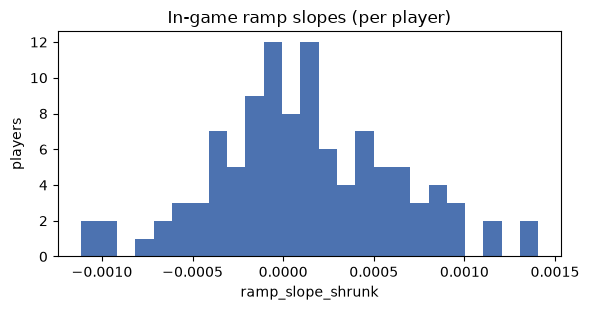

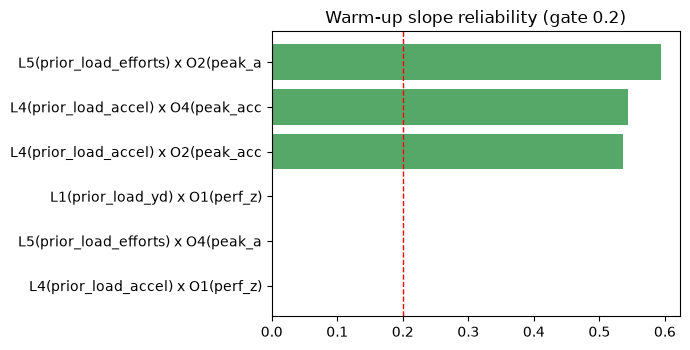

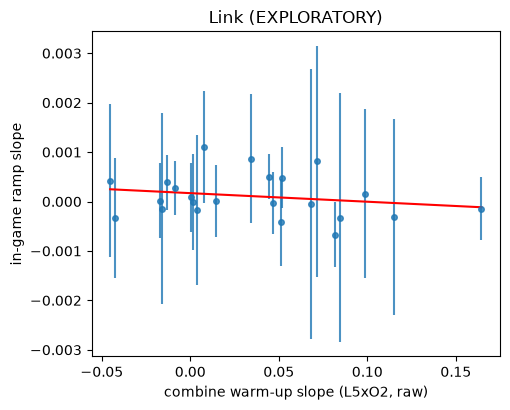

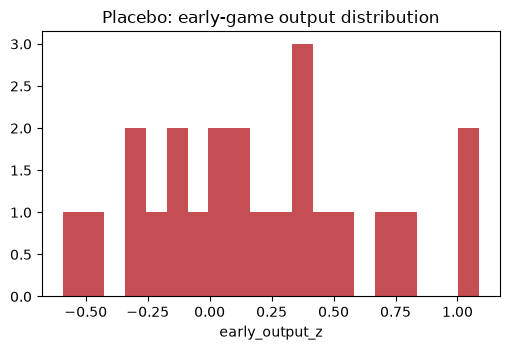

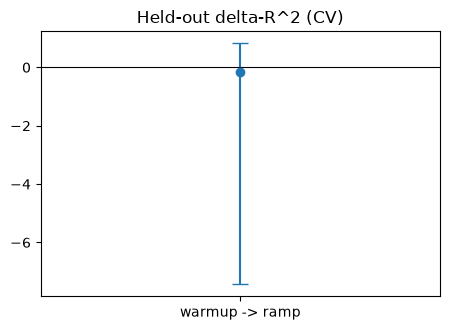

figures saved to /home/conormalone/.openclaw/workspace/BDB27/outputs/figures


In [15]:
%matplotlib inline
import matplotlib.pyplot as plt
FIG = WORK / 'outputs' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
def _save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=120); plt.show()

# Fig 1: in-game ramp-slope distribution
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(game['ramp_slope_shrunk'].dropna(), bins=25, color='#4c72b0')
ax.set_title('In-game ramp slopes (per player)'); ax.set_xlabel('ramp_slope_shrunk'); ax.set_ylabel('players')
_save(fig, 'fig_link_ramp_dist.png')

# Fig 2: warm-up phenotype reliability bars (top cells)
fig, ax = plt.subplots(figsize=(7, 3.6))
w = wrel[wrel['phenotype'].astype(str).str.startswith('warmup_slope')].copy()
w = w.sort_values('reliability', ascending=False).head(8)
ax.barh(w['detail'].astype(str).str.slice(0, 34), w['reliability'], color='#55a868')
ax.axvline(0.2, color='r', ls='--', lw=1); ax.set_title('Warm-up slope reliability (gate 0.2)')
ax.invert_yaxis(); _save(fig, 'fig_link_phenotype_reliability.png')

# Fig 3: link scatter + naive fit
ph = phen[(phen['load_code']=='L5') & (phen['outcome_code']=='O2')][['nfl_id','slope_raw']]
gg = game[['nfl_id','ramp_slope_shrunk','ramp_slope_se']]
m = ph.merge(gg, on='nfl_id').dropna()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.errorbar(m['slope_raw'], m['ramp_slope_shrunk'], yerr=m['ramp_slope_se'], fmt='o', ms=4, alpha=.8)
if len(m) > 2 and m['slope_raw'].nunique() > 1:
    b = np.polyfit(m['slope_raw'], m['ramp_slope_shrunk'], 1)
    xs = np.linspace(m['slope_raw'].min(), m['slope_raw'].max(), 20)
    ax.plot(xs, np.polyval(b, xs), 'r-')
ax.set_xlabel('combine warm-up slope (L5xO2, raw)'); ax.set_ylabel('in-game ramp slope')
ax.set_title('Link (EXPLORATORY)'); _save(fig, 'fig_link_scatter.png')

# Fig 4: placebo
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.hist(m['nfl_id'].map(game.set_index('nfl_id')['early_output_z']).dropna(), bins=20, color='#c44e52')
ax.set_title('Placebo: early-game output distribution'); ax.set_xlabel('early_output_z')
_save(fig, 'fig_link_placebo.png')

# Fig 5: CV delta-R^2 with bootstrap CI
fig, ax = plt.subplots(figsize=(4.6, 3.4))
pt = float(cv['delta_r2_point'].iloc[0]); lo = float(cv['ci_lo'].iloc[0]); hi = float(cv['ci_hi'].iloc[0])
ax.errorbar([0], [pt], yerr=[[pt-lo],[hi-pt]], fmt='o', capsize=6)
ax.axhline(0, color='k', lw=.8); ax.set_xticks([0]); ax.set_xticklabels(['warmup -> ramp'])
ax.set_title('Held-out delta-R^2 (CV)'); _save(fig, 'fig_link_cv_delta_r2.png')
print('figures saved to', FIG)


## 7. How to read this / limitations

- **Reframe (D25).** This notebook tests the *pivot*: reliable combine **warm-up** phenotypes → in-game **ramping**. The pre-registered fatigue-slope→decay link is **GATED OFF** (D20: combine fatigue-slope reliability **0.0**).
- **EXPLORATORY.** The warm-up phenotype de-confounding was **NOT robust** (D24) — the adjusted accel-cell coefficients are not consistently positive at ≥0.5× the raw effect. Do not read this as a confirmatory result.
- **Error-in-both-slopes.** Read `link_results.csv`: the naive OLS is reported *alongside* the inverse-variance-weighted, reliability-corrected estimate (`coef_corrected`). The predictor is the per-player **raw** warm-up slope (`slope_raw`); the EB-shrunken `warmup_slope` collapses to the population mean (EB τ²=0) and is not usable as a predictor.
- **Placebo.** If the phenotype is real, it must **not** predict **early-game** output (`link_placebo.csv`): a significant placebo coefficient would invalidate the link.
- **Cross-validation.** Held-out ΔR² with bootstrap CIs (`link_cv.csv`); a CI spanning 0 (or negative) ⇒ no detectable link.
- **Selection limitation.** Only players who **reached NFL games** have game data; the link is conditional on combine participant AND on-field. See `link_matched_counts.csv`.
- **SAMPLE vs FULL.** In `SAMPLE` mode thresholds are the a-priori placeholders (`PLACEHOLDER_SAMPLE`); the sample is a non-representative prefix — never interpret or tune on it. In `FULL` mode `00_thresholds.py` derives cut-offs from the full game data (`FULL`) and `04`/`05` assert that provenance.
